# Verification of the manuscript *A feedback-driven central limit theorem with q-Gaussian limits*
**G. Baris Bagci and Thomas Oikonomou** — companion notebook to manuscript version 28.

This notebook checks, one by one, the calculations of the manuscript: every identity, every inequality used in the proofs, every explicit constant, and every number that the text quotes about its simulations. It also redraws the tables and figures and repeats the simulations independently. It is meant to be read alongside the manuscript: each check is preceded by a short statement of what the manuscript claims (with its equation, lemma, table or figure number) and of how the claim is tested.

**The model in one paragraph.** Let $\xi_1,\xi_2,\dots$ be i.i.d. noise variables with mean 0 and variance 1. The summands are $X_1=\sqrt c\,\xi_1$ and $X_{n+1}=\sqrt{c+b\,S_n^2/n}\;\xi_{n+1}$, where $S_n=X_1+\dots+X_n$. Each summand is a fresh noise variable whose amplitude is set by the current normalized sum $y=S_n/\sqrt n$; its conditional variance is $D(y)=c+by^2$, and $b$ is the **feedback strength**. The theorem: $S_n/\sqrt n$ converges in distribution to the law $g_b\propto(c+by^2)^{-1-1/(2b)}$, whatever the law of the noise (finite third moment for $b>0$, bounded noise with $|b|K^2\le1$ for $b<0$). For $b>-\tfrac12$ this is the $q$-Gaussian with $q=(1+4b)/(1+2b)$: Student laws with $1<q<2$ for $b>0$ (with infinite variance for $b\ge1$), compactly supported laws with $q<1$ for $-\tfrac12<b<0$, and the Gaussian at $b=0$. The Cauchy law, $q=2$, is reached only in a triangular array in which $b$ grows slowly with the number of terms (Corollary D).

**Structure.** Section 0 sets up the definitions. Sections 1–9 follow the manuscript: the statement (1), the balance identity (2) and its Fourier form (3), the proofs of Theorem A (4) and Theorem B (5), the one-step defect estimate of Appendix A (6), Proposition C and Corollary D (7), Proposition E of Appendix B (8) and two statements of the conclusions (9). Section 10 compares the numbers of the text with the stored simulation data, Section 11 repeats the simulations, Section 12 redraws the tables and figures, and Section 13 lists all results.

**How to run.** Open the notebook in VS Code (Jupyter extension) or JupyterLab with a Python 3 kernel that has `numpy`, `scipy`, `sympy`, `mpmath` and `matplotlib`, and choose *Run All*. **Keep the notebook in the bundle folder**, next to `qclt_manuscript_v28.tex` and the folder `data/`: Sections 10 and 12 read the stored simulation data from `data/` and the printed tables from the `.tex` file (set `BUNDLE` below if the notebook is elsewhere). Figures are shown on screen below the cells; nothing is written to disk. The whole notebook takes about two minutes. Section 11 repeats the simulations with 40,000 paths (`FULL_RUN = False`); with `FULL_RUN = True` it uses the 200,000 paths of the manuscript and takes about ten minutes more. Every check prints `PASS` or `FAIL`; Section 13 collects them.

**What a check can and cannot show.** Algebraic identities are verified symbolically (sympy) or in exact or high-precision arithmetic (mpmath). Inequalities that hold for all values of the variables are proved symbolically where this is easy, and otherwise tested on grids; a pass on a grid is a consistency check, not a proof. Expectations over discrete noise laws are computed exactly. Standard theorems used by the proofs (the duality formula for the Wasserstein distance and the existence of optimal couplings, the portmanteau, Weierstrass and Scheffé theorems, dominated convergence) are not reproved; the formulas and constants derived from them are checked. Simulations agree with each other only within sampling error, and the tolerances used for them are stated.

**Notation in the code.** `b` is the feedback strength, `c` the constant of the conditional variance ($c=1$ in the simulations unless stated otherwise), `kappa` $=1+1/(2b)$, `nu` $=1+1/b$ (degrees of freedom of the Student law), `L` $=\sqrt{c/|b|}$ (half-width of the support for $b<0$), `beta` $=-b$ in Theorem A, and `q` is used only for the index of the $q$-Gaussian. The noise laws are called `pm1` (the values $\pm1$), `three` ($0$ and $\pm\sqrt2$), `two` (the skewed two-point law: $2$ with probability $\tfrac15$, $-\tfrac12$ with probability $\tfrac45$), `unif`, `gauss` and `exp` (centered exponential). Equation, lemma, table and figure numbers are those printed in the manuscript (version 28).

## 0. Setup: the limit law, the constants and the noise laws
Definitions used throughout: $\kappa$, the closed form of $Z_b$ and the density $g_b$ of (II.2); $q(b)$ of (II.3); $\sigma(y)=\sqrt{c+by^2}$; the constant $a_1=\int\sigma g_b$ of Lemma 4(e); $\Lambda$ of (IV.4) and $C_L$ of (IV.7); the noise laws with their third absolute moments $M_3=E|\xi|^3$; the distribution functions of the limit laws used for the Kolmogorov distance. The cell also checks that the data and the manuscript are found.

In [1]:
import os, re, json, math, time, itertools
import numpy as np
import sympy as sp
import mpmath as mp
from mpmath import mpf
from scipy import stats, special, integrate
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
np.set_printoptions(linewidth=140)
mp.mp.dps = 30

BUNDLE = os.path.abspath(".")        # folder of the bundle (contains data/ and qclt_manuscript_v28.tex)
FULL_RUN = False                      # Section 11: True repeats the simulations with the 200,000 paths of the manuscript

DATA = os.path.join(BUNDLE, "data"); TEX = os.path.join(BUNDLE, "qclt_manuscript_v28.tex")
if not (os.path.isdir(DATA) and os.path.isfile(TEX)):
    raise FileNotFoundError("This notebook must be run from the bundle folder, next to qclt_manuscript_v28.tex and the folder data/. "
                            "Move the notebook there, or set BUNDLE to that folder. Looked in: " + BUNDLE)
TEXT = open(TEX, encoding="utf-8").read()

results = {}
def check(name, cond):
    ok = bool(cond)
    results[name] = ok
    print(("PASS   " if ok else "FAIL   ") + name)
    return ok

def close(x, y, tol=1e-8):
    """relative closeness |x - y| <= tol max(1, |y|) (floats, mpmath numbers or complex numbers)"""
    x = mp.mpmathify(complex(x) if isinstance(x, (complex, np.complexfloating)) else x)
    y = mp.mpmathify(complex(y) if isinstance(y, (complex, np.complexfloating)) else y)
    return abs(x - y) <= tol*max(1, abs(y))

R = sp.Rational
def P(r): return mpf(sp.N(r, 40))     # exact number -> 40-digit mpmath number

def kap(b): return 1 + 1/(2*b)
def qOf(b): return (1 + 4*b)/(1 + 2*b)
def sig(y, b, c): return mp.sqrt(c + b*y**2)
def zz(b, c):
    """closed form of Z_b (Eq. II.2)"""
    b, c = mpf(b), mpf(c); k = kap(b)
    if b > 0: return c**(mpf(1)/2 - k)*mp.sqrt(mp.pi/b)*mp.gamma(k - mpf(1)/2)/mp.gamma(k)
    return c**(mpf(1)/2 - k)*mp.sqrt(-mp.pi/b)*mp.gamma(1 - k)/mp.gamma(mpf(3)/2 - k)
def gb(y, b, c):
    """the limit density g_b (Eq. II.2), b != 0"""
    y, b, c = mpf(y), mpf(b), mpf(c)
    if b > 0 or y**2 < -c/b: return (c + b*y**2)**(-kap(b))/zz(b, c)
    return mpf(0)
def a1Of(b, c):
    """a_1 = int sigma g_b (Lemma 4(e)), closed form of the proof of Corollary D (a)"""
    k = kap(mpf(b)); return mp.sqrt(c)*mp.gamma(k - 1)*mp.gamma(k)/mp.gamma(k - mpf(1)/2)**2
def lamOf(b, m3):
    """Lambda of (IV.4)"""
    return mp.exp(4*mp.sqrt(2)*mpf(b)**mpf(1.5)*m3*(mp.zeta(1.5) - 1))
def clOf(b, c, m3):
    """C_L of (IV.7)"""
    b = mpf(b); return a1Of(b, c)*m3*(33 + 83*b/2 + 6/b)

atoms = {"pm1": [(1, R(1, 2)), (-1, R(1, 2))],
         "two": [(2, R(1, 5)), (R(-1, 2), R(4, 5))],
         "three": [(-sp.sqrt(2), R(1, 4)), (0, R(1, 2)), (sp.sqrt(2), R(1, 4))]}
def ev(k, f):
    """exact expectation of f(xi) for a discrete noise law (sympy)"""
    return sp.nsimplify(0) + sum(p*f(v) for v, p in atoms[k])
natoms = {k: [(float(v), float(p)) for v, p in atoms[k]] for k in atoms}
m3 = {"pm1": mpf(1), "two": mpf(17)/10, "three": mp.sqrt(2), "unif": 3*mp.sqrt(3)/4,
      "gauss": 2*mp.sqrt(2/mp.pi), "exp": 12/mp.e - 2}

def cdfG(b, y, c=1.0):
    """distribution function of g_b (Student for b > 0, Gaussian for b = 0, Beta for b < 0), vectorized"""
    y = np.asarray(y, float)
    if b > 0: return stats.t.cdf(y/np.sqrt(c/(1 + b)), 1 + 1/b)
    if b == 0: return stats.norm.cdf(y/np.sqrt(c))
    a = -1/(2*b); L = np.sqrt(-c/b)
    return stats.beta.cdf((np.clip(y/L, -1, 1) + 1)/2, a, a)
def pdfG(b, y, c=1.0):
    y = np.asarray(y, float)
    if b > 0: s = np.sqrt(c/(1 + b)); return stats.t.pdf(y/s, 1 + 1/b)/s
    if b == 0: return stats.norm.pdf(y/np.sqrt(c))/np.sqrt(c)
    a = -1/(2*b); L = np.sqrt(-c/b)
    return np.where(np.abs(y) < L, stats.beta.pdf((np.clip(y/L, -1, 1) + 1)/2, a, a)/(2*L), 0.0)
def quantG(b, p, c=1.0):
    if b > 0: return np.sqrt(c/(1 + b))*stats.t.ppf(p, 1 + 1/b)
    if b == 0: return np.sqrt(c)*stats.norm.ppf(p)
    a = -1/(2*b); L = np.sqrt(-c/b); return L*(2*stats.beta.ppf(p, a, a) - 1)

def load(name): return json.load(open(os.path.join(DATA, name)))
colB, colO, colA, colP = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cc7"
bs, cs, ys, ts = sp.symbols('b c y t', real=True)
bp, cp, yp, tp, np_ = sp.symbols('b c y t n', positive=True)
print("bundle found:", BUNDLE)

bundle found: /Users/barisbagci/Desktop/QCLT_manuscript_v28


## 1. Sec. II A: the statement (Eqs. II.1–II.4, Table I, Fig. 1)
The **main theorem** states that $S_n/\sqrt n$ converges to $g_b(y)=Z_b^{-1}(c+by^2)^{-\kappa}$, $\kappa=1+1/(2b)$, on the interval $I_b$ where $D(y)=c+by^2>0$ (the Gaussian with variance $c$ if $b=0$). This section checks the formulas of the statement: the normalizing constant, the $q$-Gaussian form and the two standard forms (Student and Beta), the table of regimes, and the normalized recursion (II.4).

**Claim (II.2).** $Z_b=\int_{I_b}D^{-\kappa}\,dy$ has the closed form $c^{1/2-\kappa}\sqrt{\pi/b}\;\Gamma(\kappa-\tfrac12)/\Gamma(\kappa)$ for $b>0$ and $c^{1/2-\kappa}\sqrt{\pi/|b|}\;\Gamma(1-\kappa)/\Gamma(\tfrac32-\kappa)$ for $b<0$, where $I_b=(-L,L)$, $L=\sqrt{c/|b|}$.

**How it is checked.** Closed form against numerical integration (mpmath, 30 digits) for six values of $b$ and two of $c$.

In [2]:
bList = [R(1, 3), 1, 2, R(-1, 4), R(-1, 2), -1]
def zNum(b, c):
    b, c = P(b), P(c); k = kap(b)
    if b > 0: return mp.quad(lambda y: (c + b*y**2)**(-k), [-mp.inf, 0, mp.inf])
    L = mp.sqrt(-c/b); return 2*mp.quad(lambda y: (c + b*y**2)**(-k), [0, L])
check("(II.2): the closed form of Z_b equals the integral of D^(-kappa) (b = 1/3, 1, 2, -1/4, -1/2, -1; c = 1, 23/10)",
      all(close(zz(P(b), P(c)), zNum(b, c), 1e-10) for b in bList for c in (1, R(23, 10))))

PASS   (II.2): the closed form of Z_b equals the integral of D^(-kappa) (b = 1/3, 1, 2, -1/4, -1/2, -1; c = 1, 23/10)


True

**Claim (Sec. II A, notation paragraph).** $Z_b$ is finite: for $b>0$ the integrand is at most $c^{-\kappa}$ and decays like $|y|^{-2\kappa}=|y|^{-2-1/b}$; for $b<0$ it equals $|b|^{-\kappa}[(L-y)(L+y)]^{1/(2|b|)-1}$, whose exponent exceeds $-1$.

**How it is checked.** Symbolically: $2\kappa=2+1/b$, $-\kappa=1/(2|b|)-1$ for $b<0$, and $c+by^2=|b|(L-y)(L+y)$; the inequality $1/(2|b|)-1>-1$ is immediate.

In [3]:
bn = sp.symbols('beta', positive=True)        # beta = |b| for b < 0
kS = 1 + 1/(2*bs); Lb = sp.sqrt(cp/bn)
check("Sec. II A: 2 kappa = 2 + 1/b; for b = -beta < 0, -kappa = 1/(2 beta) - 1 > -1 and c + b y^2 = beta (L - y)(L + y)",
      sp.simplify(2*kS - (2 + 1/bs)) == 0 and sp.simplify(-kS.subs(bs, -bn) - (1/(2*bn) - 1)) == 0
      and sp.simplify(cp - bn*yp**2 - bn*(Lb - yp)*(Lb + yp)) == 0)

PASS   Sec. II A: 2 kappa = 2 + 1/b; for b = -beta < 0, -kappa = 1/(2 beta) - 1 > -1 and c + b y^2 = beta (L - y)(L + y)


True

**Claim (II.3).** For $b>-\tfrac12$, $g_b\propto[1-(1-q)By^2]_+^{1/(1-q)}$ with $q=(1+4b)/(1+2b)$ and $B=(1+2b)/(2c)$. The text derives this from $1-q=-2b/(1+2b)$, hence $(1-q)B=-b/c$ and $1/(1-q)=-\kappa$, so that $[1-(1-q)By^2]^{1/(1-q)}=c^{\kappa}D^{-\kappa}$; conversely $b=(q-1)/(2(2-q))$.

**How it is checked.** The identities symbolically, and the ratio of $g_b$ to the $q$-Gaussian at several points (it must not depend on $y$).

In [4]:
qS = (1 + 4*bs)/(1 + 2*bs); BS = (1 + 2*bs)/(2*cs)
check("(II.3): 1 - q = -2b/(1+2b), (1-q) B = -b/c and 1/(1-q) = -kappa, with q = (1+4b)/(1+2b) and B = (1+2b)/(2c)",
      sp.simplify(1 - qS + 2*bs/(1 + 2*bs)) == 0 and sp.simplify((1 - qS)*BS + bs/cs) == 0 and sp.simplify(1/(1 - qS) + kS) == 0)
check("(II.3): the inverse relation b = (q-1)/(2(2-q))", sp.simplify((qS - 1)/(2*(2 - qS)) - bs) == 0)
check("(II.3): [1-(1-q) B y^2]^(1/(1-q)) = c^kappa D^(-kappa) (symbolic, for c + b y^2 > 0)",
      sp.simplify(sp.powsimp(sp.expand_power_base((1 - (1 - qS)*BS*ys**2)**(-kS)*(cs + bs*ys**2)**kS*cs**(-kS), force=True), force=True)) == 1)
def qgRatio(b, c, y):
    b, c = P(b), P(c); q = qOf(b); B = (1 + 2*b)/(2*c)
    return gb(y, b, c)/(1 - (1 - q)*B*mpf(y)**2)**(1/(1 - q))
check("(II.3): g_b / [1-(1-q) B y^2]^(1/(1-q)) does not depend on y (b = 1/3, 1, 2, -1/4, -1/3; c = 1, 23/10)",
      all(close(qgRatio(b, c, y), gb(0, P(b), P(c)), 1e-12) for b in (R(1, 3), 1, 2, R(-1, 4), R(-1, 3))
          for c in (1, R(23, 10)) for y in (0.2, 0.5, 0.9)))

PASS   (II.3): 1 - q = -2b/(1+2b), (1-q) B = -b/c and 1/(1-q) = -kappa, with q = (1+4b)/(1+2b) and B = (1+2b)/(2c)
PASS   (II.3): the inverse relation b = (q-1)/(2(2-q))
PASS   (II.3): [1-(1-q) B y^2]^(1/(1-q)) = c^kappa D^(-kappa) (symbolic, for c + b y^2 > 0)
PASS   (II.3): g_b / [1-(1-q) B y^2]^(1/(1-q)) does not depend on y (b = 1/3, 1, 2, -1/4, -1/3; c = 1, 23/10)


True

**Claim (Sec. II A).** For $b>0$, $g_b$ is the law of $\sqrt{c/(1+b)}\,T_\nu$, with $T_\nu$ Student's law with $\nu=1+1/b$ degrees of freedom; for $b<0$ it is the law of $L(2V-1)$ with $V\sim\mathrm{Beta}(1/(2|b|),1/(2|b|))$.

**How it is checked.** Pointwise comparison with the densities of `scipy.stats`.

In [5]:
check("Sec. II A: for b > 0, g_b is the law of Sqrt[c/(1+b)] T_nu, nu = 1 + 1/b (b = 1/3, 1, 2; c = 1, 23/10)",
      all(close(gb(y, P(b), P(c)), stats.t.pdf(y/math.sqrt(float(c)/(1 + float(b))), 1 + 1/float(b))/math.sqrt(float(c)/(1 + float(b))), 1e-10)
          for b in (R(1, 3), 1, 2) for c in (1, R(23, 10)) for y in (-3.5, -1, 0, 1/3, 5)))
def betaForm(b, c, u):
    b, c = P(b), P(c); a = -1/(2*b); L = mp.sqrt(-c/b)
    return gb(u*L, b, c), stats.beta.pdf((u + 1)/2, float(a), float(a))/(2*float(L))
check("Sec. II A: for b < 0, g_b is the law of L(2V-1), V ~ Beta(1/(2|b|), 1/(2|b|)) (b = -1/4, -1/2, -1, -5/2; c = 1, 23/10)",
      all(close(*betaForm(b, c, u), 1e-10) for b in (R(-1, 4), R(-1, 2), -1, R(-5, 2)) for c in (1, R(23, 10)) for u in (-0.5, 0, 1/7, 0.6)))

PASS   Sec. II A: for b > 0, g_b is the law of Sqrt[c/(1+b)] T_nu, nu = 1 + 1/b (b = 1/3, 1, 2; c = 1, 23/10)
PASS   Sec. II A: for b < 0, g_b is the law of L(2V-1), V ~ Beta(1/(2|b|), 1/(2|b|)) (b = -1/4, -1/2, -1, -5/2; c = 1, 23/10)


True

**Claim (Table I).** The regimes: $b>0$ gives $1<q<2$ (Student laws, finite variance iff $b<1$); $b=0$ the Gaussian; $-\tfrac12<b<0$ compactly supported $q$-Gaussians with $q<1$; $b=-\tfrac12$ ($q\to-\infty$) the uniform law; $-1\le b<-\tfrac12$ U-shaped laws, the arcsine law at $b=-1$; the Cauchy law $q=2$ only as $b\to\infty$ in a triangular array.

**How it is checked.** Values of $q$ and $\kappa$; the arcsine and uniform densities at $b=-1$ and $b=-\tfrac12$; the variance $c/(1-b)$ by numerical integration; for $-1\le b<-\tfrac12$ the density increases with $|y|$ (U shape), since $g_b'=-2\kappa by\,g_b/D$ with $\kappa\ge0$ and $b<0$. The ranges of $q$ are checked in Section 7 (Proposition C).

In [6]:
check("Table I: q(-1/4) = 0, q(1/3) = 7/5, q(1) = 5/3, q(2) = 9/5; kappa(-1/2) = 0 (uniform), kappa(-1) = 1/2 (arcsine)",
      qOf(R(-1, 4)) == 0 and qOf(R(1, 3)) == R(7, 5) and qOf(R(1)) == R(5, 3) and qOf(R(2)) == R(9, 5) and kap(R(-1, 2)) == 0 and kap(R(-1)) == R(1, 2))
check("Table I: b = -1 gives the arcsine density 1/(Pi Sqrt[c - y^2]); b = -1/2 gives the uniform density 1/(2L) (c = 2)",
      all(close(gb(y, -1, 2), 1/(mp.pi*mp.sqrt(2 - mpf(y)**2))) and close(gb(y, mpf(-1)/2, 2), mpf(1)/4) for y in (-1, 0, 1/3, 5/4)))
def varNum(b, c):
    b, c = P(b), P(c)
    if b > 0: return 2*mp.quad(lambda y: y**2*gb(y, b, c), [0, 1, 10, mp.inf])
    L = mp.sqrt(-c/b); return 2*mp.quad(lambda y: y**2*(c + b*y**2)**(-kap(b))/zz(b, c), [0, L])
check("Table I: the variance of g_b is c/(1-b) for b < 1 (b = 1/3, 1/2, -1/4, -1/2, -1; c = 1, 23/10)",
      all(close(varNum(b, c), P(c)/(1 - P(b)), 1e-8) for b in (R(1, 3), R(1, 2), R(-1, 4), R(-1, 2), -1) for c in (1, R(23, 10))))
check("Table I: for -1 <= b < -1/2 the density is U-shaped: g_b' = -2 kappa b y g_b/D has the sign of y, since kappa = 1 + 1/(2b) lies in (0, 1/2]",
      sp.simplify(sp.diff((cs + bs*ys**2)**(-kS), ys) + 2*kS*bs*ys*(cs + bs*ys**2)**(-kS)/(cs + bs*ys**2)) == 0
      and all(0 < kap(b) <= R(1, 2) for b in (R(-1), R(-9, 10), R(-3, 4), R(-11, 20)))
      and all(gb(0.9*float(mp.sqrt(-1/P(b))), P(b), 1) > gb(0.5*float(mp.sqrt(-1/P(b))), P(b), 1) > gb(0, P(b), 1) for b in (R(-1), R(-3, 4), R(-11, 20))))

PASS   Table I: q(-1/4) = 0, q(1/3) = 7/5, q(1) = 5/3, q(2) = 9/5; kappa(-1/2) = 0 (uniform), kappa(-1) = 1/2 (arcsine)
PASS   Table I: b = -1 gives the arcsine density 1/(Pi Sqrt[c - y^2]); b = -1/2 gives the uniform density 1/(2L) (c = 2)
PASS   Table I: the variance of g_b is c/(1-b) for b < 1 (b = 1/3, 1/2, -1/4, -1/2, -1; c = 1, 23/10)
PASS   Table I: for -1 <= b < -1/2 the density is U-shaped: g_b' = -2 kappa b y g_b/D has the sign of y, since kappa = 1 + 1/(2b) lies in (0, 1/2]


True

**Claim (II.4).** Dividing $S_{n+1}=S_n+X_{n+1}$ by $\sqrt{n+1}$ gives $Y_{n+1}=\rho_nY_n+\varepsilon_n\sigma(Y_n)\xi_{n+1}$ with $\rho_n=\sqrt{n/(n+1)}$, $\varepsilon_n=1/\sqrt{n+1}$ and $\rho_n^2+\varepsilon_n^2=1$.

**How it is checked.** Both sides evaluated in 30-digit arithmetic on a grid of $n$, $S_n$, $\xi$, $b$, $c$.

In [7]:
def recOK(n, s, x, b, c):
    n, s, x, b, c = map(mpf, (n, s, x, b, c))
    lhs = (s + mp.sqrt(c + b*s**2/n)*x)/mp.sqrt(n + 1)
    rhs = mp.sqrt(n/(n + 1))*(s/mp.sqrt(n)) + sig(s/mp.sqrt(n), b, c)*x/mp.sqrt(n + 1)
    return close(lhs, rhs, 1e-25)
check("(II.4): dividing (II.1) by Sqrt[n+1] gives Y_(n+1) = rho_n Y_n + eps_n sigma(Y_n) xi, and rho_n^2 + eps_n^2 = 1",
      all(recOK(n, s, x, b, c) for n in (1, 2, 7, 100) for s in (-1.5, 0.2, 2) for x in (-1, 2/3) for b in (-0.1, 1/3, 2) for c in (1, 2.3))
      and sp.simplify(np_/(np_ + 1) + 1/(np_ + 1) - 1) == 0)

PASS   (II.4): dividing (II.1) by Sqrt[n+1] gives Y_(n+1) = rho_n Y_n + eps_n sigma(Y_n) xi, and rho_n^2 + eps_n^2 = 1


True

**Claim (main theorem, assumptions).** For $b<0$ the noise must satisfy $|\xi_1|\le K$ with $|b|K^2\le1$, "so that the conditional variance stays nonnegative"; for the Cauchy limit the admissible $\theta$ is bounded by $[8\sqrt2(\zeta(\tfrac32)-1)E|\xi_1|^3]^{-1}$, the constant $\theta_*$ of (II.6).

**How it is checked.** The first statement is proved in Theorem A and checked in Section 4; here we check that the bound on $\theta$ in the main theorem and $\theta_*$ in (II.6) are the same number, $\approx0.0548/M_3$, and that the bound of (II.6) is printed as $0.0548/M_3$.

In [8]:
thetaStar = 1/(8*mp.sqrt(2)*(mp.zeta(1.5) - 1))
check("Main theorem and (II.6): theta_* = 1/(8 Sqrt[2] (Zeta(3/2) - 1) M3) = 0.0548/M3",
      abs(thetaStar - mpf("0.0548")) < 5e-5 and r"\approx\frac{0.0548}{M_3}" in TEXT)

PASS   Main theorem and (II.6): theta_* = 1/(8 Sqrt[2] (Zeta(3/2) - 1) M3) = 0.0548/M3


True

**Claim (Fig. 1 and its description in Sec. II A).** The ten panels show one case for each interval and each boundary value of $q$: $b=-1$ (no $q$), $b=-\tfrac12$ ($q\to-\infty$), $b=-\tfrac13$ ($q=-1<0$), $b=-\tfrac14$ ($q=0$), $b=-\tfrac16$ ($q=\tfrac12\in(0,1)$), $b=0$ ($q=1$), $b=\tfrac13$ ($q=\tfrac75\in(1,\tfrac53)$, finite variance), $b=1$ ($q=\tfrac53$), $b=2$ ($q=\tfrac95\in(\tfrac53,2)$), and panel (j) with $b=50$, $c=1+b$ for $q=2$.

**How it is checked.** The values of $q$; the finite variance for $b=\tfrac13$ ($b<1$) and its absence for $b=1,2$; the noise bound $|b|K^2\le1$ for the bounded noise laws used with $b<0$ (noise $\pm1$: $K=1$; three-point: $K=\sqrt2$; uniform: $K=\sqrt3$; skewed two-point: $K=2$). The statement that $g_{50}$ is within $0.002$ of the Cauchy law is checked in Section 7.

In [9]:
panels = [(R(-1), "pm1", 1), (R(-1, 2), "three", 2), (R(-1, 3), "three", 2), (R(-1, 4), "two", 4), (R(-1, 6), "unif", 3)]
check("Fig. 1: q = -1, 0, 1/2, 7/5, 5/3, 9/5 for b = -1/3, -1/4, -1/6, 1/3, 1, 2, and q(b) -> -Infinity as b -> -1/2 from above",
      [qOf(b) for b in (R(-1, 3), R(-1, 4), R(-1, 6), R(1, 3), R(1), R(2))] == [-1, 0, R(1, 2), R(7, 5), R(5, 3), R(9, 5)]
      and sp.limit(qS, bs, R(-1, 2), '+') == -sp.oo)
check("Fig. 1: the bounded noise laws used for b < 0 satisfy |b| K^2 <= 1 (pm1 with b = -1, three-point with b = -1/2, -1/3, skewed two-point with b = -1/4, uniform with b = -1/6)",
      all(-b*K2 <= 1 for b, k, K2 in panels))

PASS   Fig. 1: q = -1, 0, 1/2, 7/5, 5/3, 9/5 for b = -1/3, -1/4, -1/6, 1/3, 1, 2, and q(b) -> -Infinity as b -> -1/2 from above
PASS   Fig. 1: the bounded noise laws used for b < 0 satisfy |b| K^2 <= 1 (pm1 with b = -1, three-point with b = -1/2, -1/3, skewed two-point with b = -1/4, uniform with b = -1/6)


True

## 2. Sec. II C: the balance identity (Lemma 1, Eq. II.7) and the diffusion behind it
**Lemma 1** is the identity on which both proofs rest: $(D\,g_b)'=-y\,g_b$ on $I_b$, with $D\,g_b\to0$ at both ends of $I_b$. The text explains it as a balance: the normalization contracts $Y_n$ by $\rho_n\approx1-\tfrac1{2(n+1)}$, the next summand spreads it with variance $D(Y_n)/(n+1)$, and a density is unchanged to first order exactly when $\tfrac12(Dg)''+\tfrac12(yg)'=0$.

**Claim (II.7).** $(Dg_b)'=-y\,g_b$. The proof uses $Dg_b=Z_b^{-1}D^{1-\kappa}$, $1-\kappa=-1/(2b)$ and $D'=2by$.

**How it is checked.** Symbolically in $b$, $c$, $y$ (the constant $Z_b$ cancels).

In [10]:
Dsym = cs + bs*ys**2; gsym = Dsym**(-kS)
check("(II.7), Lemma 1: (D g_b)' = -y g_b, symbolically in b, c, y",
      sp.simplify(sp.diff(Dsym*gsym, ys) + ys*gsym) == 0 and sp.simplify(1 - kS + 1/(2*bs)) == 0)
check("Sec. II C: (II.7) implies (1/2)(D g)'' + (1/2)(y g)' = 0",
      sp.simplify(sp.powsimp(sp.expand((sp.diff(Dsym*gsym, ys, 2)/2 + sp.diff(ys*gsym, ys)/2)*Dsym**kS), force=True)) == 0)

PASS   (II.7), Lemma 1: (D g_b)' = -y g_b, symbolically in b, c, y
PASS   Sec. II C: (II.7) implies (1/2)(D g)'' + (1/2)(y g)' = 0


True

**Claim (Lemma 1, boundary values).** $D\,g_b=Z_b^{-1}D^{-1/(2b)}\to0$ as $|y|\to\infty$ for $b>0$, and $D\,g_b=Z_b^{-1}D^{1/(2|b|)}\to0$ as $|y|\to L$ for $b<0$, because $D(\pm L)=0$.

**How it is checked.** Symbolic limits for $b=\tfrac13,1,2$ and exact evaluation at $y=L$ for $b=-\tfrac14,-\tfrac12,-1$.

In [11]:
check("Lemma 1: D g_b -> 0 at the ends of I_b (b = 1/3, 1, 2 at infinity; b = -1/4, -1/2, -1 at y = L, c = 1, 23/10)",
      all(sp.limit((1 + b*ys**2)**(-1/(2*b)), ys, sp.oo) == 0 for b in (R(1, 3), R(1), R(2)))
      and all(sp.simplify(((c + b*ys**2)**(-1/(2*b))).subs(ys, sp.sqrt(-c/b))) == 0 for b in (R(-1, 4), R(-1, 2), R(-1)) for c in (1, R(23, 10))))

PASS   Lemma 1: D g_b -> 0 at the ends of I_b (b = 1/3, 1, 2 at infinity; b = -1/4, -1/2, -1 at y = L, c = 1, 23/10)


True

**Claim (Sec. II C, diffusion).** The first-order condition is the stationary Fokker–Planck equation of $dU_t=-\tfrac12U_t\,dt+\sigma(U_t)\,d\mathcal W_t$, and (II.7) says that its probability current $-\tfrac12yg-\tfrac12(Dg)'$ vanishes for $g_b$. Moreover $\rho_n=1-1/(2(n+1))+O(n^{-2})$, so that (II.4) is a discretization of this diffusion with step $1/(n+1)$.

**How it is checked.** The current symbolically; the expansion of $\rho_n$ through the limit $n^2\big(\rho_n-1+\tfrac1{2(n+1)}\big)\to-\tfrac18$.

In [12]:
check("Sec. II C: the probability current -(1/2) y g_b - (1/2)(D g_b)' of dU = -U/2 dt + sigma(U) dW vanishes identically",
      sp.simplify(-ys*gsym/2 - sp.diff(Dsym*gsym, ys)/2) == 0)
check("Sec. II C: rho_n = 1 - 1/(2(n+1)) + O(n^-2), since n^2 (rho_n - 1 + 1/(2(n+1))) -> -1/8",
      sp.limit(np_**2*(sp.sqrt(np_/(np_ + 1)) - 1 + 1/(2*(np_ + 1))), np_, sp.oo) == R(-1, 8))

PASS   Sec. II C: the probability current -(1/2) y g_b - (1/2)(D g_b)' of dU = -U/2 dt + sigma(U) dW vanishes identically
PASS   Sec. II C: rho_n = 1 - 1/(2(n+1)) + O(n^-2), since n^2 (rho_n - 1 + 1/(2(n+1))) -> -1/8


True

**Claim (Sec. II C, the result on stochastic-approximation recursions).** The conditions of that result are met for $0<b<1$ under the assumptions of Theorem B: the diffusion coefficient $\sigma$ is Lipschitz (with constant $\sqrt b$) and nonvanishing ($\sigma\ge\sqrt c$), and the Lyapunov expression $2y\cdot(-\tfrac12y)+D(y)=c-(1-b)y^2$ is at most a constant minus a positive multiple of $y^2$ exactly when $b<1$.

**How it is checked.** The Lyapunov expression symbolically; for $b<1$ the bound $c-(1-b)y^2\le c-\tfrac{1-b}{2}y^2$, and for $b\ge1$ the impossibility of any bound $c_1-c_0y^2$ with $c_0>0$ (the difference grows like $y^2$). The Lipschitz and lower bounds of $\sigma$ are Lemma 4(a),(b), checked in Section 5.

In [13]:
check("Sec. II C: 2 y (-y/2) + D(y) = c - (1-b) y^2; for b < 1 it is <= c - (1-b) y^2/2, and for b >= 1 no bound c1 - c0 y^2 with c0 > 0 holds",
      sp.simplify(2*ys*(-ys/2) + Dsym - (cs - (1 - bs)*ys**2)) == 0
      and all(sp.simplify((1 - (1 - b)*ys**2) - (1 - (1 - b)/2*ys**2) + (1 - b)/2*ys**2) == 0 and 1 - b > 0 for b in (0, R(1, 3), R(9, 10)))
      and all(sp.limit((1 - (1 - b)*ys**2) - (c1 - c0*ys**2), ys, sp.oo) == sp.oo for b in (1, 2) for c0 in (R(1, 100), 1) for c1 in (1, 100)))

PASS   Sec. II C: 2 y (-y/2) + D(y) = c - (1-b) y^2; for b < 1 it is <= c - (1-b) y^2/2, and for b >= 1 no bound c1 - c0 y^2 with c0 > 0 holds


True

## 3. Sec. II D: the Fourier form of the identity (Eqs. II.8–II.11, Table II)
Sec. II D compares the classical Fourier derivation of the Gaussian limit with a one-step Fourier computation for the feedback-driven sums. For $b=0$ the characteristic function of $S_n/\sqrt n$ is a product, (II.8). For $b\ne0$ it does not factorize, but conditioning on $Y_n$ gives the exact step (II.9); its expansion to first order in $1/n$, (II.10), closes on $\varphi_n=E[e^{itY_n}]$ because $D$ is quadratic, and its fixed points solve the Bessel-type equation (II.11), whose bounded solutions are the characteristic functions of the limit laws $g_b$. The text stresses that this derivation is formal and identifies the limit; the convergence proofs are those of Secs. III and IV.

Several checks below use the **exact law of $Y_n$** for a discrete noise law, obtained by enumerating all noise sequences ($2^n$ atoms for a two-point law). Nothing is sampled.

In [14]:
def lawY(b, c, k, n):
    """exact law of Y_n = S_n/Sqrt[n] for the discrete noise law k: arrays of values and probabilities"""
    xs = np.array([v for v, p in natoms[k]]); ps = np.array([p for v, p in natoms[k]])
    y, w = np.sqrt(c)*xs, ps.copy()
    for m in range(1, n):
        rho, e = math.sqrt(m/(m + 1)), 1/math.sqrt(m + 1)
        s = np.sqrt(np.maximum(c + b*y**2, 0.0))
        y = (rho*y[:, None] + e*s[:, None]*xs[None, :]).ravel(); w = (w[:, None]*ps[None, :]).ravel()
    return y, w
def phiXi(k, u):
    """characteristic function of the discrete noise law k"""
    return sum(p*np.exp(1j*u*v) for v, p in natoms[k])

**Claim (II.8).** For $b=0$ the summands $\sqrt c\,\xi_n$ are independent, so $E[e^{itS_n/\sqrt n}]=\varphi_\xi(\sqrt c\,t/\sqrt n)^n=\big(1-\tfrac{ct^2}{2n}+o(\tfrac1n)\big)^n\to e^{-ct^2/2}$.

**How it is checked.** (a) The product formula against the exact law of $S_n/\sqrt n$ (enumeration, $b=0$, skewed two-point noise, $n=12$); (b) the expansion $\varphi_\xi(u)=1-\tfrac12u^2+O(u^3)$ for a law with mean 0 and variance 1 (sympy series of $\varphi_\xi$ for the skewed two-point law); (c) the limit: $n\ln(1-ct^2/(2n))\to-ct^2/2$ symbolically, and $\varphi_\xi(\sqrt c\,t/\sqrt n)^n$ at $n=10^8$ within $10^{-3}$ of $e^{-ct^2/2}$ (for the skewed law the difference is of order $E\xi^3\,t^3/\sqrt n$).

In [15]:
y12, w12 = lawY(0.0, 1.3, "two", 12)
uS = sp.symbols('u', real=True)
phiTwo = sum(p*sp.exp(sp.I*uS*v) for v, p in atoms["two"])
check("(II.8): for b = 0, E exp(i t S_n/Sqrt[n]) = phi_xi(Sqrt[c] t/Sqrt[n])^n (exact law, skewed two-point noise, n = 12, c = 13/10)",
      all(abs(np.sum(w12*np.exp(1j*t*y12)) - phiXi("two", math.sqrt(1.3)*t/math.sqrt(12))**12) < 1e-12 for t in (0.3, 1.1, 2.7)))
check("(II.8): phi_xi(u) = 1 - u^2/2 + O(u^3) for a law with mean 0 and variance 1 (skewed two-point law, series), and n ln(1 - c t^2/(2n)) -> -c t^2/2",
      sp.simplify(sp.series(phiTwo, uS, 0, 3).removeO() - (1 - uS**2/2)) == 0
      and sp.limit(np_*sp.log(1 - cp*tp**2/(2*np_)), np_, sp.oo) == -cp*tp**2/2)
check("(II.8): phi_xi(Sqrt[c] t/Sqrt[n])^n is within 1e-3 of exp(-c t^2/2) at n = 10^8 (noise +1/-1 and skewed two-point; c = 1, 13/10; t = 1/2, 1, 2)",
      all(abs(phiXi(k, math.sqrt(c)*t/1e4)**100000000 - math.exp(-c*t*t/2)) < 1e-3 for k in ("pm1", "two") for c in (1, 1.3) for t in (0.5, 1, 2)))

PASS   (II.8): for b = 0, E exp(i t S_n/Sqrt[n]) = phi_xi(Sqrt[c] t/Sqrt[n])^n (exact law, skewed two-point noise, n = 12, c = 13/10)
PASS   (II.8): phi_xi(u) = 1 - u^2/2 + O(u^3) for a law with mean 0 and variance 1 (skewed two-point law, series), and n ln(1 - c t^2/(2n)) -> -c t^2/2
PASS   (II.8): phi_xi(Sqrt[c] t/Sqrt[n])^n is within 1e-3 of exp(-c t^2/2) at n = 10^8 (noise +1/-1 and skewed two-point; c = 1, 13/10; t = 1/2, 1, 2)


True

**Claim (II.9).** Since $\xi_{n+1}$ is independent of $Y_n$, conditioning on $Y_n$ in (II.4) gives the *exact* relation $\varphi_{n+1}(t)=E\big[e^{it\rho_nY_n}\varphi_\xi(t\varepsilon_n\sigma(Y_n))\big]$.

**How it is checked.** Both sides from the exact laws of $Y_n$ and $Y_{n+1}$ (enumeration; $b=\tfrac13$ and $b=-\tfrac14$, skewed two-point noise, $n=9$).

In [16]:
def stepRHS(b, c, k, y, w, n, t):
    rho, e = math.sqrt(n/(n + 1)), 1/math.sqrt(n + 1)
    return np.sum(w*np.exp(1j*t*rho*y)*phiXi(k, t*e*np.sqrt(np.maximum(c + b*y**2, 0))))
check("(II.9): phi_(n+1)(t) = E[exp(i t rho_n Y_n) phi_xi(t eps_n sigma(Y_n))] exactly (b = 1/3, -1/4; skewed two-point noise; n = 9; t = 0.4, 1.7, 5)",
      all(abs(np.sum(lawY(b, 1.0, "two", 10)[1]*np.exp(1j*t*lawY(b, 1.0, "two", 10)[0])) - stepRHS(b, 1.0, "two", *lawY(b, 1.0, "two", 9), 9, t)) < 1e-12
          for b in (1/3, -0.25) for t in (0.4, 1.7, 5.0)))

PASS   (II.9): phi_(n+1)(t) = E[exp(i t rho_n Y_n) phi_xi(t eps_n sigma(Y_n))] exactly (b = 1/3, -1/4; skewed two-point noise; n = 9; t = 0.4, 1.7, 5)


True

**Claim (II.10).** Inserting $\varphi_\xi(u)=1-\tfrac12u^2+O(|u|^3)$ and $\rho_n=1-\tfrac12\varepsilon_n^2+O(n^{-2})$, $\varepsilon_n^2=1/(n+1)$, and using $E[Y_n e^{itY_n}]=-i\varphi_n'$, $E[Y_n^2e^{itY_n}]=-\varphi_n''$, one gets to first order in $1/n$
$$\varphi_{n+1}=\varphi_n-\frac{1}{2(n+1)}\Big[t\varphi_n'+t^2\big(c\varphi_n-b\varphi_n''\big)\Big]+\dots$$
The first term of the bracket comes from the contraction, the second from the spreading; the noise enters only through its variance. The text adds that the third moment of the noise enters at the next order, $n^{-3/2}$, through $\sigma^3=D^{3/2}$, which is not a polynomial.

**How it is checked.** (a) Symbolically: the expansion of $e^{it\rho y}\,\varphi_\xi(t\varepsilon\sigma(y))$ in $\varepsilon$, with $\rho=\sqrt{1-\varepsilon^2}$ and $\varphi_\xi(u)=1-\tfrac{u^2}{2}-i\,m_3'\tfrac{u^3}{6}+\dots$ ($m_3'=E\xi^3$), has the $\varepsilon^2$-coefficient $e^{ity}\big(-\tfrac{ity}{2}-\tfrac{t^2}{2}(c+by^2)\big)$, which becomes the bracket of (II.10) under $y\,e^{ity}\to-i\varphi'$, $y^2e^{ity}\to-\varphi''$; and the $\varepsilon^3$-coefficient is $-\tfrac{i}{6}m_3't^3\sigma^3e^{ity}$. (b) Numerically, with the exact laws of $Y_n$: the remainder $R_n(t)$ of (II.10) is $O(n^{-2})$ for the noise $\pm1$ ($E\xi^3=0$), and for the skewed two-point noise ($E\xi^3=\tfrac32$) it equals $-\tfrac{i}{6}E\xi^3\,t^3E[\sigma(Y_n)^3e^{itY_n}]\,(n+1)^{-3/2}$ up to a relative error that decreases with $n$ (exact laws with up to $2^{22}$ atoms; this takes a few seconds).

In [17]:
eS, m3p = sp.symbols('epsilon m3p', positive=True)
sigS = sp.sqrt(cs + bs*ys**2); uu = ts*eS*sigS
phiSer = 1 - uu**2/2 - sp.I*m3p*uu**3/6
expr = sp.exp(sp.I*ts*sp.sqrt(1 - eS**2)*ys)*phiSer
ser = sp.series(expr, eS, 0, 4).removeO()
c2 = sp.simplify(sp.expand(ser.coeff(eS, 2)*sp.exp(-sp.I*ts*ys)))
c3 = sp.simplify(sp.expand(ser.coeff(eS, 3)*sp.exp(-sp.I*ts*ys)))
ph = sp.Function('phi')
poly2 = sp.Poly(sp.expand(c2), ys)
mapped = sum(coef*[ph(ts), -sp.I*ph(ts).diff(ts), -ph(ts).diff(ts, 2)][m[0]] for m, coef in zip(poly2.monoms(), poly2.coeffs()))
target = -sp.Rational(1, 2)*(ts*ph(ts).diff(ts) + ts**2*(cs*ph(ts) - bs*ph(ts).diff(ts, 2)))
check("(II.10): the eps^2 coefficient of exp(i t rho y) phi_xi(t eps sigma(y)) is exp(i t y)(-i t y/2 - t^2 (c + b y^2)/2), which maps to -(1/2)[t phi' + t^2 (c phi - b phi'')]",
      sp.simplify(c2 - (-sp.I*ts*ys/2 - ts**2*(cs + bs*ys**2)/2)) == 0 and sp.simplify(mapped - target) == 0
      and sp.series(sp.sqrt(1 - eS**2), eS, 0, 4).removeO() == 1 - eS**2/2)
check("(II.10): the eps^3 coefficient is -(i/6) E[xi^3] t^3 sigma^3 exp(i t y): the third moment of the noise enters at order n^(-3/2), through sigma^3 = D^(3/2)",
      sp.simplify(c3 - (-sp.I*m3p*ts**3*sigS**3/6)) == 0)

def remainder(b, c, k, n, t):
    y, w = lawY(b, c, k, n); e = np.exp(1j*t*y)
    ph0, ph1, ph2 = np.sum(w*e), np.sum(w*1j*y*e), np.sum(-w*y*y*e)
    R_ = stepRHS(b, c, k, y, w, n, t) - ph0 + (t*ph1 + t*t*(c*ph0 - b*ph2))/(2*(n + 1))
    pred = -1j/6*float(ev(k, lambda v: v**3))*t**3*np.sum(w*np.maximum(c + b*y*y, 0)**1.5*e)/(n + 1)**1.5
    return R_, pred
remTab = []
for n in (6, 10, 14, 18, 22):
    Rpm, _ = remainder(-0.25, 1.0, "pm1", n, 1.5); Rtw, pr = remainder(-0.25, 1.0, "two", n, 1.5)
    remTab.append((n, abs(Rpm)*(n + 1)**2, abs(Rtw)*(n + 1)**1.5, abs(Rtw - pr)/abs(pr)))
print(" n    (n+1)^2 |R_n| (+1/-1)   (n+1)^(3/2) |R_n| (skewed)   relative deviation from the eps^3 prediction")
for r in remTab: print(f"{r[0]:2d}    {r[1]:.4f}                  {r[2]:.4f}                       {r[3]:.4f}")
check("(II.10), numerically (b = -1/4, t = 3/2, exact laws, n = 6..22): (n+1)^2 |R_n| stays bounded for the noise +1/-1, and for the skewed noise R_n approaches the eps^3 term, with a decreasing relative deviation",
      max(r[1] for r in remTab) < 2*remTab[0][1] and all(remTab[i + 1][3] < remTab[i][3] for i in range(1, 4)) and remTab[-1][3] < 0.1)

PASS   (II.10): the eps^2 coefficient of exp(i t rho y) phi_xi(t eps sigma(y)) is exp(i t y)(-i t y/2 - t^2 (c + b y^2)/2), which maps to -(1/2)[t phi' + t^2 (c phi - b phi'')]
PASS   (II.10): the eps^3 coefficient is -(i/6) E[xi^3] t^3 sigma^3 exp(i t y): the third moment of the noise enters at order n^(-3/2), through sigma^3 = D^(3/2)
 n    (n+1)^2 |R_n| (+1/-1)   (n+1)^(3/2) |R_n| (skewed)   relative deviation from the eps^3 prediction
 6    0.0974                  0.3601                       0.1536
10    0.0930                  0.3526                       0.1091
14    0.0910                  0.3498                       0.0901
18    0.0898                  0.3481                       0.0783
22    0.0891                  0.3470                       0.0701
PASS   (II.10), numerically (b = -1/4, t = 3/2, exact laws, n = 6..22): (n+1)^2 |R_n| stays bounded for the noise +1/-1, and for the skewed noise R_n approaches the eps^3 term, with a decreasing relative deviation


True

**Claim (II.11).** A characteristic function is unchanged to this order exactly when the bracket vanishes: $bt\varphi''-\varphi'-ct\varphi=0$, $\varphi(0)=1$. This is the Fourier transform of (II.7): the transform of $(Dg)'$ is $-it(c\varphi-b\varphi'')$ and that of $-yg$ is $i\varphi'$. For $b\ge1$, $Dg_b$ decays like $|y|^{-1/b}$ and is not integrable, so the transform is taken in the sense of distributions (or (II.11) is read for $t\ne0$).

**How it is checked.** (a) The algebra: $-it(c\varphi-b\varphi'')=i\varphi'$ is (II.11) multiplied by $i$. (b) The two transforms numerically for $b=-\tfrac14$, where everything is integrable: $\int e^{ity}(Dg)'\,dy$ against $-it(c\varphi-b\varphi'')$ and $\int e^{ity}(-yg)\,dy$ against $i\varphi'$, with $\varphi,\varphi',\varphi''$ computed as integrals. (c) The exponent: $Dg_b\propto D^{-1/(2b)}\sim|y|^{-1/b}$, integrable at infinity iff $b<1$.

In [18]:
phS = ph(ts)
check("(II.11): -i t (c phi - b phi'') = i phi' is equivalent to b t phi'' - phi' - c t phi = 0",
      sp.simplify(sp.I*(bs*ts*phS.diff(ts, 2) - phS.diff(ts) - cs*ts*phS) - (-sp.I*ts*(cs*phS - bs*phS.diff(ts, 2)) - sp.I*phS.diff(ts))) == 0)
def ftChecks(b, c, t):
    b, c, t = mpf(b), mpf(c), mpf(t); L = mp.sqrt(-c/b); k = kap(b); Z = zz(b, c)
    g = lambda y: (c + b*y**2)**(-k)/Z
    dQ = lambda y: (1 - k)*(c + b*y**2)**(-k)*2*b*y/Z            # (D g)'
    F = lambda f: mp.quad(lambda y: mp.exp(1j*t*y)*f(y), [-L, 0, L])
    phi0, phi1, phi2 = F(g), F(lambda y: 1j*y*g(y)), F(lambda y: -y**2*g(y))
    return close(F(dQ), -1j*t*(c*phi0 - b*phi2), 1e-12) and close(F(lambda y: -y*g(y)), 1j*phi1, 1e-12)
check("(II.11): transform of (D g_b)' = -i t (c phi - b phi'') and transform of -y g_b = i phi' (b = -1/4, c = 1, 23/10; t = 0.7, 2.5)",
      all(ftChecks(R(-1, 4), c, t) for c in (1, 2.3) for t in (0.7, 2.5)))
check("Sec. II D: D g_b is proportional to D^(-1/(2b)) ~ |y|^(-1/b), integrable at infinity iff 1/b > 1, i.e. b < 1",
      sp.simplify(Dsym*Dsym**(-kS) - Dsym**(-1/(2*bs))) == 0 and all((1/b > 1) == (b < 1) for b in (R(1, 3), R(9, 10), 1, 2)))
sS = sp.symbols('s', real=True)
Opsi = bs*ts*sp.diff(ph(-ts), ts, 2) - sp.diff(ph(-ts), ts) - cs*ts*ph(-ts)
OphiAt = (bs*sS*sp.diff(ph(sS), sS, 2) - sp.diff(ph(sS), sS) - cs*sS*ph(sS)).subs(sS, -ts)
check("Sec. II D: (II.11) is invariant under t -> -t: for psi(t) = phi(-t) the left side of (II.11) is minus that of phi at -t",
      sp.simplify((Opsi + OphiAt).doit()) == 0)

PASS   (II.11): -i t (c phi - b phi'') = i phi' is equivalent to b t phi'' - phi' - c t phi = 0
PASS   (II.11): transform of (D g_b)' = -i t (c phi - b phi'') and transform of -y g_b = i phi' (b = -1/4, c = 1, 23/10; t = 0.7, 2.5)
PASS   Sec. II D: D g_b is proportional to D^(-1/(2b)) ~ |y|^(-1/b), integrable at infinity iff 1/b > 1, i.e. b < 1
PASS   Sec. II D: (II.11) is invariant under t -> -t: for psi(t) = phi(-t) the left side of (II.11) is minus that of phi at -t


True

**Claim (Sec. II D, the solutions of (II.11)).** The solutions with $\varphi(0)=1$ and $|\varphi|\le1$ are the characteristic functions of the limit laws:
* $b=0$: $\varphi'=-ct\varphi$, solved by $e^{-ct^2/2}$;
* $b>0$, with $\nu=1+1/b$ and $k=\sqrt{c/b}$: $\varphi(t)=\dfrac{2^{1-\nu/2}}{\Gamma(\nu/2)}(k|t|)^{\nu/2}K_{\nu/2}(k|t|)$, the characteristic function of $\sqrt{c/(1+b)}\,T_\nu$, since $\sqrt\nu\sqrt{c/(1+b)}=k$; the second solution $(k|t|)^{\nu/2}I_{\nu/2}(k|t|)$ grows exponentially and is excluded;
* $-1\le b<0$, with $a=1/(2|b|)$ and $L=\sqrt{c/|b|}$: $\varphi(t)=\Gamma(a+\tfrac12)\big(\tfrac{2}{Lt}\big)^{a-1/2}J_{a-1/2}(Lt)$, the characteristic function of $L(2V-1)$, $V\sim\mathrm{Beta}(a,a)$; $\sin(Lt)/(Lt)$ for the uniform law ($b=-\tfrac12$) and $J_0(Lt)$ for the arcsine law ($b=-1$); the second solution, built from $Y_{a-1/2}$, is singular at $t=0$ because $a-\tfrac12\ge0$;
* $b<-1$ (allowed by Theorem A for general summands): the order $a-\tfrac12$ is negative and the second solution $t^{1/2-a}J_{1/2-a}(Lt)$ is bounded and vanishes at $t=0$; it behaves like $t^{1-2a}$ with $0<1-2a<1$, so it has an infinite derivative at $0$ and is excluded by a finite first moment.

**How it is checked.** The equation for each closed form by numerical differentiation in 30-digit arithmetic (mpmath), at several $t$, $b$, $c$; the closed forms against the characteristic functions of $g_b$ computed by numerical integration ($\int\cos(ty)\,g_b(y)\,dy$); the limits at $t\to0$; the growth and the singularity of the excluded solutions.

In [19]:
def odeRes(f, b, c, t):
    """b t f'' - f' - c t f, relative to the size of the terms"""
    b, c, t = mpf(b), mpf(c), mpf(t)
    d0, d1, d2 = f(t), mp.diff(f, t), mp.diff(f, t, 2)
    return abs(b*t*d2 - d1 - c*t*d0)/max(abs(b*t*d2), abs(d1), abs(c*t*d0), mpf(10)**-25)
def phiK(b, c):
    b, c = mpf(b), mpf(c); nu = 1 + 1/b; k = mp.sqrt(c/b)
    return lambda t: 2**(1 - nu/2)/mp.gamma(nu/2)*(k*abs(t))**(nu/2)*mp.besselk(nu/2, k*abs(t))
def phiI(b, c):
    b, c = mpf(b), mpf(c); nu = 1 + 1/b; k = mp.sqrt(c/b)
    return lambda t: (k*t)**(nu/2)*mp.besseli(nu/2, k*t)
def phiJ(b, c):
    b, c = mpf(b), mpf(c); a = -1/(2*b); L = mp.sqrt(-c/b)
    return lambda t: mp.gamma(a + mpf(1)/2)*(2/(L*t))**(a - mpf(1)/2)*mp.besselj(a - mpf(1)/2, L*t)
def phiY(b, c):
    b, c = mpf(b), mpf(c); a = -1/(2*b); L = mp.sqrt(-c/b)
    return lambda t: (2/(L*t))**(a - mpf(1)/2)*mp.bessely(a - mpf(1)/2, L*t)
def phi2nd(b, c):
    b, c = mpf(b), mpf(c); a = -1/(2*b); L = mp.sqrt(-c/b)
    return lambda t: t**(mpf(1)/2 - a)*mp.besselj(mpf(1)/2 - a, L*t)
def cfNum(b, c, t):
    """characteristic function of g_b by numerical integration (scipy, cosine weight for b > 0)"""
    b, c = float(b), float(c)
    if b > 0: return 2*integrate.quad(lambda y: float(gb(y, b, c)), 0, np.inf, weight='cos', wvar=t, limlst=200)[0]
    L = math.sqrt(-c/b); a = -1/(2*b)
    return integrate.quad(lambda u: math.cos(t*L*(2*u - 1))*stats.beta.pdf(u, a, a), 0, 1, limit=200)[0]

tGrid = (mpf("0.3"), mpf(1), mpf("4.5"))
check("Sec. II D: for b = 0, phi = exp(-c t^2/2) solves phi' = -c t phi, the case b = 0 of (II.11)",
      sp.simplify(sp.diff(sp.exp(-cs*ts**2/2), ts) + cs*ts*sp.exp(-cs*ts**2/2)) == 0)
check("Sec. II D, b > 0: phi = 2^(1-nu/2)/Gamma(nu/2) (k t)^(nu/2) K_(nu/2)(k t) solves (II.11) (b = 1/3, 1, 2, 5; c = 1, 23/10; t = 0.3, 1, 4.5)",
      all(odeRes(phiK(b, c), b, c, t) < 1e-15 for b in (R(1, 3), 1, 2, 5) for c in (1, R(23, 10)) for t in tGrid))
check("Sec. II D, b > 0: phi(0+) = 1, and phi is the characteristic function of g_b = law of Sqrt[c/(1+b)] T_nu (numerical Fourier integral; b = 1/3, 1, 2; c = 1, 23/10)",
      all(abs(phiK(P(b), P(c))(mpf(10)**-12) - 1) < 1e-6 for b in (R(1, 3), 1, 2) for c in (1, R(23, 10)))
      and all(abs(float(phiK(P(b), P(c))(t)) - cfNum(P(b), P(c), t)) < 1e-7 for b in (R(1, 3), 1, 2) for c in (1, R(23, 10)) for t in (0.4, 1.3, 3.0)))
check("Sec. II D, b > 0: Sqrt[nu] Sqrt[c/(1+b)] = k = Sqrt[c/b]", sp.simplify(sp.sqrt(1 + 1/bp)*sp.sqrt(cp/(1 + bp)) - sp.sqrt(cp/bp)) == 0)
check("Sec. II D, b > 0: the second solution (k t)^(nu/2) I_(nu/2)(k t) solves (II.11) and grows exponentially (larger than exp(k t)/(k t) at t = 20), so |phi| <= 1 excludes it",
      all(odeRes(phiI(b, 1), b, 1, t) < 1e-15 for b in (R(1, 3), 1, 2) for t in tGrid)
      and all(phiI(P(b), 1)(20) > mp.exp(mp.sqrt(1/P(b))*20)/(mp.sqrt(1/P(b))*20) for b in (R(1, 3), 1, 2)))
check("Sec. II D, -1 <= b < 0: phi = Gamma(a+1/2) (2/(L t))^(a-1/2) J_(a-1/2)(L t) solves (II.11) (b = -1/4, -1/2, -3/4, -1; c = 1, 23/10; t = 0.3, 1, 4.5)",
      all(odeRes(phiJ(b, c), b, c, t) < 1e-15 for b in (R(-1, 4), R(-1, 2), R(-3, 4), -1) for c in (1, R(23, 10)) for t in tGrid))
check("Sec. II D, -1 <= b < 0: phi(0+) = 1, and phi is the characteristic function of L(2V-1), V ~ Beta(a, a) (numerical Fourier integral)",
      all(abs(phiJ(P(b), P(c))(mpf(10)**-12) - 1) < 1e-10 for b in (R(-1, 4), R(-1, 2), R(-3, 4), -1) for c in (1, R(23, 10)))
      and all(abs(float(phiJ(P(b), P(c))(t)) - cfNum(P(b), P(c), t)) < 1e-8 for b in (R(-1, 4), R(-1, 2), R(-3, 4), -1) for c in (1, R(23, 10)) for t in (0.4, 1.3, 3.0)))
check("Sec. II D: the uniform law (b = -1/2) gives sin(L t)/(L t) and the arcsine law (b = -1) gives J_0(L t) (c = 1, 23/10)",
      all(close(phiJ(R(-1, 2), P(c))(t), mp.sin(mp.sqrt(2*P(c))*t)/(mp.sqrt(2*P(c))*t), 1e-25)
          and close(phiJ(-1, P(c))(t), mp.besselj(0, mp.sqrt(P(c))*t), 1e-25) for c in (1, R(23, 10)) for t in tGrid))
check("Sec. II D, -1 <= b < 0: the second solution built from Y_(a-1/2) solves (II.11) and is unbounded as t -> 0 (a - 1/2 >= 0; b = -1/4, -1/2, -1)",
      all(odeRes(phiY(b, 1), b, 1, t) < 1e-15 for b in (R(-1, 4), R(-1, 2), -1) for t in tGrid)
      and all(abs(phiY(P(b), 1)(mpf(10)**-8)) > 10 for b in (R(-1, 4), R(-1, 2), -1)))
def secondSmall(b):
    a = -1/(2*P(b)); f = phi2nd(P(b), 1); e = 1 - 2*a
    r1, r2 = f(mpf(10)**-6)/mpf(10)**(-6*e), f(mpf(10)**-9)/mpf(10)**(-9*e)
    return 0 < e < 1 and close(r1, r2, 1e-5) and abs(f(mpf(10)**-30)) < 1e-4 and max(abs(f(mpf(t)/10)) for t in range(1, 200)) < 2
check("Sec. II D, b < -1: t^(1/2-a) J_(1/2-a)(L t) solves (II.11), is bounded, vanishes at t = 0 and behaves like t^(1-2a) with 0 < 1-2a < 1 (infinite derivative at 0) (b = -5/4, -2, -4)",
      all(odeRes(phi2nd(b, 1), b, 1, t) < 1e-15 for b in (R(-5, 4), -2, -4) for t in tGrid) and all(secondSmall(b) for b in (R(-5, 4), -2, -4)))

PASS   Sec. II D: for b = 0, phi = exp(-c t^2/2) solves phi' = -c t phi, the case b = 0 of (II.11)
PASS   Sec. II D, b > 0: phi = 2^(1-nu/2)/Gamma(nu/2) (k t)^(nu/2) K_(nu/2)(k t) solves (II.11) (b = 1/3, 1, 2, 5; c = 1, 23/10; t = 0.3, 1, 4.5)
PASS   Sec. II D, b > 0: phi(0+) = 1, and phi is the characteristic function of g_b = law of Sqrt[c/(1+b)] T_nu (numerical Fourier integral; b = 1/3, 1, 2; c = 1, 23/10)
PASS   Sec. II D, b > 0: Sqrt[nu] Sqrt[c/(1+b)] = k = Sqrt[c/b]
PASS   Sec. II D, b > 0: the second solution (k t)^(nu/2) I_(nu/2)(k t) solves (II.11) and grows exponentially (larger than exp(k t)/(k t) at t = 20), so |phi| <= 1 excludes it
PASS   Sec. II D, -1 <= b < 0: phi = Gamma(a+1/2) (2/(L t))^(a-1/2) J_(a-1/2)(L t) solves (II.11) (b = -1/4, -1/2, -3/4, -1; c = 1, 23/10; t = 0.3, 1, 4.5)
PASS   Sec. II D, -1 <= b < 0: phi(0+) = 1, and phi is the characteristic function of L(2V-1), V ~ Beta(a, a) (numerical Fourier integral)
PASS   Sec. II D: the uniform law (b = -1/2) give

True

**Figure (additional): the characteristic functions solving (II.11).** Lines: the Bessel closed forms for several $b$ ($c=1$); points: $\int\cos(ty)\,g_b(y)\,dy$ by numerical integration. The Gaussian ($b=0$) separates the Bessel-$J$ family ($b<0$, oscillating, compact support) from the Bessel-$K$ family ($b>0$, Student laws, with a kink at $t=0$ for $b\ge1$, where the variance is infinite).

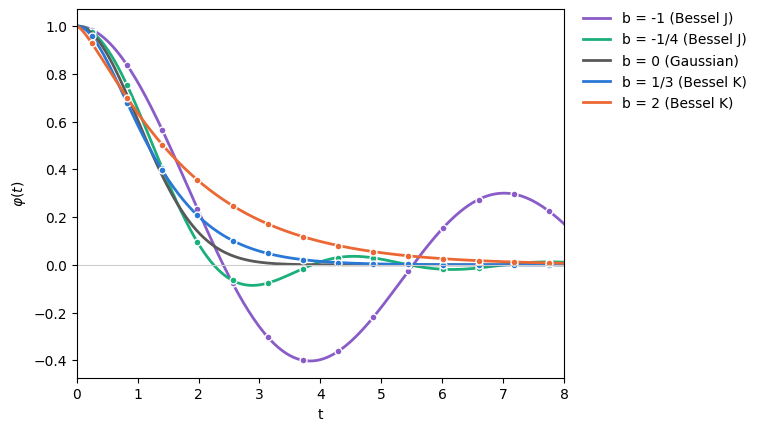

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
tt = np.linspace(0.01, 8, 300); tp_ = np.linspace(0.25, 7.75, 14)
for (b, col) in [(R(-1), colP), (R(-1, 4), colA), (0, "0.35"), (R(1, 3), colB), (R(2), colO)]:
    if b == 0:
        ax.plot(tt, np.exp(-tt**2/2), color=col, lw=2, label="b = 0 (Gaussian)")
        continue
    f = phiK(P(b), 1) if b > 0 else phiJ(P(b), 1)
    ax.plot(tt, [float(f(x)) for x in tt], color=col, lw=2, label=f"b = {b} ({'Bessel K' if b > 0 else 'Bessel J'})")
    ax.plot(tp_, [cfNum(P(b), 1, x) for x in tp_], "o", ms=5, color=col, mec="white", mew=1)
ax.axhline(0, color="0.8", lw=0.8)
ax.set_xlabel("t"); ax.set_ylabel(r"$\varphi(t)$"); ax.set_xlim(0, 8)
fig.legend(loc="outside right upper", frameon=False)
plt.show()

**Claim (Table II and the paragraph before it).** For $b=0$ the one-step form is equivalent to the product (II.8): the step is $\varphi_{n+1}(t)=\varphi_n(\rho_nt)\,\varphi_\xi(\sqrt c\,\varepsilon_nt)$, and since $\rho_n/\sqrt n=1/\sqrt{n+1}$, iterating it from $\varphi_1(t)=\varphi_\xi(\sqrt c\,t)$ gives $\varphi_\xi(\sqrt c\,t/\sqrt N)^N$. For $b=0$ the bracket of (II.10) vanishes exactly for $e^{-ct^2/2}$, and the second-order factor of (II.8) is $1-ct^2/(2n)$. For a polynomial variance function $D$ the first-order step closes into an equation whose order is the degree of $D$.

**How it is checked.** The identity $\rho_n/\sqrt n=1/\sqrt{n+1}$ and the iteration symbolically; the bracket for $e^{-ct^2/2}$; the series of $\varphi_\xi(\sqrt c\,t/\sqrt n)$; and, for $D=c+d_1y+by^2+d_3y^3+d_4y^4$, the $\varepsilon^2$-coefficient of the step contains derivatives of $\varphi$ up to order 4 and no higher.

In [21]:
nS = sp.symbols('n', positive=True, integer=True)
check("Table II: for b = 0, rho_n/Sqrt[n] = 1/Sqrt[n+1], so phi_xi(Sqrt[c] rho_n t/Sqrt[n])^n phi_xi(Sqrt[c] t/Sqrt[n+1]) = phi_xi(Sqrt[c] t/Sqrt[n+1])^(n+1)",
      sp.simplify(sp.sqrt(nS/(nS + 1))/sp.sqrt(nS) - 1/sp.sqrt(nS + 1)) == 0
      and all(abs(phiXi("two", math.sqrt(math.e)*math.sqrt(n/(n + 1))*1.7/math.sqrt(n))**n*phiXi("two", math.sqrt(math.e)*1.7/math.sqrt(n + 1))
                  - phiXi("two", math.sqrt(math.e)*1.7/math.sqrt(n + 1))**(n + 1)) < 1e-13 for n in (1, 5, 40)))
gaussPhi = sp.exp(-cs*ts**2/2)
check("Table II: for b = 0 the bracket t phi' + c t^2 phi of (II.10) vanishes for phi = exp(-c t^2/2), and phi_xi(Sqrt[c] t/Sqrt[n]) = 1 - c t^2/(2n) + O(n^(-3/2)) (skewed two-point law)",
      sp.simplify(ts*sp.diff(gaussPhi, ts) + cs*ts**2*gaussPhi) == 0
      and sp.simplify(sp.series(phiTwo.subs(uS, sp.sqrt(cp)*tp*eS), eS, 0, 3).removeO() - (1 - cp*tp**2*eS**2/2)) == 0)
d1, d3, d4 = sp.symbols('d1 d3 d4', real=True)
Dpoly = cs + d1*ys + bs*ys**2 + d3*ys**3 + d4*ys**4
c2poly = sp.expand(sp.series(sp.exp(sp.I*ts*sp.sqrt(1 - eS**2)*ys)*(1 - ts**2*eS**2*Dpoly/2), eS, 0, 3).removeO().coeff(eS, 2)*sp.exp(-sp.I*ts*ys))
check("Sec. II D: for a polynomial D of degree 4 the first-order step involves y^k exp(i t y), i.e. derivatives of phi, up to order 4 = deg D",
      sp.Poly(c2poly, ys).degree() == 4)

PASS   Table II: for b = 0, rho_n/Sqrt[n] = 1/Sqrt[n+1], so phi_xi(Sqrt[c] rho_n t/Sqrt[n])^n phi_xi(Sqrt[c] t/Sqrt[n+1]) = phi_xi(Sqrt[c] t/Sqrt[n+1])^(n+1)
PASS   Table II: for b = 0 the bracket t phi' + c t^2 phi of (II.10) vanishes for phi = exp(-c t^2/2), and phi_xi(Sqrt[c] t/Sqrt[n]) = 1 - c t^2/(2n) + O(n^(-3/2)) (skewed two-point law)
PASS   Sec. II D: for a polynomial D of degree 4 the first-order step involves y^k exp(i t y), i.e. derivatives of phi, up to order 4 = deg D


True

**Claim (Sec. II D, why the derivation is formal).** The third-order remainder needs $\sup_nE|Y_n|^3<\infty$, which fails for $b\ge\tfrac12$ because $g_b$ has an infinite third moment; the bound $|\varphi_\xi(u)-1+\tfrac12u^2|\le E\big[\min(u^2\xi^2,\tfrac16|u\xi|^3)\big]$ needs only second moments; for $b\ge1$ the limit has infinite variance and $\varphi''(0)$ does not exist.

**How it is checked.** The tail exponent $2+1/b$ of $g_b$ (Section 7): the third moment is finite iff $2+1/b>4$, i.e. $b<\tfrac12$, and the variance iff $b<1$. The pointwise inequality $|e^{ix}-1-ix+\tfrac12x^2|\le\min(x^2,\tfrac16|x|^3)$, which gives the bound after taking expectations (the term $ix$ has mean 0), on a fine grid of $x$. That $\varphi''(0)$ does not exist for $b\ge1$ is seen in the closed form: $(\varphi(t)-1)/t^2$ grows without bound as $t\to0$ for $b=1$ (like $\ln(1/t)$) and $b=2$ (like $t^{-1/2}$), and tends to $-c/(2(1-b))$ for $b<1$.

In [22]:
check("Sec. II D: the third moment of g_b is finite iff 2 + 1/b > 4 (b < 1/2) and the variance iff 2 + 1/b > 3 (b < 1)",
      all(((2 + 1/b > 4) == (b < R(1, 2))) and ((2 + 1/b > 3) == (b < 1)) for b in (R(1, 5), R(1, 3), R(1, 2), R(2, 3), 1, 2, 5)))
xg_ = np.concatenate([-np.logspace(-4, 3, 4000), np.logspace(-4, 3, 4000)])
check("Sec. II D: |exp(i x) - 1 - i x + x^2/2| <= min(x^2, |x|^3/6) (8000 points, 1e-4 <= |x| <= 1e3)",
      np.all(np.abs(np.exp(1j*xg_) - 1 - 1j*xg_ + xg_**2/2) <= np.minimum(xg_**2, np.abs(xg_)**3/6)*(1 + 1e-9) + 1e-15))
with mp.workdps(60):
  check("Sec. II D: (phi(t) - 1)/t^2 -> -c/(2(1-b)) for b = 1/3 (finite variance) and grows as t -> 0 for b = 1 (like ln(1/t)) and b = 2 (like t^(-1/2)) (c = 1)",
      close((phiK(mpf(1)/3, 1)(mpf(10)**-8) - 1)/mpf(10)**-16, -mpf(1)/(2*(1 - mpf(1)/3)), 1e-5)
      and all(abs((phiK(P(b), 1)(mpf(10)**-12) - 1)/mpf(10)**-24) > 2*abs((phiK(P(b), 1)(mpf(10)**-4) - 1)/mpf(10)**-8) for b in (1, 2)))

PASS   Sec. II D: the third moment of g_b is finite iff 2 + 1/b > 4 (b < 1/2) and the variance iff 2 + 1/b > 3 (b < 1)
PASS   Sec. II D: |exp(i x) - 1 - i x + x^2/2| <= min(x^2, |x|^3/6) (8000 points, 1e-4 <= |x| <= 1e3)
PASS   Sec. II D: (phi(t) - 1)/t^2 -> -c/(2(1-b)) for b = 1/3 (finite variance) and grows as t -> 0 for b = 1 (like ln(1/t)) and b = 2 (like t^(-1/2)) (c = 1)


## 4. Sec. III: proof of Theorem A (negative feedback, $b<0$)
Theorem A is proved by moments. With $\beta=-b>0$ and $L=\sqrt{c/\beta}$: the normalized sum is bounded by $L$ (III.1); the moments of $S_n$ obey the recursion (III.2); the moments of $Y_n$ obey a recursion of the form (III.3) with summable errors (III.4); Lemma 2 shows that such recursions converge; the limits (III.5) are the moments of $g_b$; and moment convergence on a bounded interval gives convergence in distribution. Finally, the summands (II.1) satisfy (A1)–(A3).

**Claim (III.1).** Since the left side of (A2) is nonnegative, $S_n^2\le cn/\beta$, i.e. $|Y_n|\le L$ almost surely.

**How it is checked.** On the exact laws of $Y_n$ (enumeration, $n\le14$) for the noise laws allowed by Theorem A at the boundary $\beta K^2=1$: noise $\pm1$ with $b=-1$, three-point noise with $b=-\tfrac12$, skewed two-point noise with $b=-\tfrac14$. The largest $|Y_n|$ must not exceed $L$ (it reaches $L$ for $b=-1$, where $Y_n=\pm1$ on every path).

In [23]:
check("(III.1): |Y_n| <= L on every path (exact laws, n = 2..14; pm1 with b = -1, three-point with b = -1/2, skewed two-point with b = -1/4; c = 1)",
      all(np.max(np.abs(lawY(b, 1.0, k, n)[0])) <= math.sqrt(-1/b)*(1 + 1e-12)
          for b, k in ((-1.0, "pm1"), (-0.5, "three"), (-0.25, "two")) for n in range(2, 15 if k != "three" else 10)))

PASS   (III.1): |Y_n| <= L on every path (exact laws, n = 2..14; pm1 with b = -1, three-point with b = -1/2, skewed two-point with b = -1/4; c = 1)


True

**Claim (III.2).** In the binomial expansion of $E[S_{n+1}^r\mid\mathcal F_n]$ the terms $j=0$ and $j=2$ give $\big(1-\binom r2\tfrac\beta n\big)S_n^r+\binom r2cS_n^{r-2}$, the term $j=1$ vanishes by (A1), and the terms $j\ge3$ are at most $\bar C_rn^{(r-3)/2}$, using $|S_n|\le L\sqrt n$ and $n^{(r-j)/2}\le n^{(r-3)/2}$.

**How it is checked.** The $j=0,2$ terms symbolically for $r=2,\dots,8$; the bound on the $j\ge3$ terms numerically (with $C_j=1$, $L=\tfrac32$) for $r\le8$, $n\le50$.

In [24]:
sS_, be_, cc_ = sp.symbols('S beta c', real=True); nn_ = sp.symbols('n', positive=True)
check("(III.2): the terms j = 0 and j = 2 of the binomial expansion, with E[X^2 | F] = c - beta S^2/n, give (1 - C(r,2) beta/n) S^r + C(r,2) c S^(r-2) (r = 2..8)",
      all(sp.expand(sS_**r + sp.binomial(r, 2)*sS_**(r - 2)*(cc_ - be_*sS_**2/nn_) - ((1 - sp.binomial(r, 2)*be_/nn_)*sS_**r + sp.binomial(r, 2)*cc_*sS_**(r - 2))) == 0
          for r in range(2, 9)))
check("(III.2): sum_(j=3..r) C(r,j) (L Sqrt[n])^(r-j) C_j <= Cbar_r n^((r-3)/2) (C_j = 1, L = 3/2; r = 3..8, n = 1..50)",
      all(sum(math.comb(r, j)*(1.5*math.sqrt(n))**(r - j) for j in range(3, r + 1))
          <= sum(math.comb(r, j)*1.5**(r - j) for j in range(3, r + 1))*n**((r - 3)/2)*(1 + 1e-12) for r in range(3, 9) for n in range(1, 51)))

PASS   (III.2): the terms j = 0 and j = 2 of the binomial expansion, with E[X^2 | F] = c - beta S^2/n, give (1 - C(r,2) beta/n) S^r + C(r,2) c S^(r-2) (r = 2..8)
PASS   (III.2): sum_(j=3..r) C(r,j) (L Sqrt[n])^(r-j) C_j <= Cbar_r n^((r-3)/2) (C_j = 1, L = 3/2; r = 3..8, n = 1..50)


True

**Claim (Sec. III, the rescaled recursion III.3–III.4).** Taylor's formula gives $|(1+x)^{-r/2}-1+\tfrac r2x|\le\tfrac{r(r+2)}{8}x^2$ for $0<x\le1$, hence $u_n=(n/(n+1))^{r/2}=1-\tfrac{r}{2n}+\omega_n$ with $|\omega_n|\le r(r+2)/(8n^2)$; then $u_n(1-\beta_r/n)=1-\lambda_r/n+[\dots]$ with $\lambda_r=\tfrac r2+\binom r2\beta=\tfrac r2(1+(r-1)\beta)$ and $\binom r2c/\lambda_r=(r-1)c/(1+(r-1)\beta)$; $|u_n-1|\le r/(2n)$; and each part of the error $e_r(n)$ is $O(n^{-3/2})$.

**How it is checked.** The Taylor bound and $|u_n-1|\le r/(2n)$ on grids; the algebraic identities symbolically; the power count $n^{(r-3)/2}/(n+1)^{r/2}\le n^{-3/2}$ of the third part on a grid (the first two parts carry $n^{-2}$ explicitly).

In [25]:
rr_, aa_, th_ = sp.symbols('r a omega', real=True)
check("Sec. III: |(1+x)^(-r/2) - 1 + r x/2| <= r(r+2)/8 x^2 for 0 < x <= 1 (r = 1..12, x = 1/50..1)",
      all(abs((1 + x)**(-r/2) - 1 + r*x/2) <= r*(r + 2)/8*x*x + 1e-15 for r in range(1, 13) for x in np.arange(1, 51)/50))
check("Sec. III: u_n (1 - a/n) = 1 - lambda_r/n + [r a/(2n^2) + omega_n (1 - a/n)] with u_n = 1 - r/(2n) + omega_n and lambda_r = r/2 + a",
      sp.expand((1 - rr_/(2*nn_) + th_)*(1 - aa_/nn_) - (1 - (rr_/2 + aa_)/nn_ + (rr_*aa_/(2*nn_**2) + th_*(1 - aa_/nn_)))) == 0)
check("Sec. III: lambda_r = r/2 + C(r,2) beta = (r/2)(1 + (r-1) beta), and C(r,2) c/lambda_r = (r-1) c/(1 + (r-1) beta)",
      sp.simplify(rr_/2 + rr_*(rr_ - 1)/2*be_ - rr_/2*(1 + (rr_ - 1)*be_)) == 0
      and sp.simplify(rr_*(rr_ - 1)/2*cc_/(rr_/2*(1 + (rr_ - 1)*be_)) - (rr_ - 1)*cc_/(1 + (rr_ - 1)*be_)) == 0)
check("Sec. III: |u_n - 1| <= r/(2n) (r = 1..12, n = 1..200)",
      all(abs((n/(n + 1))**(r/2) - 1) <= r/(2*n) + 1e-15 for r in range(1, 13) for n in range(1, 201)))
check("(III.4): the third part of e_r(n) is O(n^(-3/2)): n^((r-3)/2)/(n+1)^(r/2) <= n^(-3/2) (r = 2..10, n = 1..200)",
      all(n**((r - 3)/2)/(n + 1)**(r/2) <= n**-1.5*(1 + 1e-15) for r in range(2, 11) for n in range(1, 201)))

PASS   Sec. III: |(1+x)^(-r/2) - 1 + r x/2| <= r(r+2)/8 x^2 for 0 < x <= 1 (r = 1..12, x = 1/50..1)
PASS   Sec. III: u_n (1 - a/n) = 1 - lambda_r/n + [r a/(2n^2) + omega_n (1 - a/n)] with u_n = 1 - r/(2n) + omega_n and lambda_r = r/2 + a
PASS   Sec. III: lambda_r = r/2 + C(r,2) beta = (r/2)(1 + (r-1) beta), and C(r,2) c/lambda_r = (r-1) c/(1 + (r-1) beta)
PASS   Sec. III: |u_n - 1| <= r/(2n) (r = 1..12, n = 1..200)
PASS   (III.4): the third part of e_r(n) is O(n^(-3/2)): n^((r-3)/2)/(n+1)^(r/2) <= n^(-3/2) (r = 2..10, n = 1..200)


True

**Claim (Lemma 2).** If $x_{n+1}=(1-\tfrac\lambda n)x_n+\tfrac\lambda nz_n+e_n$ with $z_n\to z$ and $\sum|e_n|<\infty$, then $x_n\to z$. The proof uses the telescoping sum $\sum_{n=n_1}^{N-1}\tfrac\lambda n\Pi_{n+1,N}=1-\Pi_{n_1,N}$ and $\Pi_{n_1,N}\le\exp(-\lambda\sum_{k=n_1}^{N-1}1/k)\to0$.

**How it is checked.** The telescoping identity in exact rational arithmetic ($\lambda=\tfrac74$, $n_1=3$, $N\le60$); the exponential bound on a grid; and an illustration: a recursion with $z_n=2+1/n$ and summable errors $(-1)^n n^{-3/2}$ reaches $2$.

In [26]:
def pProd(lam, n, N):
    out = R(1)
    for k in range(n, N): out *= (1 - lam/k)
    return out
lam_ = R(7, 4)
check("Lemma 2: the sum of (lambda/n) P_(n+1,N) for n = n1..N-1 telescopes to 1 - P_(n1,N) (exact; lambda = 7/4, n1 = 3, N = 5..60)",
      all(sum(lam_/n*pProd(lam_, n + 1, N) for n in range(3, N)) == 1 - pProd(lam_, 3, N) for N in range(5, 61)))
check("Lemma 2: P_(n1,N) <= exp(-lambda (1/n1 + ... + 1/(N-1))) (lambda = 7/4, n1 = 3, N = 5..400)",
      all(float(pProd(lam_, 3, N)) <= math.exp(-1.75*sum(1/k for k in range(3, N))) + 1e-15 for N in range(5, 401, 5)))
xL = 5.0
for n in range(1, 200001): xL = (1 - 1.7/n)*xL + 1.7/n*(2 + 1/n) + (-1)**n/n**1.5
check("Lemma 2 (illustration): x_(n+1) = (1 - lambda/n) x_n + (lambda/n) z_n + e_n with z_n -> 2 and summable e_n gives x_N -> 2 (N = 2 10^5)", abs(xL - 2) < 1e-3)

PASS   Lemma 2: the sum of (lambda/n) P_(n+1,N) for n = n1..N-1 telescopes to 1 - P_(n1,N) (exact; lambda = 7/4, n1 = 3, N = 5..60)
PASS   Lemma 2: P_(n1,N) <= exp(-lambda (1/n1 + ... + 1/(N-1))) (lambda = 7/4, n1 = 3, N = 5..400)
PASS   Lemma 2 (illustration): x_(n+1) = (1 - lambda/n) x_n + (lambda/n) z_n + e_n with z_n -> 2 and summable e_n gives x_N -> 2 (N = 2 10^5)


True

**Claim (III.5 and the moments of $g_b$).** The limits are $m_0=1$, $m_1=0$, $m_r=\frac{(r-1)c}{1+(r-1)\beta}m_{r-2}$, and these are the moments of $g_b$: integrating by parts with (II.7) gives $m^g_r(1+(r-1)\beta)=(r-1)c\,m^g_{r-2}$.

**How it is checked.** (a) Exactly: the moments of $g_b=\mathrm{Law}(L(2V-1))$, computed from the Beta moments $E[V^k]=(\alpha)_k/(2\alpha)_k$ with $\alpha=1/(2\beta)$, equal the recursion (III.5) (sympy, rational $\beta$ and $c$). (b) The integration-by-parts relation by numerical integration.

In [27]:
def mLim(r, be, c):
    return R(1) if r == 0 else (R(0) if r == 1 else (r - 1)*c/(1 + (r - 1)*be)*mLim(r - 2, be, c))
def mBeta(r, be, c):
    al = 1/(2*be)
    return sp.simplify((c/be)**R(r, 2)*sum(sp.binomial(r, k)*2**k*(-1)**(r - k)*sp.rf(al, k)/sp.rf(2*al, k) for k in range(r + 1)))
check("(III.5): the recursion gives the moments of g_b, computed exactly from the Beta form (beta = 1/4, 1/2, 1, 5/2; c = 13/10; r = 1..10)",
      all(sp.simplify(mBeta(r, be, R(13, 10)) - mLim(r, be, R(13, 10))) == 0 for be in (R(1, 4), R(1, 2), R(1), R(5, 2)) for r in range(1, 11)))
def mInt(r, be, c):
    be, c = P(be), P(c); L = mp.sqrt(c/be)
    return mp.quad(lambda y: y**r*(c - be*y**2)**(-kap(-be))/zz(-be, c), [-L, 0, L])
check("Sec. III: integration by parts, m_r (1 + (r-1) beta) = (r-1) c m_(r-2), by numerical integration (beta = 1/4, 1/2; r = 2, 4, 6; c = 13/10)",
      all(close(mInt(r, be, R(13, 10))*(1 + (r - 1)*P(be)), (r - 1)*P(R(13, 10))*mInt(r - 2, be, R(13, 10)), 1e-10) for be in (R(1, 4), R(1, 2)) for r in (2, 4, 6)))

PASS   (III.5): the recursion gives the moments of g_b, computed exactly from the Beta form (beta = 1/4, 1/2, 1, 5/2; c = 13/10; r = 1..10)
PASS   Sec. III: integration by parts, m_r (1 + (r-1) beta) = (r-1) c m_(r-2), by numerical integration (beta = 1/4, 1/2; r = 2, 4, 6; c = 13/10)


True

**Convergence of the moments without sampling (additional check).** For the noise $\pm1$, $E[(S+\sigma\xi)^r\mid S]$ is a polynomial in $S$, so the even moments of $S_n$ obey an exact *closed* linear recursion (the odd moments vanish). Iterating it to $N=2000$ shows the convergence of $E[Y_N^r]$, $r=2,\dots,8$, to the limits (III.5), with no sampling error.

In [28]:
def momStep(mu, n, be, c):
    """even moments mu[k] = E S_n^(2k), k = 0..K, one step of (II.1) with noise +1/-1"""
    K = len(mu) - 1; out = []
    for k in range(K + 1):
        r = 2*k; tot = 0.0
        for j in range(0, r + 1, 2):        # E xi^j = 1 for even j
            # E[S^(r-j) (c - be S^2/n)^(j/2)] expanded
            tot += math.comb(r, j)*sum(math.comb(j//2, i)*c**(j//2 - i)*(-be/n)**i*mu[(r - j)//2 + i] for i in range(j//2 + 1) if (r - j)//2 + i <= K)
        out.append(tot)
    return out
def momRad(be, c, nmax, rmax):
    mu = [c**k for k in range(rmax//2 + 1)]           # S_1 = Sqrt[c] xi
    for n in range(1, nmax): mu = momStep(mu, n, be, c)
    return [mu[k]/nmax**k for k in range(rmax//2 + 1)]
momTable = [(be, N, max(abs(m/float(mLim(2*k, be, 1)) - 1) for k, m in enumerate(momRad(float(be), 1.0, N, 8)) if k >= 1))
            for be in (R(1, 4), R(1, 2), R(1)) for N in (200, 2000)]
print("beta    N     largest relative error of E[Y_N^r], r = 2, 4, 6, 8")
for be, N, e in momTable: print(f"{str(be):5s} {N:5d}   {e:.2e}")
check("Sec. III (exact, no sampling): for the noise +1/-1 the moments E Y_N^r, r = 2..8, approach (III.5): relative error below 5e-4 at N = 2000 and not larger than at N = 200",
      all(momTable[2*i + 1][2] < 5e-4 and momTable[2*i + 1][2] <= momTable[2*i][2] + 1e-12 for i in range(3)))

beta    N     largest relative error of E[Y_N^r], r = 2, 4, 6, 8
1/4     200   3.64e-03
1/4    2000   3.90e-04
1/2     200   1.45e-03
1/2    2000   1.58e-04
1       200   2.22e-16
1      2000   0.00e+00
PASS   Sec. III (exact, no sampling): for the noise +1/-1 the moments E Y_N^r, r = 2..8, approach (III.5): relative error below 5e-4 at N = 2000 and not larger than at N = 200


True

**Claim (the summands II.1 satisfy (A1)–(A3)).** If $|\xi_1|\le K$ with $\beta K^2\le1$, then by induction $S_n^2\le cn/\beta$: the base case is $S_1^2=c\xi_1^2\le cK^2\le c/\beta$, and the Cauchy–Schwarz step gives $|S_{n+1}|\le\sqrt{c(n/\beta+K^2)}\le\sqrt{c(n+1)/\beta}$. Then (A1), (A2) hold, and (A3) with $C_j=(\sqrt cK)^j$, since $D(Y_n)\le c$.

**How it is checked.** The two algebraic steps symbolically; the inequality $|S+\sqrt{c-\beta S^2/n}\,x|\le\sqrt{c(n+1)/\beta}$ on a grid of $|S|\le\sqrt{cn/\beta}$, $|x|\le K$, $\beta K^2=1$; the values $\beta K^2$ for the five simulated cases with $b<0$ (Table III).

In [29]:
kk_ = sp.symbols('K', positive=True)
check("Sec. III, (A1)-(A3): (beta S^2/n + c - beta S^2/n)(n/beta + K^2) = c (n/beta + K^2), and c (n+1)/beta - c (n/beta + K^2) = c (1 - beta K^2)/beta >= 0",
      sp.simplify((be_*sS_**2/nn_ + cc_ - be_*sS_**2/nn_)*(nn_/be_ + kk_**2) - cc_*(nn_/be_ + kk_**2)) == 0
      and sp.simplify(cc_*(nn_ + 1)/be_ - cc_*(nn_/be_ + kk_**2) - cc_*(1 - be_*kk_**2)/be_) == 0)
def caseOK(be, c, n, u, v):
    smax = math.sqrt(c*n/be); K = 1/math.sqrt(be); s = u*smax
    return abs(s + math.sqrt(max(c - be*s*s/n, 0))*v*K) <= math.sqrt(c*(n + 1)/be) + 1e-12
check("Sec. III, (A1)-(A3) (numerical): |S + Sqrt[c - beta S^2/n] x| <= Sqrt[c (n+1)/beta] whenever |S| <= Sqrt[c n/beta], |x| <= K, beta K^2 = 1",
      all(caseOK(be, c, n, u, v) for be in (0.25, 0.5, 1) for c in (1, 2.3) for n in (1, 2, 5, 40) for u in np.linspace(-1, 1, 21) for v in np.linspace(-1, 1, 11)))
check("Sec. III, (A1)-(A3): beta K^2 = 1, 1, 1/2, 3/4, 1 for the five simulated cases with b < 0 (pm1 with b = -1; three-point and pm1 with b = -1/2; uniform and skewed two-point with b = -1/4)",
      [1*1, R(1, 2)*2, R(1, 2)*1, R(1, 4)*3, R(1, 4)*4] == [1, 1, R(1, 2), R(3, 4), 1])

PASS   Sec. III, (A1)-(A3): (beta S^2/n + c - beta S^2/n)(n/beta + K^2) = c (n/beta + K^2), and c (n+1)/beta - c (n/beta + K^2) = c (1 - beta K^2)/beta >= 0
PASS   Sec. III, (A1)-(A3) (numerical): |S + Sqrt[c - beta S^2/n] x| <= Sqrt[c (n+1)/beta] whenever |S| <= Sqrt[c n/beta], |x| <= K, beta K^2 = 1
PASS   Sec. III, (A1)-(A3): beta K^2 = 1, 1, 1/2, 3/4, 1 for the five simulated cases with b < 0 (pm1 with b = -1; three-point and pm1 with b = -1/2; uniform and skewed two-point with b = -1/4)


True

**Claim (Remark after Theorem A).** $E\xi_1^2=1$ forces $K\ge1$, so $\beta K^2\le1$ can hold only for $-1\le b<0$; for $b<-1$ the summands (II.1) are not defined, since (III.1) at $n=1$ would require $\xi_1^2\le1/\beta<1$ almost surely, contradicting $E\xi_1^2=1$.

**How it is checked.** $1=E\xi_1^2\le K^2$; then $\beta\le1/K^2\le1$. For $\beta>1$, $E\xi_1^2\le1/\beta<1$ — checked on the bound, which is all the argument needs.

In [30]:
check("Remark after Theorem A: E xi^2 = 1 <= K^2 and beta K^2 <= 1 give beta <= 1 (b >= -1); for beta > 1, xi^2 <= 1/beta forces E xi^2 <= 1/beta < 1",
      all((not (1 <= K2 and be*K2 <= 1)) or bool(be <= 1) for be in (R(1, 2), 1, R(5, 4), 2) for K2 in (1, R(3, 2), 2, 4))
      and all(1/be < 1 for be in (R(5, 4), 2, 10)))

PASS   Remark after Theorem A: E xi^2 = 1 <= K^2 and beta K^2 <= 1 give beta <= 1 (b >= -1); for beta > 1, xi^2 <= 1/beta forces E xi^2 <= 1/beta < 1


True

## 5. Sec. IV: proof of Theorem B (positive feedback, $b>0$)
Theorem B is proved by a coupling in the Wasserstein distance $W_1$. Lemma 3 reduces $W_1$ to smooth test functions; the step of the recursion is a map $\mathcal K^\varepsilon$ on laws (IV.2–IV.3); Lemma 4 collects elementary bounds; Lemma 5 shows that two normalized sums driven by the same noise come together at the rate $\sqrt{m/N}$, up to the factor $\Lambda$ (IV.4–IV.5); Lemma 6 (Section 6 below) bounds the one-step defect $W_1(g\mathcal K^\varepsilon,g)\le C_L\varepsilon^3$; and Sec. IV F assembles the bound (II.5).

**Claim (Lemma 3, two steps of the proof).** For a 1-Lipschitz $h$, the clipped function $h_R(y)=h(\max(-R,\min(R,y)))$ satisfies $|h-h_R|(y)\le(|y|-R)_+$, and its mollification $h_R*\varphi_\delta$ is within $\delta$ of $h_R$.

**How it is checked.** For the 1-Lipschitz function $h(y)=\tfrac12(|\sin y|+|y-0.3|)$, $R=2$, on a grid; the mollification with the standard bump $\varphi_\delta$, $\delta=0.1$, by numerical convolution. (The rest of Lemma 3 is the standard duality (IV.1) and is not reproved.)

In [31]:
hTest = lambda y: 0.5*(np.abs(np.sin(y)) + np.abs(y - 0.3))
yy_ = np.linspace(-8, 8, 4001); hR = hTest(np.clip(yy_, -2, 2))
dl = 0.1; zg = np.linspace(-dl, dl, 801)[1:-1]
bump = np.exp(-1/(1 - (zg/dl)**2)); bump /= np.trapezoid(bump, zg)
hRd = np.array([np.trapezoid(hTest(np.clip(y - zg, -2, 2))*bump, zg) for y in yy_[::10]])
check("Lemma 3: |h - h_R| <= (|y| - R)_+ and |h_R * phi_delta - h_R| <= delta (h = (|sin y| + |y - 0.3|)/2, R = 2, delta = 0.1)",
      np.all(np.abs(hTest(yy_) - hR) <= np.maximum(np.abs(yy_) - 2, 0) + 1e-12) and np.all(np.abs(hRd - hR[::10]) <= dl))

PASS   Lemma 3: |h - h_R| <= (|y| - R)_+ and |h_R * phi_delta - h_R| <= delta (h = (|sin y| + |y - 0.3|)/2, R = 2, delta = 0.1)


True

**Claim (Sec. IV B).** $\sigma(u)\le\sqrt c+\sqrt b\,|u|$, so $\mu\mathcal K^\varepsilon$ has a finite first moment whenever $\mu$ does.

**How it is checked.** On a grid; equivalently $(\sqrt c+\sqrt b|u|)^2-\sigma^2=2\sqrt{bc}|u|\ge0$, checked symbolically.

In [32]:
check("Sec. IV B: sigma(u) <= Sqrt[c] + Sqrt[b] |u|, since (Sqrt[c] + Sqrt[b] |u|)^2 - (c + b u^2) = 2 Sqrt[b c] |u|",
      sp.simplify((sp.sqrt(cp) + sp.sqrt(bp)*yp)**2 - (cp + bp*yp**2) - 2*sp.sqrt(bp*cp)*yp) == 0)

PASS   Sec. IV B: sigma(u) <= Sqrt[c] + Sqrt[b] |u|, since (Sqrt[c] + Sqrt[b] |u|)^2 - (c + b u^2) = 2 Sqrt[b c] |u|


True

**Claim (Lemma 4).** For $b>0$: (a) $\sigma\ge\sqrt c$ and $|y|\le\sigma/\sqrt b$; (b) $\sigma'=by/\sigma$, $|\sigma'|\le\sqrt b$; (c) $\sigma''=bc/\sigma^3$, $\sigma'''=-3bc\sigma'/\sigma^4$, $|\sigma'''|\le3b^{3/2}c/\sigma^4$; (d) $(yg)'=g(1-2\kappa by^2/D)$ and $|(yg)'|\le2\kappa g$; (e) $a_1=\int\sigma g<\infty$ and $\int|y|g\le a_1/\sqrt b$.

**How it is checked.** The derivative formulas symbolically. The constant $a_1$: the closed form $\sqrt c\,\Gamma(\kappa-1)\Gamma(\kappa)/\Gamma(\kappa-\tfrac12)^2$ (derived in the proof of Corollary D (a)) against numerical integration, and the two values $a_1=3\pi/8$ ($b=\tfrac13$) and $\pi/2$ ($b=1$) for $c=1$; $\int|y|g\le a_1/\sqrt b$ numerically. The pointwise bounds (a)–(d) are part of the grid test below.

In [33]:
sgS = sp.sqrt(cp + bp*yp**2)
check("Lemma 4(b),(c): sigma' = b y/sigma, sigma'' = b c/sigma^3, sigma''' = -3 b c sigma'/sigma^4",
      sp.simplify(sp.diff(sgS, yp) - bp*yp/sgS) == 0 and sp.simplify(sp.diff(sgS, yp, 2) - bp*cp/sgS**3) == 0
      and sp.simplify(sp.diff(sgS, yp, 3) + 3*bp*cp*sp.diff(sgS, yp)/sgS**4) == 0)
kP = 1 + 1/(2*bp)
check("Lemma 4(d): (y g)' = g (1 - 2 kappa b y^2/D)",
      sp.simplify(sp.diff(yp*(cp + bp*yp**2)**(-kP), yp)*(cp + bp*yp**2)**kP - (1 - 2*kP*bp*yp**2/(cp + bp*yp**2))) == 0)
def a1Num(b, c):
    b, c = P(b), P(c); return 2*mp.quad(lambda y: sig(y, b, c)*gb(y, b, c), [0, 1, 10, mp.inf])
check("Lemma 4(e): a_1 = Sqrt[c] Gamma(kappa-1) Gamma(kappa)/Gamma(kappa-1/2)^2 equals the integral of sigma g (b = 1/3, 1, 2; c = 1, 23/10); a_1 = 3 Pi/8 for b = 1/3 and Pi/2 for b = 1 (c = 1)",
      all(close(a1Of(P(b), P(c)), a1Num(b, c), 1e-10) for b in (R(1, 3), 1, 2) for c in (1, R(23, 10)))
      and close(a1Of(mpf(1)/3, 1), 3*mp.pi/8, 1e-25) and close(a1Of(1, 1), mp.pi/2, 1e-25))
check("Lemma 4(e): Int |y| g <= a_1/Sqrt[b] (b = 1/3, 1, 2, 10; c = 1, 23/10)",
      all(2*mp.quad(lambda y: y*gb(y, P(b), P(c)), [0, 1, 10, mp.inf]) <= a1Of(P(b), P(c))/mp.sqrt(P(b)) for b in (R(1, 3), 1, 2, 10) for c in (1, R(23, 10))))

PASS   Lemma 4(b),(c): sigma' = b y/sigma, sigma'' = b c/sigma^3, sigma''' = -3 b c sigma'/sigma^4
PASS   Lemma 4(d): (y g)' = g (1 - 2 kappa b y^2/D)
PASS   Lemma 4(e): a_1 = Sqrt[c] Gamma(kappa-1) Gamma(kappa)/Gamma(kappa-1/2)^2 equals the integral of sigma g (b = 1/3, 1, 2; c = 1, 23/10); a_1 = 3 Pi/8 for b = 1/3 and Pi/2 for b = 1 (c = 1)
PASS   Lemma 4(e): Int |y| g <= a_1/Sqrt[b] (b = 1/3, 1, 2, 10; c = 1, 23/10)


True

**Claim (Lemma 4, (A.3) and the five bounds of Appendix A).** Twelve pointwise inequalities are used in the proofs: $|\sigma'|\le\sqrt b$; $|\sigma'''|\le3b^{3/2}c/\sigma^4$; $|(yg)'|\le2\kappa g$; and, for the maps $\Psi(y)=\rho_ty+s\sigma(y)$ with $t\in[0,\tfrac12]$, $|s|\le s_0=1/(4\sqrt b)$ and $\tau=\Psi'$: $\tfrac12\le\tau\le\tfrac54$, $|\tau'|\le\sqrt bc/(4\sigma^3)$, $|\tau''|\le3bc/(4\sigma^4)$ (A.3); and, with $Q=Dg$ and $\Upsilon=(Q/\tau)'$: $|\Upsilon|\le(2/\sqrt b+\sqrt b)\sigma g$, $|\Upsilon'|\le(4\kappa+2+4b)g$, $|(\sigma\Upsilon/\tau)'|\le(10+11b+8\kappa)\sigma g$, $|(Q\sigma'/\tau^2)'|\le(4+8b)\sigma g$, $|(\sigma yg/\tau)'|\le(3+4\kappa)\sigma g$ (Appendix A, "It remains to bound the higher derivatives").

**How it is checked.** Each left side is differentiated symbolically and divided by its bound; the twelve ratios are evaluated on a grid: $b\in\{\tfrac1{10},\tfrac13,1,2,10\}$, $c\in\{\tfrac12,1,5\}$, $t\in\{0,\tfrac14,\tfrac12\}$, $s=u\,s_0$ with $u\in\{-1,-\tfrac12,0,\tfrac12,1\}$, and 51 values of $y$ between $-10^3$ and $10^3$ (logarithmically spaced, and $0$). Every ratio must be at most 1; several bounds are attained (ratio exactly 1, e.g. $|\tau'|$ at $|s|=s_0$), and floating-point rounding at $|y|=10^3$ is of order $10^{-9}$, so the test allows $1+10^{-6}$. (The normalizing constant of $g$ cancels in every ratio and is omitted.)

In [34]:
yv, sv, tv, bv, cv = sp.symbols('y s t b c', real=True)
kp_ = 1 + 1/(2*bv); dq = cv + bv*yv**2; sg_ = sp.sqrt(dq); g_ = dq**(-kp_); rho_ = sp.sqrt(1 - tv**2)
tau_ = rho_ + sv*sp.diff(sg_, yv); Q_ = dq*g_; U_ = sp.diff(Q_/tau_, yv)
ratioNames = ["|sigma'| <= Sqrt[b]", "|sigma'''| <= 3 b^(3/2) c/sigma^4", "|(y g)'| <= 2 kappa g", "tau >= 1/2", "tau <= 5/4",
              "|tau'| <= Sqrt[b] c/(4 sigma^3)", "|tau''| <= 3 b c/(4 sigma^4)", "|Upsilon| <= (2/Sqrt[b] + Sqrt[b]) sigma g",
              "|Upsilon'| <= (4 kappa + 2 + 4 b) g", "|(sigma Upsilon/tau)'| <= (10 + 11 b + 8 kappa) sigma g",
              "|(Q sigma'/tau^2)'| <= (4 + 8 b) sigma g", "|(sigma y g/tau)'| <= (3 + 4 kappa) sigma g"]
ratioExprs = [sp.Abs(sp.diff(sg_, yv))/sp.sqrt(bv), sp.Abs(sp.diff(sg_, yv, 3))/(3*bv**R(3, 2)*cv/sg_**4), sp.Abs(sp.diff(yv*g_, yv))/(2*kp_*g_),
              1/(2*tau_), 4*tau_/5, sp.Abs(sp.diff(tau_, yv))/(sp.sqrt(bv)*cv/(4*sg_**3)), sp.Abs(sp.diff(tau_, yv, 2))/(3*bv*cv/(4*sg_**4)),
              sp.Abs(U_)/((2/sp.sqrt(bv) + sp.sqrt(bv))*sg_*g_), sp.Abs(sp.diff(U_, yv))/((4*kp_ + 2 + 4*bv)*g_),
              sp.Abs(sp.diff(sg_*U_/tau_, yv))/((10 + 11*bv + 8*kp_)*sg_*g_), sp.Abs(sp.diff(Q_*sp.diff(sg_, yv)/tau_**2, yv))/((4 + 8*bv)*sg_*g_),
              sp.Abs(sp.diff(sg_*yv*g_/tau_, yv))/((3 + 4*kp_)*sg_*g_)]
ratioF = [sp.lambdify((yv, sv, tv, bv, cv), sp.powsimp(e, force=True), "numpy") for e in ratioExprs]
yg = np.concatenate([-10**np.arange(-3, 3.01, 0.25), [0.0], 10**np.arange(-3, 3.01, 0.25)])
G = np.array(list(itertools.product([0.1, 1/3, 1, 2, 10], [0.5, 1, 5], [0, 0.25, 0.5], [-1, -0.5, 0, 0.5, 1], yg)))
Gb, Gc, Gt, Gu, Gy = G.T; Gs = Gu/(4*np.sqrt(Gb))
ratioMax = [float(np.max(np.broadcast_to(f(Gy, Gs, Gt, Gb, Gc), Gy.shape))) for f in ratioF]
for nm, m in zip(ratioNames, ratioMax): print(f"{m:8.4f}   {nm}")
check(f"Lemma 4, (A.3) and App. A: all twelve pointwise bounds hold on the grid of {len(G)} points (largest ratio 1 + {max(ratioMax) - 1:.1e} <= 1 + 1e-6)",
      max(ratioMax) <= 1 + 1e-6)

  1.0000   |sigma'| <= Sqrt[b]
  1.0000   |sigma'''| <= 3 b^(3/2) c/sigma^4
  0.9167   |(y g)'| <= 2 kappa g
  0.8117   tau >= 1/2
  1.0000   tau <= 5/4
  1.0000   |tau'| <= Sqrt[b] c/(4 sigma^3)
  1.0000   |tau''| <= 3 b c/(4 sigma^4)
  0.7730   |Upsilon| <= (2/Sqrt[b] + Sqrt[b]) sigma g
  0.6764   |Upsilon'| <= (4 kappa + 2 + 4 b) g
  0.4459   |(sigma Upsilon/tau)'| <= (10 + 11 b + 8 kappa) sigma g
  0.5490   |(Q sigma'/tau^2)'| <= (4 + 8 b) sigma g
  0.6012   |(sigma y g/tau)'| <= (3 + 4 kappa) sigma g
PASS   Lemma 4, (A.3) and App. A: all twelve pointwise bounds hold on the grid of 11475 points (largest ratio 1 + 1.6e-09 <= 1 + 1e-6)


True

**Claim (Lemma 5, one step).** For $x=\rho_n+\varepsilon_n\vartheta\xi$ with $|\vartheta|\le\sqrt b$: $E[x]=\rho_n$ and $|x|=x+2x^-$; $x^-\le(\varepsilon_n\sqrt b|\xi|-\rho_n)_+\le\varepsilon_n\sqrt b|\xi|\,\mathbf 1\{|\xi|>\rho_n/(\varepsilon_n\sqrt b)\}\le\varepsilon_n\sqrt b|\xi|^3(\varepsilon_n\sqrt b/\rho_n)^2$; hence $E|x|\le\rho_n+2b^{3/2}M_3\varepsilon_n^3/\rho_n^2$, and with $\rho_n^{-3}\le2\sqrt2$, $E|x|\le\rho_n(1+\delta_n)$, $\delta_n=4\sqrt2\,b^{3/2}M_3(n+1)^{-3/2}$.

**How it is checked.** The chain of pointwise inequalities on a grid of $n$, $b$, $\vartheta$, $\xi$; $\rho_n^{-3}\le2\sqrt2$ for $n\le500$ (and $\rho_n^2=n/(n+1)\ge\tfrac12$); the final bound on $E|x|$ computed exactly for the noise $\pm1$ and the skewed two-point noise and in closed form for Gaussian noise.

In [35]:
def chainOK(n, b, th, xi):
    rho, e = math.sqrt(n/(n + 1)), 1/math.sqrt(n + 1); x = rho + e*th*math.sqrt(b)*xi; xm = max(-x, 0)
    a1_ = max(e*math.sqrt(b)*abs(xi) - rho, 0); a2_ = e*math.sqrt(b)*abs(xi)*(abs(xi) > rho/(e*math.sqrt(b)))
    a3_ = e*math.sqrt(b)*abs(xi)**3*(e*math.sqrt(b)/rho)**2
    return abs(abs(x) - (x + 2*xm)) < 1e-12 and xm <= a1_ + 1e-12 and a1_ <= a2_ + 1e-12 and a2_ <= a3_ + 1e-12
check("Lemma 5, proof: |x| = x + 2 x^-, and x^- <= (eps Sqrt[b] |xi| - rho)_+ <= eps Sqrt[b] |xi| 1{|xi| > rho/(eps Sqrt[b])} <= eps Sqrt[b] |xi|^3 (eps Sqrt[b]/rho)^2 (grid)",
      all(chainOK(n, b, th, xi) for n in (1, 2, 5, 30) for b in (1/3, 1, 2, 10) for th in np.linspace(-1, 1, 9) for xi in np.linspace(-6, 6, 49)))
check("Lemma 5, proof: rho_n^2 = n/(n+1) >= 1/2 and rho_n^(-3) <= 2 Sqrt[2] for n >= 1 (n = 1..500)",
      all(n/(n + 1) >= 0.5 and (n/(n + 1))**-1.5 <= 2*math.sqrt(2) + 1e-12 for n in range(1, 501)))
def absMean(k, rho, e):
    if k == "pm1": return (abs(rho + e) + abs(rho - e))/2
    if k == "two": return abs(rho + 2*e)/5 + 4*abs(rho - e/2)/5
    if e == 0 or rho > 30*abs(e): return rho
    return abs(e)*math.sqrt(2/math.pi)*math.exp(-rho**2/(2*e*e)) + rho*math.erf(rho/(abs(e)*math.sqrt(2)))
check("Lemma 5, proof: E|rho_n + eps_n theta xi| <= rho_n (1 + delta_n), delta_n = 4 Sqrt[2] b^(3/2) M3 (n+1)^(-3/2) (noise +1/-1, skewed two-point, Gaussian; b = 1/3, 1, 2, 10; n = 1..60; |theta| <= Sqrt[b])",
      all(absMean(k, math.sqrt(n/(n + 1)), th*math.sqrt(b)/math.sqrt(n + 1)) <= math.sqrt(n/(n + 1))*(1 + 4*math.sqrt(2)*b**1.5*float(m3[k])*(n + 1)**-1.5) + 1e-12
          for k in ("pm1", "two", "gauss") for b in (1/3, 1, 2, 10) for n in range(1, 61) for th in np.linspace(-1, 1, 17)))

PASS   Lemma 5, proof: |x| = x + 2 x^-, and x^- <= (eps Sqrt[b] |xi| - rho)_+ <= eps Sqrt[b] |xi| 1{|xi| > rho/(eps Sqrt[b])} <= eps Sqrt[b] |xi|^3 (eps Sqrt[b]/rho)^2 (grid)
PASS   Lemma 5, proof: rho_n^2 = n/(n+1) >= 1/2 and rho_n^(-3) <= 2 Sqrt[2] for n >= 1 (n = 1..500)
PASS   Lemma 5, proof: E|rho_n + eps_n theta xi| <= rho_n (1 + delta_n), delta_n = 4 Sqrt[2] b^(3/2) M3 (n+1)^(-3/2) (noise +1/-1, skewed two-point, Gaussian; b = 1/3, 1, 2, 10; n = 1..60; |theta| <= Sqrt[b])


True

**Claim (Lemma 5, iteration and IV.4).** $\prod_{n=m}^{N-1}\sqrt{n/(n+1)}=\sqrt{m/N}$, $\sum_{n\ge1}(n+1)^{-3/2}=\sum_{j\ge2}j^{-3/2}=\zeta(\tfrac32)-1$, and $\Lambda=\exp\big(4\sqrt2\,b^{3/2}M_3(\zeta(\tfrac32)-1)\big)$.

**How it is checked.** The product in exact arithmetic; the zeta series with sympy; and the values of $\Lambda$ in an additional table of the constants of Theorem B ($c=1$; the noise $\pm1$ with $M_3=1$ and the skewed two-point noise with $M_3=\tfrac{17}{10}$).

In [36]:
check("Lemma 5, proof: the product of rho_n^2 from n = m to N-1 equals m/N (exact, m = 1..6, N = m..40)",
      all(sp.prod([R(n, n + 1) for n in range(m, N)]) == R(m, N) for m in range(1, 7) for N in range(m, 41)))
jS = sp.symbols('j', positive=True, integer=True)
check("(IV.4): Sum over j >= 2 of j^(-3/2) = Zeta(3/2) - 1",
      sp.simplify(sp.expand_func(sp.summation(jS**R(-3, 2), (jS, 2, sp.oo))) - (sp.zeta(R(3, 2)) - 1)) == 0)
lamTab = {(b, k): lamOf(P(b), m3[k]) for b in (R(1, 3), 1, 2) for k in ("two", "pm1")}
print("Additional table (constants of Theorem B, c = 1):  b   noise   M3    Lambda    C_L")
for (b, k), lv in lamTab.items(): print(f"   {str(b):4s} {k:5s} {float(m3[k]):5.2f}  {float(lv):11.5e}  {float(clOf(P(b), 1, m3[k])):9.4f}")
check("(IV.4): Lambda = 19.768, 5.78537, 5.42025e6, 9145.09, 1.11348e19, 1.59931e11 for (b, M3) = (1/3, 17/10), (1/3, 1), (1, 17/10), (1, 1), (2, 17/10), (2, 1)",
      close(lamTab[(R(1, 3), "two")], 19.768, 1e-4) and close(lamTab[(R(1, 3), "pm1")], 5.78537, 1e-5) and close(lamTab[(1, "two")], 5.42025e6, 1e-5)
      and close(lamTab[(1, "pm1")], 9145.09, 1e-5) and close(lamTab[(2, "two")], 1.11348e19, 1e-5) and close(lamTab[(2, "pm1")], 1.59931e11, 1e-5))

PASS   Lemma 5, proof: the product of rho_n^2 from n = m to N-1 equals m/N (exact, m = 1..6, N = m..40)
PASS   (IV.4): Sum over j >= 2 of j^(-3/2) = Zeta(3/2) - 1
Additional table (constants of Theorem B, c = 1):  b   noise   M3    Lambda    C_L
   1/3  two    1.70  1.97680e+01   129.8460
   1/3  pm1    1.00  5.78537e+00    76.3800
   1    two    1.70  5.42025e+06   214.9635
   1    pm1    1.00  9.14509e+03   126.4491
   2    two    1.70  1.11348e+19   442.7213
   2    pm1    1.00  1.59931e+11   260.4243
PASS   (IV.4): Lambda = 19.768, 5.78537, 5.42025e6, 9145.09, 1.11348e19, 1.59931e11 for (b, M3) = (1/3, 17/10), (1/3, 1), (1, 17/10), (1, 1), (2, 17/10), (2, 1)


True

**Claim (Sec. IV F, assembling (II.5)).** $\varepsilon_n=(n+1)^{-1/2}\le\tfrac12$ exactly when $n\ge3$ (so Lemma 6 applies from $n=3$ on); $\sqrt{(n+1)/N}\,(n+1)^{-3/2}=1/(\sqrt N(n+1))$; and $\sum_{n=3}^{N-1}\tfrac1{n+1}\le\int_3^N\tfrac{dx}x=\ln(N/3)$.

**How it is checked.** The first two exactly or in floating point on grids; the harmonic sum for $N=3,\dots,5000$.

In [37]:
check("Sec. IV F: eps_n = (n+1)^(-1/2) <= 1/2 exactly when n >= 3 (n = 1..200)", all((1/math.sqrt(n + 1) <= 0.5) == (n >= 3) for n in range(1, 201)))
check("Sec. IV F: Sqrt[(n+1)/N] (n+1)^(-3/2) = 1/(Sqrt[N] (n+1))",
      sp.simplify(sp.sqrt((nS + 1)/np_)*(nS + 1)**R(-3, 2) - 1/(sp.sqrt(np_)*(nS + 1))) == 0)
Hs = np.cumsum(1/np.arange(1, 5002))
check("Sec. IV F: the sum of 1/(n+1) for n = 3..N-1 is at most ln(N/3) (N = 3..5000)",
      all(Hs[N - 1] - Hs[2] <= math.log(N/3) + 1e-12 for N in range(3, 5001)))

PASS   Sec. IV F: eps_n = (n+1)^(-1/2) <= 1/2 exactly when n >= 3 (n = 1..200)
PASS   Sec. IV F: Sqrt[(n+1)/N] (n+1)^(-3/2) = 1/(Sqrt[N] (n+1))
PASS   Sec. IV F: the sum of 1/(n+1) for n = 3..N-1 is at most ln(N/3) (N = 3..5000)


True

## 6. Appendix A: the one-step defect estimate (Lemma 6, Eqs. A.1–A.10 and IV.6–IV.7)
Lemma 6 states $W_1(g\mathcal K^\varepsilon,g)\le C_L\varepsilon^3$ for $\varepsilon\le\tfrac12$, with $C_L=a_1M_3(33+\tfrac{83}{2}b+\tfrac6b)$. The proof truncates the noise (A.1–A.2), interpolates between $Y$ and $Y^+$ with $\Phi(t)=E[h(Y^{(t)})]$, writes $\Phi'$ through two integrals $\mathcal A_t(s)$, $\mathcal B_t(s)$ over the maps $\Psi_{t,s}(y)=\rho_ty+s\sigma(y)$ (A.3–A.4), differentiates them (A.5–A.8), uses the identity (II.7) to cancel the leading terms (A.9), bounds the remainders (A.10), and assembles $C_L$.

**Claim (A.1).** With $s_0=1/(4\sqrt b)$ and $\tilde\xi=\xi\mathbf 1\{|\xi|\le s_0/\varepsilon\}$: $|E\tilde\xi|\le16bM_3\varepsilon^2$, $0\le1-E\tilde\xi^2\le4\sqrt bM_3\varepsilon$, $E|\xi-\tilde\xi|\le16bM_3\varepsilon^2$, $E|\tilde\xi|\le1$, $E|\tilde\xi|^3\le M_3$. They follow from $|\xi|\mathbf 1\{|\xi|>A\}\le|\xi|^3/A^2$ and $\xi^2\mathbf 1\{|\xi|>A\}\le|\xi|^3/A$, with $A=s_0/\varepsilon$. Also $M_3\ge1$ and $E|\xi|\le1$ (Lyapunov's inequality).

**How it is checked.** The two elementary inequalities on a grid; the five bounds exactly for the noise $\pm1$ and the skewed two-point noise for $b\in[\tfrac1{10},10]$ and $\varepsilon\in[\tfrac1{50},\tfrac12]$ (including cases where the truncation removes atoms); $M_3\ge1$ and $E|\xi|\le1$ for the noise laws of the paper.

In [38]:
check("(A.1): |x| 1{|x| > A} <= |x|^3/A^2 and x^2 1{|x| > A} <= |x|^3/A (grid)",
      all(abs(x)*(abs(x) > A) <= abs(x)**3/A**2 + 1e-12 and x*x*(abs(x) > A) <= abs(x)**3/A + 1e-12
          for x in np.arange(-40, 41)/8 for A in np.arange(1, 17)/4))
def truncOK(k, b, e):
    A = 1/(4*sp.sqrt(b)*e); kept = [(v, p) for v, p in atoms[k] if abs(v) <= A]; cut = [(v, p) for v, p in atoms[k] if abs(v) > A]
    M = sp.nsimplify(m3[k]) if k == "pm1" else R(17, 10)
    S = lambda lst, f: sum((p*f(v) for v, p in lst), sp.Integer(0))
    return (abs(S(kept, lambda v: v)) <= 16*b*M*e**2 and 0 <= 1 - S(kept, lambda v: v**2) <= 4*sp.sqrt(b)*M*e
            and S(cut, lambda v: abs(v)) <= 16*b*M*e**2 and S(kept, lambda v: abs(v)) <= 1 and S(kept, lambda v: abs(v)**3) <= M)
check("(A.1): the five bounds on the truncated noise hold exactly (noise +1/-1 and skewed two-point; b = 1/10, 1/3, 1, 2, 10; eps = 1/2, 1/4, 1/10, 1/50)",
      all(bool(truncOK(k, b, e)) for k in ("pm1", "two") for b in (R(1, 10), R(1, 3), 1, 2, 10) for e in (R(1, 2), R(1, 4), R(1, 10), R(1, 50))))
check("(A.1): M3 >= 1 for all six noise laws, and E|xi| <= 1 (exact for the discrete laws; 1/2 Sqrt[3], Sqrt[2/Pi], 2/e for uniform, Gaussian, centered exponential)",
      all(m3[k] >= 1 for k in m3) and all(ev(k, lambda v: sp.Abs(v)) <= 1 for k in atoms)
      and all(v <= 1 for v in (math.sqrt(3)/2, math.sqrt(2/math.pi), 2/math.e)))

PASS   (A.1): |x| 1{|x| > A} <= |x|^3/A^2 and x^2 1{|x| > A} <= |x|^3/A (grid)
PASS   (A.1): the five bounds on the truncated noise hold exactly (noise +1/-1 and skewed two-point; b = 1/10, 1/3, 1, 2, 10; eps = 1/2, 1/4, 1/10, 1/50)
PASS   (A.1): M3 >= 1 for all six noise laws, and E|xi| <= 1 (exact for the discrete laws; 1/2 Sqrt[3], Sqrt[2/Pi], 2/e for uniform, Gaussian, centered exponential)


True

**Claim (A.2 and the interpolation).** Truncating the noise changes $E[h(Y^+)]$ by at most $\varepsilon\,E[\sigma(Y)]\,E|\xi-\tilde\xi|\le16ba_1M_3\varepsilon^3$; along the interpolation $t/\rho_t\le1$ for $t\le\tfrac12$; $\tfrac{\sqrt3}{2}\le\rho_t\le1$ and $|s\sigma'|\le s_0\sqrt b=\tfrac14$, which give $\tfrac12\le\tau\le\tfrac54$; $|\Psi(y)|\ge(\tfrac{\sqrt3}{2}-\tfrac14)|y|-\tfrac{\sqrt c}{4\sqrt b}\ge\tfrac12|y|-\tfrac{\sqrt c}{4\sqrt b}$, so $h'(\Psi)=0$ for $|y|\ge R_1=2R+\sqrt c/(2\sqrt b)$.

**How it is checked.** The constants symbolically; the lower bound on $|\Psi|$ on a grid; the threshold $R_1$ by solving $\tfrac12|y|-\tfrac{\sqrt c}{4\sqrt b}=R$.

In [39]:
Rr = sp.symbols('R', positive=True)
check("(A.2) and App. A: eps a_1 16 b M3 eps^2 = 16 b a_1 M3 eps^3; t/rho_t <= 1 and Sqrt[3]/2 <= rho_t for t <= 1/2; s_0 Sqrt[b] = 1/4; Sqrt[3]/2 - 1/4 >= 1/2; 1/2 <= 1 - 1/4 and 1 + 1/4 = 5/4",
      sp.simplify(eS*cp*16*bp*m3p*eS**2 - 16*bp*cp*m3p*eS**3) == 0 and all(t/math.sqrt(1 - t*t) <= 1 + 1e-15 and math.sqrt(1 - t*t) >= math.sqrt(3)/2 - 1e-15 for t in np.linspace(0, 0.5, 101))
      and sp.simplify(1/(4*sp.sqrt(bp))*sp.sqrt(bp) - R(1, 4)) == 0 and sp.sqrt(3)/2 - R(1, 4) >= R(1, 2) and sp.sqrt(3)/2 - R(1, 4) >= R(1, 2))
check("App. A, the maps Psi: |Psi(y)| >= |y|/2 - Sqrt[c]/(4 Sqrt[b]) for |s| <= s_0 = 1/(4 Sqrt[b]) and 0 <= t <= 1/2 (grid)",
      all(abs(math.sqrt(1 - t*t)*y + u/(4*math.sqrt(b))*math.sqrt(c + b*y*y)) >= abs(y)/2 - math.sqrt(c)/(4*math.sqrt(b)) - 1e-12
          for b in (0.1, 1/3, 1, 2, 10) for c in (0.5, 1, 5) for t in (0, 0.25, 0.5) for u in (-1, -0.5, 0, 0.5, 1) for y in np.arange(-40, 41)*1.25))
check("App. A: |y|/2 - Sqrt[c]/(4 Sqrt[b]) >= R exactly when |y| >= R_1 = 2R + Sqrt[c]/(2 Sqrt[b])",
      sp.simplify(sp.solve(sp.Eq(yp/2 - sp.sqrt(cp)/(4*sp.sqrt(bp)), Rr), yp)[0] - (2*Rr + sp.sqrt(cp)/(2*sp.sqrt(bp)))) == 0)

PASS   (A.2) and App. A: eps a_1 16 b M3 eps^2 = 16 b a_1 M3 eps^3; t/rho_t <= 1 and Sqrt[3]/2 <= rho_t for t <= 1/2; s_0 Sqrt[b] = 1/4; Sqrt[3]/2 - 1/4 >= 1/2; 1/2 <= 1 - 1/4 and 1 + 1/4 = 5/4
PASS   App. A, the maps Psi: |Psi(y)| >= |y|/2 - Sqrt[c]/(4 Sqrt[b]) for |s| <= s_0 = 1/(4 Sqrt[b]) and 0 <= t <= 1/2 (grid)
PASS   App. A: |y|/2 - Sqrt[c]/(4 Sqrt[b]) >= R exactly when |y| >= R_1 = 2R + Sqrt[c]/(2 Sqrt[b])


True

**Claim (A.4)–(A.9).** $\Phi'(t)=E[\tilde\xi\mathcal A_t(t\tilde\xi)]-\tfrac{t}{\rho_t}E[\mathcal B_t(t\tilde\xi)]$ with $\mathcal A_t(s)=\int h'(\Psi)\sigma g$, $\mathcal B_t(s)=\int h'(\Psi)yg$ (A.4); $\partial_s[h'(\Psi)]=h''(\Psi)\sigma=\tfrac\sigma\tau\partial_y[h'(\Psi)]$ (A.5); $\mathcal A_t'(s)=-\int h'(\Psi)\Upsilon$, $\Upsilon=(Q/\tau)'$, $Q=Dg$ (A.6); $\mathcal A_t''(s)=\int h'(\Psi)[(\sigma\Upsilon/\tau)'+(Q\sigma'/\tau^2)']$ (A.7); $\mathcal B_t'(s)=-\int h'(\Psi)(\sigma yg/\tau)'$ (A.8); and the cancellation $\mathcal A_t'(0)=\mathcal B_t(0)/\rho_t$ (A.9), the only place where the form of $g$ enters.

**How it is checked.** (A.5) symbolically for a generic function $h$. The others numerically for a concrete smooth test function with $|h'|\le1$, $h'(x)=\tanh(3\sin x)\,e^{-x^2/50}$: the formulas (A.6) and (A.8) against differentiation under the integral, (A.7) against a central difference of (A.6), and (A.9) directly; for $b=\tfrac13$, $t=0.2$ and $b=2$, $t=0.4$ ($c=1$), at $s=0,\pm s_0/2$. (A.4) is checked against a finite difference of $\Phi$ for the test function $h(x)=0.85\sin x\,e^{-x^2/50}$ (whose derivative is at most 1 in absolute value), with the skewed two-point noise ($b=\tfrac13$, $\varepsilon=0.2$, for which no atom is truncated).

In [40]:
hS = sp.Function('h'); rhoS = sp.symbols('rho', positive=True)
PsiS = rhoS*ys + sS_*sp.sqrt(cs + bs*ys**2)
dhp = lambda e: sp.Subs(sp.Derivative(hS(sp.Symbol('x')), sp.Symbol('x')), sp.Symbol('x'), e)
A5l = sp.diff(dhp(PsiS).doit(), sS_); A5r = sp.sqrt(cs + bs*ys**2)/sp.diff(PsiS, ys)*sp.diff(dhp(PsiS).doit(), ys)
check("(A.5): d/ds h'(Psi) = h''(Psi) sigma = (sigma/tau) d/dy h'(Psi), with tau = d Psi/dy (symbolic, generic h)",
      sp.simplify((A5l - A5r).doit()) == 0)

hpN = lambda x: np.tanh(3*np.sin(x))*np.exp(-x*x/50)
hppN = lambda x: (3*np.cos(x)/np.cosh(3*np.sin(x))**2 - x/25*np.tanh(3*np.sin(x)))*np.exp(-x*x/50)
def abData(b, c, t):
    rho = math.sqrt(1 - t*t); s0 = 1/(4*math.sqrt(b)); Z = float(zz(b, c)); k = 1 + 1/(2*b)
    yS = sp.symbols('y', real=True); sS2 = sp.symbols('s', real=True)
    gE = (c + b*yS**2)**(-k)/Z; sgE = sp.sqrt(c + b*yS**2); TT = rho*yS + sS2*sgE; tauE = sp.diff(TT, yS); QE = sgE**2*gE; UE = sp.diff(QE/tauE, yS)
    L = lambda e: sp.lambdify((yS, sS2), e, "numpy")
    T_, sg_n, g_n, U_n = L(TT), L(sgE), L(gE), L(UE)
    a2I, b1I = L(sp.diff(sgE*UE/tauE, yS) + sp.diff(QE*sp.diff(sgE, yS)/tauE**2, yS)), L(sp.diff(sgE*yS*gE/tauE, yS))
    I = lambda f: integrate.quad(f, -80, 80, limit=400, epsabs=1e-13, epsrel=1e-11, points=[0])[0]
    aF = lambda s: I(lambda y: hpN(T_(y, s))*sg_n(y, s)*g_n(y, s)); bF = lambda s: I(lambda y: hpN(T_(y, s))*y*g_n(y, s))
    a1F = lambda s: -I(lambda y: hpN(T_(y, s))*U_n(y, s)); a2F = lambda s: I(lambda y: hpN(T_(y, s))*a2I(y, s))
    b1F = lambda s: -I(lambda y: hpN(T_(y, s))*b1I(y, s))
    a1diff = lambda s: I(lambda y: hppN(T_(y, s))*sg_n(y, s)**2*g_n(y, s))     # d/ds under the integral of A
    b1diff = lambda s: I(lambda y: hppN(T_(y, s))*sg_n(y, s)*y*g_n(y, s))      # d/ds under the integral of B
    d = 1e-3; pts = (-s0/2, 0.0, s0/2); a1v = float(a1Of(b, c))
    return {"A6": all(abs(a1F(s) - a1diff(s)) < 1e-7 for s in pts),
            "A7": all(abs(a2F(s) - (a1F(s + d) - a1F(s - d))/(2*d)) < 1e-4 for s in pts),
            "A8": all(abs(b1F(s) - b1diff(s)) < 1e-7 for s in pts),
            "A9": abs(a1F(0.0) - bF(0.0)/rho) < 1e-8,
            "A10": all(abs(a2F(s)) <= (22 + 19*b + 4/b)*a1v and abs(b1F(s)) <= (7 + 2/b)*a1v for s in pts) and abs(aF(0.0)) <= a1v and abs(bF(0.0)) <= a1v/math.sqrt(b),
            "fns": (aF, bF, rho)}
abRes = [abData(1/3, 1.0, 0.2), abData(2.0, 1.0, 0.4)]
check("(A.6): A_t'(s) = -Int h'(Psi) Upsilon dy agrees with differentiation under the integral (b = 1/3, t = 0.2; b = 2, t = 0.4; s = 0, +-s_0/2)", all(r["A6"] for r in abRes))
check("(A.7): the formula for A_t''(s) agrees with a central difference of A_t'", all(r["A7"] for r in abRes))
check("(A.8): B_t'(s) = -Int h'(Psi) (sigma y g/tau)' dy agrees with differentiation under the integral", all(r["A8"] for r in abRes))
check("(A.9): the cancellation A_t'(0) = B_t(0)/rho_t", all(r["A9"] for r in abRes))
check("(A.10): |A_t''| <= C_A, |B_t'| <= C_B, |A_t(0)| <= a_1, |B_t(0)| <= a_1/Sqrt[b] for this test function", all(r["A10"] for r in abRes))

def PhiData(b, eps):
    """Phi(t) = E h(rho_t Y + t sigma(Y) xi) and the right side of (A.4), Y ~ g_b (c = 1), skewed two-point noise, h = 0.85 sin(x) exp(-x^2/50)"""
    s = math.sqrt(1/(1 + b)); nu = 1 + 1/b
    h = lambda x: 0.85*np.sin(x)*np.exp(-x*x/50); dh = lambda x: 0.85*(np.cos(x) - x/25*np.sin(x))*np.exp(-x*x/50)
    g = lambda y: stats.t.pdf(y/s, nu)/s; sg = lambda y: np.sqrt(1 + b*y*y)
    I = lambda f: integrate.quad(f, -200, 200, limit=500, epsabs=1e-14, epsrel=1e-12, points=[0])[0]
    Phi = lambda t: sum(p*I(lambda y: h(math.sqrt(1 - t*t)*y + t*sg(y)*x)*g(y)) for x, p in natoms["two"])
    A = lambda t, sv: I(lambda y: dh(math.sqrt(1 - t*t)*y + sv*sg(y))*sg(y)*g(y)); B = lambda t, sv: I(lambda y: dh(math.sqrt(1 - t*t)*y + sv*sg(y))*y*g(y))
    dPhi = lambda t: sum(p*(x*A(t, t*x) - t/math.sqrt(1 - t*t)*B(t, t*x)) for x, p in natoms["two"])
    d = 1e-4
    return [(dPhi(t), (Phi(t + d) - Phi(t - d))/(2*d)) for t in (0.05, 0.12, eps - 2e-4)]
phiD = PhiData(1/3, 0.2)
check("(A.4): Phi'(t) = E[xi A_t(t xi)] - (t/rho_t) E[B_t(t xi)] agrees with a central difference of Phi (b = 1/3, skewed two-point noise, eps = 0.2, no truncation since 2 eps Sqrt[b] <= 1/4)",
      2*0.2*math.sqrt(1/3) <= 0.25 and all(abs(a - b_) < 1e-7 for a, b_ in phiD))

PASS   (A.5): d/ds h'(Psi) = h''(Psi) sigma = (sigma/tau) d/dy h'(Psi), with tau = d Psi/dy (symbolic, generic h)
PASS   (A.6): A_t'(s) = -Int h'(Psi) Upsilon dy agrees with differentiation under the integral (b = 1/3, t = 0.2; b = 2, t = 0.4; s = 0, +-s_0/2)
PASS   (A.7): the formula for A_t''(s) agrees with a central difference of A_t'
PASS   (A.8): B_t'(s) = -Int h'(Psi) (sigma y g/tau)' dy agrees with differentiation under the integral
PASS   (A.9): the cancellation A_t'(0) = B_t(0)/rho_t
PASS   (A.10): |A_t''| <= C_A, |B_t'| <= C_B, |A_t(0)| <= a_1, |B_t(0)| <= a_1/Sqrt[b] for this test function
PASS   (A.4): Phi'(t) = E[xi A_t(t xi)] - (t/rho_t) E[B_t(t xi)] agrees with a central difference of Phi (b = 1/3, skewed two-point noise, eps = 0.2, no truncation since 2 eps Sqrt[b] <= 1/4)


True

**Claim (the constants of Appendix A and IV.7).** From the five pointwise bounds (Section 5): $3\sqrt b(2/\sqrt b+\sqrt b)+2(4\kappa+2+4b)=10+11b+8\kappa$; $(\sigma/\tau)'$ is bounded by $2\sqrt b+4\sigma\sqrt bc/(4\sigma^3)\le3\sqrt b$; $C_A/a_1=(10+11b+8\kappa)+(4+8b)=22+19b+4/b$ and $C_B/a_1=3+4\kappa=7+2/b$. The Taylor remainders give $\Phi'(t)=E\tilde\xi\,\mathcal A_t(0)+tE\tilde\xi^2\mathcal A'_t(0)-\tfrac{t}{\rho_t}\mathcal B_t(0)+\dots$, where by (A.9) the second and third terms combine to $-\tfrac t{\rho_t}(1-E\tilde\xi^2)\mathcal B_t(0)$; then $|\Phi'|\le\varepsilon^2M_3[(16b+8)a_1+\tfrac12C_A+2C_B]$ (using $M_3\ge1$), and with (A.2) the total is $a_1M_3[(32b+8)+(11+\tfrac{19}2b+\tfrac2b)+(14+\tfrac4b)]\varepsilon^3=C_L\varepsilon^3$ with $C_L$ of (IV.7).

**How it is checked.** Symbolically, step by step.

In [41]:
aS, Bs0, Ex2, a1s, Ms = sp.symbols('A1 B0 Ex2 a1 M3', positive=True)
kpS = 1 + 1/(2*bp)
CA = (22 + 19*bp + 4/bp)*a1s; CB = (7 + 2/bp)*a1s
check("App. A, bounds: 3 Sqrt[b](2/Sqrt[b] + Sqrt[b]) + 2(4 kappa + 2 + 4 b) = 10 + 11 b + 8 kappa; C_A/a_1 = (10 + 11 b + 8 kappa) + (4 + 8 b) = 22 + 19 b + 4/b; C_B/a_1 = 3 + 4 kappa = 7 + 2/b",
      sp.simplify(3*sp.sqrt(bp)*(2/sp.sqrt(bp) + sp.sqrt(bp)) + 2*(4*kpS + 2 + 4*bp) - (10 + 11*bp + 8*kpS)) == 0
      and sp.simplify((10 + 11*bp + 8*kpS) + (4 + 8*bp) - (22 + 19*bp + 4/bp)) == 0 and sp.simplify(3 + 4*kpS - (7 + 2/bp)) == 0)
check("App. A, bounds: (sigma/tau)' is bounded by 2 Sqrt[b] + 4 sigma Sqrt[b] c/(4 sigma^3) = Sqrt[b](2 + c/sigma^2) <= 3 Sqrt[b], since c/sigma^2 <= 1",
      sp.simplify(2*sp.sqrt(bp) + 4*sgS*sp.sqrt(bp)*cp/(4*sgS**3) - sp.sqrt(bp)*(2 + cp/sgS**2)) == 0 and sp.simplify(1 - cp/sgS**2 - bp*yp**2/sgS**2) == 0)
check("App. A, assembly: by (A.9), t Ex2 A'(0) - (t/rho) B(0) = -(t/rho)(1 - Ex2) B(0) when A'(0) = B(0)/rho",
      sp.simplify((tp*Ex2*aS - tp/rhoS*Bs0).subs(aS, Bs0/rhoS) + tp/rhoS*(1 - Ex2)*Bs0) == 0)
bound1 = 16*bp*Ms*eS**2*a1s + 2*eS*4*sp.sqrt(bp)*Ms*eS*a1s/sp.sqrt(bp) + eS**2*Ms*CA/2 + 2*eS**2*CB
bound2 = eS**2*Ms*((16*bp + 8)*a1s + CA/2 + 2*CB)
check("App. A, assembly: the bound on |Phi'| equals eps^2 M3 [(16 b + 8) a_1 + C_A/2 + 2 C_B] minus 2 eps^2 C_B (M3 - 1) >= 0 (this uses M3 >= 1)",
      sp.simplify(bound2 - bound1 - 2*eS**2*CB*(Ms - 1)) == 0)
check("(IV.7): 16 b a_1 M3 (from A.2) + M3 [(16 b + 8) a_1 + C_A/2 + 2 C_B] = a_1 M3 [(32 b + 8) + (11 + 19 b/2 + 2/b) + (14 + 4/b)] = a_1 M3 (33 + 83 b/2 + 6/b)",
      sp.simplify(16*bp*a1s*Ms + Ms*((16*bp + 8)*a1s + CA/2 + 2*CB) - a1s*Ms*((32*bp + 8) + (11 + R(19, 2)*bp + 2/bp) + (14 + 4/bp))) == 0
      and sp.simplify((32*bp + 8) + (11 + R(19, 2)*bp + 2/bp) + (14 + 4/bp) - (33 + R(83, 2)*bp + 6/bp)) == 0)
check("(IV.7): C_L = 129.846, 76.380, 214.9635, 126.4491, 442.7213, 260.4243 for (b, M3) = (1/3, 17/10), (1/3, 1), (1, 17/10), (1, 1), (2, 17/10), (2, 1), c = 1 (additional table of constants)",
      all(close(clOf(P(b), 1, P(M)), v, 1e-5) for b, M, v in ((R(1, 3), R(17, 10), 129.846), (R(1, 3), 1, 76.380), (1, R(17, 10), 214.9635), (1, 1, 126.4491), (2, R(17, 10), 442.7213), (2, 1, 260.4243))))

PASS   App. A, bounds: 3 Sqrt[b](2/Sqrt[b] + Sqrt[b]) + 2(4 kappa + 2 + 4 b) = 10 + 11 b + 8 kappa; C_A/a_1 = (10 + 11 b + 8 kappa) + (4 + 8 b) = 22 + 19 b + 4/b; C_B/a_1 = 3 + 4 kappa = 7 + 2/b
PASS   App. A, bounds: (sigma/tau)' is bounded by 2 Sqrt[b] + 4 sigma Sqrt[b] c/(4 sigma^3) = Sqrt[b](2 + c/sigma^2) <= 3 Sqrt[b], since c/sigma^2 <= 1
PASS   App. A, assembly: by (A.9), t Ex2 A'(0) - (t/rho) B(0) = -(t/rho)(1 - Ex2) B(0) when A'(0) = B(0)/rho
PASS   App. A, assembly: the bound on |Phi'| equals eps^2 M3 [(16 b + 8) a_1 + C_A/2 + 2 C_B] minus 2 eps^2 C_B (M3 - 1) >= 0 (this uses M3 >= 1)
PASS   (IV.7): 16 b a_1 M3 (from A.2) + M3 [(16 b + 8) a_1 + C_A/2 + 2 C_B] = a_1 M3 [(32 b + 8) + (11 + 19 b/2 + 2/b) + (14 + 4/b)] = a_1 M3 (33 + 83 b/2 + 6/b)
PASS   (IV.7): C_L = 129.846, 76.380, 214.9635, 126.4491, 442.7213, 260.4243 for (b, M3) = (1/3, 17/10), (1/3, 1), (1, 17/10), (1, 1), (2, 17/10), (2, 1), c = 1 (additional table of constants)


True

### Lemma 6, numerically (additional check): the one-step defect itself
For $Y\sim g_b$ ($c=1$) and a discrete noise law, the law of $Y^+=\rho Y+\varepsilon\sigma(Y)\xi$ is a mixture of the laws of $\Psi_a(Y)$ over the noise values $a$, and each $\Psi_a(y)=\rho y+\varepsilon a\,\sigma(y)$ has the explicit inverse $\Psi_a^{-1}(x)=\dfrac{\rho x-\varepsilon a\sqrt{bx^2+\rho^2-\varepsilon^2a^2b}}{\rho^2-\varepsilon^2a^2b}$. Hence $W_1(g\mathcal K^\varepsilon,g)=\int|F^+-F|\,dx$ can be computed to high accuracy: the survival functions are compared for $x\ge0$ and the distribution functions for $x<0$ (which keeps the relative precision in both tails), the substitution $x=\sinh u$ handles the heavy tails, and the trapezoidal rule is used on $|u|\le45$ with 200,001 points. This is the method of the script `sim2.py`; the values are compared with the stored results `data/sim2.json` and, in two cases, with adaptive quadrature. The range of $\varepsilon$ is that of the proof, $\varepsilon\,\max|a|\sqrt b\le\tfrac14$.

The text of the manuscript does not quote these numbers; they show that the bound $C_L\varepsilon^3$ holds with a large margin, and that the power $\varepsilon^3$ is sharp for skewed noise, while for symmetric noise the defect is of order $\varepsilon^4$.

In [42]:
def psiInv(b, rho, e, x): return (rho*x - e*np.sqrt(b*x*x + rho*rho - e*e*b))/(rho*rho - e*e*b)
uG = np.linspace(-45, 45, 200001); xG = np.sinh(uG); wG = np.cosh(uG)
def defect(b, eps, k, u=uG, x=xG, w=wG):
    nu = 1 + 1/b; s = math.sqrt(1/(1 + b)); rho = math.sqrt(1 - eps*eps); pos = x >= 0
    base = np.where(pos, stats.t.sf(x/s, nu), stats.t.cdf(x/s, nu)); mix = np.zeros_like(x)
    for a, p in natoms[k]:
        y = psiInv(b, rho, eps*a, x); mix += p*np.where(pos, stats.t.sf(y/s, nu), stats.t.cdf(y/s, nu))
    return float(np.trapezoid(np.abs(mix - base)*w, u))
def defectQuad(b, eps, k):
    nu = 1 + 1/b; s = math.sqrt(1/(1 + b)); rho = math.sqrt(1 - eps*eps)
    def f(u):
        x = math.sinh(u); F = (lambda z: stats.t.sf(z/s, nu)) if x >= 0 else (lambda z: stats.t.cdf(z/s, nu))
        return abs(sum(p*F(psiInv(b, rho, eps*a, x)) for a, p in natoms[k]) - F(x))*math.cosh(u)
    return sum(integrate.quad(f, lo, hi, limit=400, epsabs=1e-16, epsrel=1e-9)[0] for lo, hi in ((-45, -5), (-5, 0), (0, 5), (5, 45)))
def epsList(b, k): return [e for e in (0.2, 0.1, 0.05, 0.025, 0.0125, 0.00625) if e*max(abs(a) for a, p in natoms[k])*math.sqrt(b) <= 0.25]
defTab = [{"b": b, "noise": k, "eps": epsList(b, k), "w1": [defect(b, e, k) for e in epsList(b, k)]} for b in (1/3, 1.0, 2.0) for k in ("two", "pm1")]
for r in defTab: r["slope"] = float(np.polyfit(np.log(r["eps"]), np.log(r["w1"]), 1)[0])
print("Additional table (one-step defect, c = 1):")
print("  b      noise  M3    fitted power   W1/eps^3 at eps = 1/160   a_1      C_L")
for r in defTab:
    M = m3[r["noise"]]; print(f"  {r['b']:.3f}  {r['noise']:5s}  {float(M):4.2f}   {r['slope']:.3f}          {r['w1'][-1]/r['eps'][-1]**3:.4e}            {float(a1Of(r['b'], 1)):.4f}   {float(clOf(r['b'], 1, M)):.2f}")
check("Lemma 6 (additional): the trapezoidal value of W1(g K^eps, g) agrees with adaptive quadrature within 1% (b = 1/3, skewed noise, eps = 1/10; b = 2, noise +1/-1, eps = 1/10)",
      abs(defect(1/3, 0.1, "two")/defectQuad(1/3, 0.1, "two") - 1) < 0.01 and abs(defect(2.0, 0.1, "pm1")/defectQuad(2.0, 0.1, "pm1") - 1) < 0.01)
stored2 = load("sim2.json")
check("Lemma 6 (additional): the computed W1(g K^eps, g) agree with the stored values data/sim2.json within 1% (all 34 values)",
      all(abs(a/b_ - 1) < 0.01 for r, s_ in zip(defTab, stored2) for a, b_ in zip(r["w1"], s_["w1"])) and all(r["eps"] == s_["eps"] for r, s_ in zip(defTab, stored2)))
check("Lemma 6, (IV.6): W1(g K^eps, g) <= C_L eps^3 for every computed case (with a margin of more than 10^2)",
      all(w <= float(clOf(r["b"], 1, m3[r["noise"]]))*e**3/100 for r in defTab for e, w in zip(r["eps"], r["w1"])))
check("Lemma 6 (additional): the fitted power of eps is 3.01 for skewed noise with b = 1/3 and b = 2, and 4.01 in the four other cases (within 0.03)",
      all(abs(r["slope"] - v) < 0.03 for r, v in zip(defTab, (3.01, 4.01, 4.01, 4.01, 3.01, 4.01))))

Additional table (one-step defect, c = 1):
  b      noise  M3    fitted power   W1/eps^3 at eps = 1/160   a_1      C_L
  0.333  two    1.70   3.011          1.6239e-01            1.1781   129.85
  0.333  pm1    1.00   4.009          8.4487e-04            1.1781   76.38
  1.000  two    1.70   4.006          1.6277e-03            1.5708   214.96
  1.000  pm1    1.00   4.012          1.0417e-03            1.5708   126.45
  2.000  two    1.70   3.006          2.5895e-01            2.1884   442.72
  2.000  pm1    1.00   4.005          1.8444e-03            2.1884   260.42
PASS   Lemma 6 (additional): the trapezoidal value of W1(g K^eps, g) agrees with adaptive quadrature within 1% (b = 1/3, skewed noise, eps = 1/10; b = 2, noise +1/-1, eps = 1/10)
PASS   Lemma 6 (additional): the computed W1(g K^eps, g) agree with the stored values data/sim2.json within 1% (all 34 values)
PASS   Lemma 6, (IV.6): W1(g K^eps, g) <= C_L eps^3 for every computed case (with a margin of more than 10^2)
PASS   Lem

True

**Why the powers are 3 and 4 (additional check).** The term of order $\varepsilon^3$ in $E[h(Y^+)]-E[h(Y)]$ is $\tfrac{E\xi^3}{6}\int h'''\sigma^3g$; taking the supremum over 1-Lipschitz $h$ predicts $W_1/\varepsilon^3\to\tfrac{|E\xi^3|}{6}\int|(\sigma^3g)''|\,dy$. It vanishes for symmetric noise ($E\xi^3=0$), and for $b=1$ ($\kappa=\tfrac32$) also for skewed noise, because $\sigma^3g$ is then constant. For the skewed noise ($E\xi^3=\tfrac32$) the prediction is $0.1624$ ($b=\tfrac13$) and $0.2589$ ($b=2$), which the computed defect at $\varepsilon=\tfrac1{160}$ matches within 1%.

In [43]:
check("Lemma 6 (additional): E xi^3 = 3/2 for the skewed two-point noise and 0 for the noise +1/-1; sigma^3 g is constant for b = 1 (kappa = 3/2)",
      ev("two", lambda v: v**3) == R(3, 2) and ev("pm1", lambda v: v**3) == 0 and kap(R(1)) == R(3, 2)
      and sp.simplify(sp.diff((cs + ys**2)**R(3, 2)*(cs + ys**2)**(-kap(R(1))), ys)) == 0)
def thirdCoef(b):
    b = mpf(b); p = mpf(3)/2 - kap(b); D = lambda y: 1 + b*y**2       # sigma^3 g = D^p/Z_b, differentiated twice by hand
    f2 = lambda y: (2*b*p*D(y)**(p - 1) + 4*b**2*p*(p - 1)*y**2*D(y)**(p - 2))/zz(b, 1)
    return 2*mp.quad(lambda y: abs(f2(y)), [0, 0.5, 1, 2, 5, 20, 100, mp.inf])/6
thirdPred = [mpf(3)/2*thirdCoef(mpf(1)/3), mpf(3)/2*thirdCoef(2)]
print("predicted limits of W1/eps^3:", [float(v) for v in thirdPred], " computed at eps = 1/160:", defTab[0]["w1"][-1]/defTab[0]["eps"][-1]**3, defTab[4]["w1"][-1]/defTab[4]["eps"][-1]**3)
check("Lemma 6 (additional): for the skewed noise W1/eps^3 at eps = 1/160 equals the predicted limit (E xi^3/6) Int |(sigma^3 g)''| = 0.1624 (b = 1/3) and 0.2589 (b = 2) within 1%",
      close(thirdPred[0], 0.16238, 1e-3) and close(thirdPred[1], 0.25890, 1e-3)
      and abs(defTab[0]["w1"][-1]/defTab[0]["eps"][-1]**3/float(thirdPred[0]) - 1) < 0.01 and abs(defTab[4]["w1"][-1]/defTab[4]["eps"][-1]**3/float(thirdPred[1]) - 1) < 0.01)

PASS   Lemma 6 (additional): E xi^3 = 3/2 for the skewed two-point noise and 0 for the noise +1/-1; sigma^3 g is constant for b = 1 (kappa = 3/2)
predicted limits of W1/eps^3: [0.16237976320958225, 0.2589025981329771]  computed at eps = 1/160: 0.1623872223511212 0.25895451004831294
PASS   Lemma 6 (additional): for the skewed noise W1/eps^3 at eps = 1/160 equals the predicted limit (E xi^3/6) Int |(sigma^3 g)''| = 0.1624 (b = 1/3) and 0.2589 (b = 2) within 1%


True

**Figure (additional): the one-step defect.** $W_1(g\mathcal K^\varepsilon,g)$ against $\varepsilon$ on logarithmic axes, for the skewed two-point noise (filled) and the noise $\pm1$ (open), with the bound $C_L\varepsilon^3$ of Lemma 6 for $b=\tfrac13$ (dashed). The slopes are 3 for skewed noise ($b=\tfrac13,2$) and 4 otherwise.

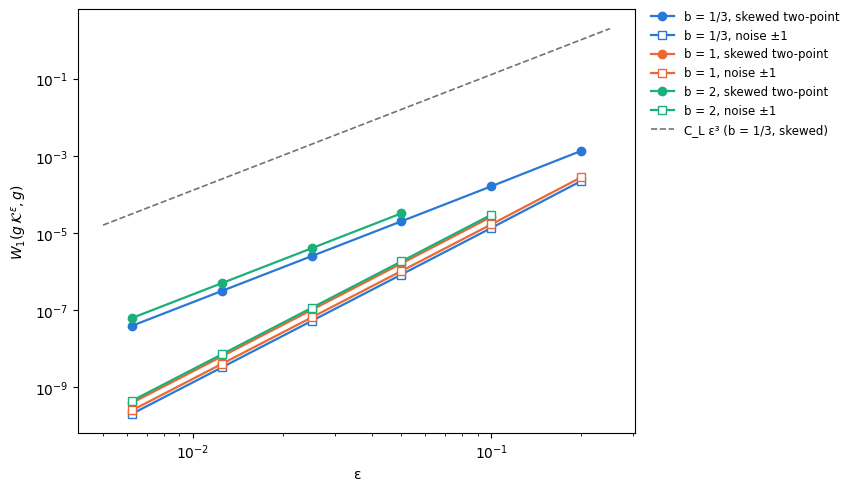

In [44]:
fig, ax = plt.subplots(figsize=(8.4, 4.8), layout="constrained")
for (b, col) in ((1/3, colB), (1.0, colO), (2.0, colA)):
    for k, mk, fc in (("two", "o", None), ("pm1", "s", "white")):
        r = next(r for r in defTab if r["b"] == b and r["noise"] == k)
        ax.loglog(r["eps"], r["w1"], "-" + mk, color=col, mfc=fc if fc else col, ms=6, lw=1.6,
                  label=f"b = {'1/3' if b < 0.5 else int(b)}, {'skewed two-point' if k == 'two' else 'noise ±1'}")
ee = np.array([0.005, 0.25]); ax.loglog(ee, float(clOf(mpf(1)/3, 1, m3["two"]))*ee**3, "--", color="0.45", lw=1.2, label="C_L ε³ (b = 1/3, skewed)")
ax.set_xlabel("ε"); ax.set_ylabel(r"$W_1(g\,\mathcal{K}^\varepsilon, g)$")
fig.legend(loc="outside right upper", frameon=False, fontsize=8.5)
plt.show()

## 7. Sec. V: Proposition C (the range of $q$) and Corollary D (the Cauchy law, $q=2$)
Proposition C shows that for fixed $b$ no index $q\ge2$ occurs. Corollary D obtains the Cauchy law as the limit of a triangular array in which $b_N\to\infty$ slowly, with $c_N=c(1+b_N)$; its proof combines four facts (the limit law keeps its scale, it approaches the Cauchy law, a bounded-Lipschitz distance handles laws without a first moment, and the constants of Theorem B grow slowly enough with $b$).

**Claim (Proposition C).** $b\mapsto q=(1+4b)/(1+2b)$ has derivative $2/(1+2b)^2>0$; it maps $(0,\infty)$ onto $(1,2)$ and $(-\tfrac12,0)$ onto $(-\infty,1)$. A $q$-Gaussian on the line with $1<q<3$, $\propto[1+(q-1)By^2]^{-1/(q-1)}$, decays like $|y|^{-2/(q-1)}$, and $2/(q-1)\in(1,2]$ for $2\le q<3$; but $g_b|y|^{2+1/b}\to Z_b^{-1}b^{-\kappa}$, so $g_b$ decays with exponent $2+1/b>2$ for $b>0$, and vanishes outside $(-L,L)$ for $b<0$.

**How it is checked.** Derivative and limits symbolically; the decay exponents symbolically; the limit of $g_bZ_b|y|^{2+1/b}$ for $b=\tfrac13,1,2$.

In [45]:
qq = sp.symbols('q', real=True)
check("Prop. C: dq/db = 2/(1+2b)^2 > 0; q -> 1 as b -> 0, q -> 2 as b -> Infinity, q -> -Infinity as b -> -1/2 from above",
      sp.simplify(sp.diff(qS, bs) - 2/(1 + 2*bs)**2) == 0 and sp.limit(qS, bs, 0) == 1 and sp.limit(qS, bs, sp.oo) == 2 and sp.limit(qS, bs, R(-1, 2), '+') == -sp.oo)
check("Prop. C: [1 + (q-1) B y^2]^(-1/(q-1)) |y|^(2/(q-1)) -> ((q-1) B)^(-1/(q-1)), and 2/(q-1) lies in (1, 2] for 2 <= q < 3",
      all(sp.limit((1 + (q - 1)*Bv*ys**2)**(-1/(q - 1))*ys**(2/(q - 1)), ys, sp.oo) == ((q - 1)*Bv)**(-1/(q - 1)) for q in (R(3, 2), R(2), R(5, 2)) for Bv in (1, 3))
      and sp.diff(2/(qq - 1), qq).subs(qq, R(5, 2)) < 0 and 2/(R(2) - 1) == 2 and sp.limit(2/(qq - 1), qq, 3) == 1)
check("Prop. C: g_b |y|^(2+1/b) -> b^(-kappa)/Z_b, so the tail exponent is 2 + 1/b > 2 (b = 1/3, 1, 2; c = 1)",
      all(sp.limit((1 + b*ys**2)**(-kap(b))*ys**(2 + 1/b), ys, sp.oo) == b**(-kap(b)) for b in (R(1, 3), R(1), R(2))) and all(2 + 1/b > 2 for b in (R(1, 100), 1, 100)))

PASS   Prop. C: dq/db = 2/(1+2b)^2 > 0; q -> 1 as b -> 0, q -> 2 as b -> Infinity, q -> -Infinity as b -> -1/2 from above
PASS   Prop. C: [1 + (q-1) B y^2]^(-1/(q-1)) |y|^(2/(q-1)) -> ((q-1) B)^(-1/(q-1)), and 2/(q-1) lies in (1, 2] for 2 <= q < 3
PASS   Prop. C: g_b |y|^(2+1/b) -> b^(-kappa)/Z_b, so the tail exponent is 2 + 1/b > 2 (b = 1/3, 1, 2; c = 1)


True

**Claim (Remark after Proposition C).** For $b>0$ the variance of $g_b$ is finite exactly when $2+1/b>3$, i.e. $b<1$, or $q<5/3$. Taking expectations in (II.1) gives $E[S_{n+1}^2]=(1+b/n)E[S_n^2]+c$, so that $E[S_n^2]/n\to c/(1-b)$ for $b<1$, $E[S_n^2]/n$ grows like $c\ln n$ for $b=1$, and like a constant times $n^{b-1}$ for $b>1$; the unconditional variances $E[X_{n+1}^2]=c+bE[S_n^2]/n$ of the summands are finite but unbounded for $b\ge1$.

**How it is checked.** The equivalences symbolically; the moment recursion against the exact law of $S_n$ (enumeration, skewed two-point noise); for $b=1$ the exact solution $E[S_n^2]=c\,nH_n$ ($H_n$ the harmonic number); for $b=\tfrac13$ and $b=2$ the recursion iterated to $n=10^7$ (in closed form with Gamma functions).

In [46]:
check("Remark after Prop. C: 2 + 1/b > 3 <=> b < 1 <=> q < 5/3 (b > 0)",
      all(((2 + 1/b > 3) == (b < 1)) and ((qOf(b) < R(5, 3)) == (b < 1)) for b in (R(1, 10), R(1, 3), R(99, 100), 1, R(101, 100), 2, 10))
      and sp.solve(sp.Eq(qS, R(5, 3)), bs) == [1])
def m2rec(b, c, n):
    """E S_n^2 from the recursion E S_(k+1)^2 = (1 + b/k) E S_k^2 + c, E S_1^2 = c"""
    m = c
    for k in range(1, n): m = (1 + b/k)*m + c
    return m
check("Remark after Prop. C: E[S_(n+1)^2 | F_n] = S_n^2 + c + b S_n^2/n, and E S_n^2 from the recursion equals the exact value (skewed two-point noise, b = 1/3, 2, c = 13/10, n = 1..12)",
      sp.expand(sS_**2 + (cc_ + bs*sS_**2/nn_) - ((1 + bs/nn_)*sS_**2 + cc_)) == 0
      and all(abs(np.sum(lawY(b, 1.3, "two", n)[1]*lawY(b, 1.3, "two", n)[0]**2)*n - m2rec(b, 1.3, n)) < 1e-9*m2rec(b, 1.3, n) for b in (1/3, 2.0) for n in range(1, 13)))
Hs_ = sp.symbols('H', positive=True)
check("Remark after Prop. C, b = 1: E S_n^2 = c n H_n solves the recursion with E S_1^2 = c (using H_(n+1) = H_n + 1/(n+1)), so E S_n^2/n ~ c ln n",
      sp.simplify((1 + 1/nS)*cs*nS*Hs_ + cs - cs*(nS + 1)*(Hs_ + 1/(nS + 1))) == 0 and m2rec(1.0, 1.0, 1) == 1.0
      and all(abs(m2rec(1.0, 1.3, n) - 1.3*n*sum(1/k for k in range(1, n + 1))) < 1e-9*n*n for n in (2, 10, 1000))
      and abs(float(sum(1/k for k in range(1, 10**6 + 1)))/math.log(1e6) - 1) < 0.05)
def m2n(b, c, n):
    """E S_n^2 from the recursion, in closed form: P_n = Gamma(n+b)/(Gamma(1+b) Gamma(n)), m_n = P_n (c + c sum_(k=2..n) 1/P_k)"""
    k = np.arange(1, n + 1, dtype=float); logP = special.gammaln(k + b) - special.gammaln(1 + b) - special.gammaln(k)
    return np.exp(logP)*(c + c*np.concatenate([[0.0], np.cumsum(np.exp(-logP[1:]))]))
mA, mB = m2n(1/3, 1.0, 10**7), m2n(2.0, 1.0, 10**7)
check("Remark after Prop. C: E S_n^2/n -> c/(1-b) = 3/2 for b = 1/3 (n = 10^7, within 1e-3), and E S_n^2/n^b tends to a constant for b = 2 (ratio at n = 10^6 and 10^7 within 1e-5)",
      abs(mA[-1]/1e7 - 1.5) < 1e-3 and abs((mB[-1]/1e14)/(mB[10**6 - 1]/1e12) - 1) < 1e-5
      and all(abs(m2n(b, 1.0, 12)[-1]/m2rec(b, 1.0, 12) - 1) < 1e-12 for b in (1/3, 2.0)))

PASS   Remark after Prop. C: 2 + 1/b > 3 <=> b < 1 <=> q < 5/3 (b > 0)
PASS   Remark after Prop. C: E[S_(n+1)^2 | F_n] = S_n^2 + c + b S_n^2/n, and E S_n^2 from the recursion equals the exact value (skewed two-point noise, b = 1/3, 2, c = 13/10, n = 1..12)
PASS   Remark after Prop. C, b = 1: E S_n^2 = c n H_n solves the recursion with E S_1^2 = c (using H_(n+1) = H_n + 1/(n+1)), so E S_n^2/n ~ c ln n
PASS   Remark after Prop. C: E S_n^2/n -> c/(1-b) = 3/2 for b = 1/3 (n = 10^7, within 1e-3), and E S_n^2/n^b tends to a constant for b = 2 (ratio at n = 10^6 and 10^7 within 1e-5)


True

**Claim (Corollary D, proof, first and second facts).** With $c_b=c(1+b)$, $g_b$ is the law of $\sqrt{c_b/(1+b)}\,T_\nu=\sqrt c\,T_\nu$, $\nu=1+1/b$, so its scale does not change with $b$. As $\nu\to1$, $f_\nu\to f_1$, the Cauchy density $1/(\pi(1+t^2))$, pointwise, and by Scheffé's lemma $\int|f_\nu-f_1|\to0$ (V.1). Appendix C 3 adds that this $L^1$ distance is about $0.4/b$, and that the Kolmogorov distance between $g_b$ and the Cauchy law is about $0.1/b$ — $0.0174$, $0.0048$ and $0.0020$ for $b=5,20,50$ (Table IV) — so that $g_{50}$ is within $0.002$ of the Cauchy law (Sec. II A, panel (j) of Fig. 1).

**How it is checked.** The density of $g_b$ with $c_b$ against $\sqrt c\,T_\nu$; $f_1$ symbolically; the $L^1$ distance by numerical integration for $b=5,\dots,1000$ (it decreases, and $b\cdot L^1$ approaches $0.40$; at $b=5$ it is $0.35$); the Kolmogorov distance $\sup_t|F_\nu(t)-F_1(t)|$ by maximization on a fine logarithmic grid.

In [47]:
check("Cor. D, first fact: with c_b = c(1+b), g_b is the law of Sqrt[c] T_nu, nu = 1 + 1/b (b = 1, 5, 50; c = 1, 23/10)",
      all(close(gb(y, P(b), P(c)*(1 + P(b))), stats.t.pdf(y/math.sqrt(float(c)), 1 + 1/b)/math.sqrt(float(c)), 1e-10) for b in (1, 5, 50) for c in (1, R(23, 10)) for y in (-3.5, 0, 1/3, 5)))
nuS = sp.symbols('nu', positive=True)
fnu = sp.gamma((nuS + 1)/2)/(sp.sqrt(nuS*sp.pi)*sp.gamma(nuS/2))*(1 + ts**2/nuS)**(-(nuS + 1)/2)
check("Cor. D, second fact: f_1 = 1/(Pi (1 + t^2)) (the Cauchy density), and f_nu(t) -> f_1(t) as nu -> 1",
      sp.simplify(fnu.subs(nuS, 1) - 1/(sp.pi*(1 + ts**2))) == 0 and sp.simplify(sp.limit(fnu, nuS, 1) - 1/(sp.pi*(1 + ts**2))) == 0)
def l1Dist(b):
    nu = 1 + 1/mpf(b); f = lambda t: abs(mp.gamma((nu + 1)/2)/(mp.sqrt(nu*mp.pi)*mp.gamma(nu/2))*(1 + t**2/nu)**(-(nu + 1)/2) - 1/(mp.pi*(1 + t**2)))
    return 2*mp.quad(f, [0, 0.5, 1, 1.5, 2, 3, 5, 10, 100, 10**4, mp.inf])
l1Tab = [(b, float(l1Dist(b))) for b in (5, 20, 50, 200, 1000)]
print("b, L1 distance, b * L1:", [(b, round(v, 6), round(b*v, 4)) for b, v in l1Tab])
check("(V.1) and App. C 3: the L1 distance between f_nu and f_1 decreases in b and is about 0.4/b (b L1 = 0.35, 0.39, 0.40 for b = 5, 20, 50, and within 0.01 of 0.40 for b = 200, 1000)",
      all(l1Tab[i][1] > l1Tab[i + 1][1] for i in range(4)) and all(0.34 < b*v < 0.41 for b, v in l1Tab) and all(abs(b*v - 0.40) < 0.01 for b, v in l1Tab[3:]))
def ksExact(b):
    tt = 10**np.arange(-4, 7, 0.0005); nu = 1 + 1/b
    return float(np.max(np.abs(stats.t.cdf(tt, nu) - stats.cauchy.cdf(tt))))
ksEx = {b: ksExact(b) for b in (5, 20, 50, 1000)}
print("exact Kolmogorov distance g_b vs Cauchy:", {b: round(v, 6) for b, v in ksEx.items()})
check("Table IV, App. C 3 and Sec. II A: the exact Kolmogorov distance between g_b and the Cauchy law is 0.0174, 0.0048, 0.0020 for b = 5, 20, 50 (below 0.002 for b = 50), and about 0.1/b for large b",
      abs(ksEx[5] - 0.017423) < 2e-5 and abs(ksEx[20] - 0.004844) < 2e-5 and abs(ksEx[50] - 0.001982) < 2e-5 and ksEx[50] < 0.002 and abs(1000*ksEx[1000] - 0.1006) < 0.002)

PASS   Cor. D, first fact: with c_b = c(1+b), g_b is the law of Sqrt[c] T_nu, nu = 1 + 1/b (b = 1, 5, 50; c = 1, 23/10)
PASS   Cor. D, second fact: f_1 = 1/(Pi (1 + t^2)) (the Cauchy density), and f_nu(t) -> f_1(t) as nu -> 1
b, L1 distance, b * L1: [(5, 0.069693, 0.3485), (20, 0.019378, 0.3876), (50, 0.007929, 0.3964), (200, 0.002005, 0.401), (1000, 0.000402, 0.4023)]
PASS   (V.1) and App. C 3: the L1 distance between f_nu and f_1 decreases in b and is about 0.4/b (b L1 = 0.35, 0.39, 0.40 for b = 5, 20, 50, and within 0.01 of 0.40 for b = 200, 1000)
exact Kolmogorov distance g_b vs Cauchy: {5: 0.017423, 20: 0.004844, 50: 0.001982, 1000: 0.000101}
PASS   Table IV, App. C 3 and Sec. II A: the exact Kolmogorov distance between g_b and the Cauchy law is 0.0174, 0.0048, 0.0020 for b = 5, 20, 50 (below 0.002 for b = 50), and about 0.1/b for large b


True

**Claim (Corollary D, proof, fourth fact (a)).** The Beta integral (V.3): $\int(c_b+by^2)^{-s}dy=c_b^{1/2-s}\sqrt{\pi/b}\,\Gamma(s-\tfrac12)/\Gamma(s)$ for $s>\tfrac12$; with $s=\kappa$ and $s=\kappa-\tfrac12$ it gives $a_1=\sqrt{c_b}\,\Gamma(\kappa-1)\Gamma(\kappa)/\Gamma(\kappa-\tfrac12)^2$. With $x=\kappa-1=1/(2b)\in(0,\tfrac12]$: $\Gamma(x)\le1/x$, $\Gamma(1+x)\le1$, $\Gamma(\tfrac12+x)\ge1$, hence $a_1\le2b\sqrt{c_b}$.

**How it is checked.** (V.3) by numerical integration; the ratio symbolically; the three Gamma inequalities on fine grids; $a_1\le2b\sqrt{c_b}$ for $b$ from 1 to $10^5$ (since $a_1\propto\sqrt{c_b}$, $c_b=1$ suffices).

In [48]:
check("(V.3): Int (c + b y^2)^(-s) dy = c^(1/2-s) Sqrt[Pi/b] Gamma(s-1/2)/Gamma(s) (numerical; s = 3/4, 1, 3/2, 3; b = 1/2, 2, 50; c = 1, 23/5)",
      all(close(2*mp.quad(lambda y: (P(c) + P(b)*y**2)**(-P(s)), [0, 1, 10, mp.inf]), P(c)**(mpf(1)/2 - P(s))*mp.sqrt(mp.pi/P(b))*mp.gamma(P(s) - mpf(1)/2)/mp.gamma(P(s)), 1e-10)
          for s in (R(3, 4), 1, R(3, 2), 3) for b in (R(1, 2), 2, 50) for c in (1, R(23, 5))))
kk2 = sp.symbols('k', positive=True)
check("Cor. D (a): (V.3) with s = kappa - 1/2 divided by (V.3) with s = kappa gives a_1 = Sqrt[c] Gamma(kappa-1) Gamma(kappa)/Gamma(kappa-1/2)^2",
      sp.simplify((cp**(R(1, 2) - (kk2 - R(1, 2)))*sp.gamma(kk2 - 1)/sp.gamma(kk2 - R(1, 2)))/(cp**(R(1, 2) - kk2)*sp.gamma(kk2 - R(1, 2))/sp.gamma(kk2))
                  - sp.sqrt(cp)*sp.gamma(kk2 - 1)*sp.gamma(kk2)/sp.gamma(kk2 - R(1, 2))**2) == 0)
xs_ = np.arange(1, 1001)/1000
check("Cor. D (a): Gamma(x) <= 1/x and Gamma(1+x) <= 1 for 0 < x <= 1; Gamma(1/2+x) >= 1 for 0 < x <= 1/2 (step 1/1000)",
      np.all(special.gamma(xs_) <= 1/xs_ + 1e-12) and np.all(special.gamma(1 + xs_) <= 1 + 1e-12) and np.all(special.gamma(0.5 + xs_[xs_ <= 0.5]) >= 1 - 1e-12))
bBig = 10**np.arange(0, 5.001, 0.05)
a1Big = np.array([float(a1Of(b, 1)) for b in bBig])
check("Cor. D (a): a_1 <= 2 b Sqrt[c_b] for b >= 1 (c_b = 1; b = 1..10^5)", np.all(a1Big <= 2*bBig + 1e-12))

PASS   (V.3): Int (c + b y^2)^(-s) dy = c^(1/2-s) Sqrt[Pi/b] Gamma(s-1/2)/Gamma(s) (numerical; s = 3/4, 1, 3/2, 3; b = 1/2, 2, 50; c = 1, 23/5)
PASS   Cor. D (a): (V.3) with s = kappa - 1/2 divided by (V.3) with s = kappa gives a_1 = Sqrt[c] Gamma(kappa-1) Gamma(kappa)/Gamma(kappa-1/2)^2
PASS   Cor. D (a): Gamma(x) <= 1/x and Gamma(1+x) <= 1 for 0 < x <= 1; Gamma(1/2+x) >= 1 for 0 < x <= 1/2 (step 1/1000)
PASS   Cor. D (a): a_1 <= 2 b Sqrt[c_b] for b >= 1 (c_b = 1; b = 1..10^5)


True

**Claim (Corollary D, proof, (b)–(d)).** (b) $6/b\le6\le6b$ and $33\le33b$ give $C_L\le a_1M_3(39+41.5)b\le161M_3b^2\sqrt{c_b}$. (c) $E|Y_1|\le\sqrt{c_b}$ and $E|Y_{n+1}|\le(1+\sqrt b)E|Y_n|+\sqrt{c_b}$ give $E|Y_3|\le(3+3\sqrt b+b)\sqrt{c_b}$; with $E_g|Y|\le a_1/\sqrt b\le2\sqrt b\sqrt{c_b}$, $W_1(\mathrm{Law}(Y_3),g_b)\le(3+5\sqrt b+b)\sqrt{c_b}\le9b\sqrt{c_b}$. (d) Inserting into (II.5) with $\sqrt{c_b}\le\sqrt{2b}\sqrt c$, $9\sqrt3\le16$, $\ln(N/3)\le\ln N$, $b\le b^2$, $M_3\ge1$ gives (V.4): $W_1\le\Lambda\sqrt{2b}\sqrt c\,(16b+161M_3b^2\ln N)/\sqrt N\le251M_3\sqrt c\,b^{5/2}\Lambda(1+\ln N)/\sqrt N$.

**How it is checked.** (b) on a grid of $b$ and $M_3$; (c) the iteration symbolically and $E|Y_3|$ *exactly* by enumerating the noise values of the first three steps (three discrete noise laws); $E_g|Y|$ against its closed form for $\sqrt cT_\nu$; $3+5u+u^2\le9u^2$ for $u=\sqrt b\ge1$ by factorization; (d) the constants symbolically and the whole of (V.4) on a grid of $b$, $N$ and $M_3$.

In [49]:
check("Cor. D (b): C_L <= a_1 M3 (39 + 41.5) b and 80.5 a_1 <= 161 b Sqrt[c_b], hence C_L <= 161 M3 b^2 Sqrt[c_b] (b = 1..10^5; M3 = 1, 17/10, 5)",
      all(float(clOf(b, 1 + b, M)) <= 161*M*b*b*math.sqrt(1 + b)*(1 + 1e-12) and 33 + 41.5*b + 6/b <= 80.5*b + 1e-9 for b in bBig for M in (1, 1.7, 5)))
uS2 = sp.symbols('u', positive=True)
it1 = 1; it2 = (1 + uS2)*it1 + 1; it3 = sp.expand((1 + uS2)*it2 + 1)
check("Cor. D (c): iterating E|Y_(n+1)| <= (1 + Sqrt[b]) E|Y_n| + Sqrt[c_b] from E|Y_1| <= Sqrt[c_b] gives (3 + 3 Sqrt[b] + b) Sqrt[c_b] for n = 3; and 3 + 5u + u^2 <= 9 u^2 for u = Sqrt[b] >= 1, since 9u^2 - (3 + 5u + u^2) = (u - 1)(8u + 3)",
      sp.simplify(it3 - (3 + 3*uS2 + uS2**2)) == 0 and sp.expand(9*uS2**2 - (3 + 5*uS2 + uS2**2) - (uS2 - 1)*(8*uS2 + 3)) == 0)
def eY3(b, cb, k):
    """E|Y_3| exactly, by enumerating the noise values of the first three steps"""
    tot = 0.0
    for (x1, p1), (x2, p2), (x3, p3) in itertools.product(natoms[k], repeat=3):
        y = math.sqrt(cb)*x1
        for n, x in ((1, x2), (2, x3)): y = math.sqrt(n/(n + 1))*y + math.sqrt(cb + b*y*y)/math.sqrt(n + 1)*x
        tot += abs(y)*p1*p2*p3
    return tot
check("Cor. D (c): E|Y_3| <= (3 + 3 Sqrt[b] + b) Sqrt[c_b], exact for the noise +1/-1, three-point and skewed two-point (b = 1, 2, 5, 50, 1000; c = 1, 23/10)",
      all(eY3(b, c*(1 + b), k) <= (3 + 3*math.sqrt(b) + b)*math.sqrt(c*(1 + b)) for k in ("pm1", "three", "two") for b in (1, 2, 5, 50, 1000) for c in (1, 2.3)))
def eAbsG(b): nu = 1 + 1/mpf(b); return 2*mp.sqrt(nu)*mp.gamma((nu + 1)/2)/(mp.sqrt(mp.pi)*(nu - 1)*mp.gamma(nu/2))
check("Cor. D (c): E_g|Y| = 2 Sqrt[c nu] Gamma((nu+1)/2)/(Sqrt[Pi] (nu-1) Gamma(nu/2)) for Sqrt[c] T_nu (numerical, b = 1, 3, 5), and E_g|Y| <= a_1/Sqrt[b] <= 2 Sqrt[b] Sqrt[c_b] (b = 1..10^4)",
      all(close(eAbsG(b), 2*mp.quad(lambda y: y*gb(y, b, 1 + b), [0, 1, 10, 100, 10**4, mp.inf]), 1e-6) for b in (1, 3, 5))
      and all(eAbsG(b) <= a1Of(b, 1 + b)/mp.sqrt(b)*(1 + mpf(10)**-12) and a1Of(b, 1 + b)/mp.sqrt(b) <= 2*mp.sqrt(b)*mp.sqrt(1 + b) for b in 10**np.arange(0, 4.001, 0.05)))
check("Cor. D (d): Sqrt[c_b] <= Sqrt[2b] Sqrt[c] for b >= 1; 9 Sqrt[3] <= 16; Sqrt[2](16 b^(3/2) + 161 M3 b^(5/2) ln N) <= Sqrt[2] 161 M3 b^(5/2) (1 + ln N) and Sqrt[2] 161 = 227.7 <= 251",
      all(1 + b <= 2*b for b in (1, 2, 100)) and 9*math.sqrt(3) <= 16 and math.sqrt(2)*161 <= 251
      and all(math.sqrt(2)*(16*b**1.5 + 161*M*b**2.5*math.log(N)) <= math.sqrt(2)*161*M*b**2.5*(1 + math.log(N)) for b in (1, 3, 100) for M in (1, 1.7) for N in (3, 1e5, 1e12)))
check("(V.4): Sqrt[3/N] 9 b Sqrt[c_b] + 161 M3 b^2 Sqrt[c_b] ln(N/3)/Sqrt[N] <= 251 M3 Sqrt[c] b^(5/2) (1 + ln N)/Sqrt[N] (c = 1; b = 1..10^4; N = 3..10^12; M3 = 1, 17/10, 5)",
      all(math.sqrt(3/N)*9*b*math.sqrt(1 + b) + 161*M*b*b*math.sqrt(1 + b)*math.log(N/3)/math.sqrt(N) <= 251*M*b**2.5*(1 + math.log(N))/math.sqrt(N)
          for b in 10**np.arange(0, 4.01, 0.1) for N in [3, 4, 10] + list(10**np.arange(2, 12.01, 0.5)) for M in (1, 1.7, 5)))

PASS   Cor. D (b): C_L <= a_1 M3 (39 + 41.5) b and 80.5 a_1 <= 161 b Sqrt[c_b], hence C_L <= 161 M3 b^2 Sqrt[c_b] (b = 1..10^5; M3 = 1, 17/10, 5)
PASS   Cor. D (c): iterating E|Y_(n+1)| <= (1 + Sqrt[b]) E|Y_n| + Sqrt[c_b] from E|Y_1| <= Sqrt[c_b] gives (3 + 3 Sqrt[b] + b) Sqrt[c_b] for n = 3; and 3 + 5u + u^2 <= 9 u^2 for u = Sqrt[b] >= 1, since 9u^2 - (3 + 5u + u^2) = (u - 1)(8u + 3)
PASS   Cor. D (c): E|Y_3| <= (3 + 3 Sqrt[b] + b) Sqrt[c_b], exact for the noise +1/-1, three-point and skewed two-point (b = 1, 2, 5, 50, 1000; c = 1, 23/10)
PASS   Cor. D (c): E_g|Y| = 2 Sqrt[c nu] Gamma((nu+1)/2)/(Sqrt[Pi] (nu-1) Gamma(nu/2)) for Sqrt[c] T_nu (numerical, b = 1, 3, 5), and E_g|Y| <= a_1/Sqrt[b] <= 2 Sqrt[b] Sqrt[c_b] (b = 1..10^4)
PASS   Cor. D (d): Sqrt[c_b] <= Sqrt[2b] Sqrt[c] for b >= 1; 9 Sqrt[3] <= 16; Sqrt[2](16 b^(3/2) + 161 M3 b^(5/2) ln N) <= Sqrt[2] 161 M3 b^(5/2) (1 + ln N) and Sqrt[2] 161 = 227.7 <= 251
PASS   (V.4): Sqrt[3/N] 9 b Sqrt[c_b] + 161 M3 b^2 Sqrt[c_b] ln(N/3)/Sqrt

True

**Claim (Corollary D, proof, final step, and II.6).** $\Lambda=\exp(4\sqrt2(\zeta(\tfrac32)-1)M_3b_N^{3/2})\le N^\chi$ with $\chi=4\sqrt2(\zeta(\tfrac32)-1)M_3\theta=\theta/(2\theta_*)<\tfrac12$; $b_N^{5/2}\le(\theta\ln N)^{5/3}$; and $(\theta\ln N)^{5/3}(1+\ln N)N^{\chi-1/2}\to0$. Along the array $q_N\to2$.

**How it is checked.** $\theta_*\approx0.054819/M_3$ and $\chi=\theta/(2\theta_*)$ symbolically; $\Lambda=N^\chi$ when $b^{3/2}=\theta\ln N$ (several $\theta$, $M_3$, $N$); the limit symbolically for $\theta=\tfrac1{20}$, $\chi=\tfrac{49}{100}$; $q\to2$.

In [50]:
zS, mS, thS = sp.symbols('z m theta', positive=True)
check("(II.6): theta_* = 1/(8 Sqrt[2] (Zeta(3/2) - 1) M3) = 0.054819/M3, and chi = 4 Sqrt[2] (Zeta(3/2) - 1) M3 theta = theta/(2 theta_*)",
      close(1/(8*mp.sqrt(2)*(mp.zeta(1.5) - 1)), 0.0548187, 1e-5) and sp.simplify(4*sp.sqrt(2)*(zS - 1)*mS*thS - thS/(2/(8*sp.sqrt(2)*(zS - 1)*mS))) == 0)
check("Cor. D, final step: if b^(3/2) = theta ln N, then Lambda = N^chi, and b^(5/2) = (theta ln N)^(5/3) (theta = 1/100, 1/30; M3 = 1, 17/10; N = 10, 10^5, 10^12)",
      all(close(lamOf((th*mp.log(N))**(mpf(2)/3), M), mpf(N)**(4*mp.sqrt(2)*(mp.zeta(1.5) - 1)*M*th), 1e-20) and close(((th*mp.log(N))**(mpf(2)/3))**2.5, (th*mp.log(N))**(mpf(5)/3), 1e-25)
          for th in (mpf(1)/100, mpf(1)/30) for M in (1, mpf(17)/10) for N in (10, 10**5, 10**12)))
check("Cor. D, final step: (theta ln N)^(5/3) (1 + ln N) N^(chi - 1/2) -> 0 when chi < 1/2 (theta = 1/20, chi = 49/100); and q_N -> 2 as b_N -> Infinity",
      sp.limit((sp.log(np_)/20)**R(5, 3)*(1 + sp.log(np_))*np_**(R(49, 100) - R(1, 2)), np_, sp.oo) == 0 and sp.limit(qS, bs, sp.oo) == 2)

PASS   (II.6): theta_* = 1/(8 Sqrt[2] (Zeta(3/2) - 1) M3) = 0.054819/M3, and chi = 4 Sqrt[2] (Zeta(3/2) - 1) M3 theta = theta/(2 theta_*)
PASS   Cor. D, final step: if b^(3/2) = theta ln N, then Lambda = N^chi, and b^(5/2) = (theta ln N)^(5/3) (theta = 1/100, 1/30; M3 = 1, 17/10; N = 10, 10^5, 10^12)
PASS   Cor. D, final step: (theta ln N)^(5/3) (1 + ln N) N^(chi - 1/2) -> 0 when chi < 1/2 (theta = 1/20, chi = 49/100); and q_N -> 2 as b_N -> Infinity


True

**Claim (Remark: an equivalent form).** With $c$ in place of $c_N$, the sums $\tilde S_n$ satisfy $\sqrt{1+b_N}\,\tilde S_n=S^{(N)}_n$, because $(1+b_N)(c+b_N\tilde S_n^2/n)=c_N+b_N(1+b_N)\tilde S_n^2/n$; so $\sqrt{(1+b_N)/N}\,\tilde S_N$ converges to the Cauchy law.

**How it is checked.** The identity symbolically, and path by path on the exact laws (enumeration, same noise sequences).

In [51]:
check("Remark (an equivalent form): (1 + b)(c + b u^2/n) = c(1 + b) + b (Sqrt[1+b] u)^2/n, and Sqrt[1+b] S~_n = S^(N)_n on every path (exact laws, b = 5, 50; n = 2..10)",
      sp.simplify((1 + bp)*(cp + bp*yp**2/np_) - (cp*(1 + bp) + bp*(sp.sqrt(1 + bp)*yp)**2/np_)) == 0
      and all(np.allclose(math.sqrt(1 + b)*lawY(b, 1.0, k, n)[0], lawY(b, 1.0 + b, k, n)[0], rtol=1e-12, atol=0) for b in (5.0, 50.0) for k in ("pm1", "two") for n in range(2, 11)))

PASS   Remark (an equivalent form): (1 + b)(c + b u^2/n) = c(1 + b) + b (Sqrt[1+b] u)^2/n, and Sqrt[1+b] S~_n = S^(N)_n on every path (exact laws, b = 5, 50; n = 2..10)


True

**Claim (Remark: the growth condition).** With $M_3=1$ (and $\theta$ at its limit $\theta_*$), $b_N=(\theta\ln N)^{2/3}$ is at most about $1.2$ at $N=10^{10}$, that is, $q_N\approx1.7$.

**How it is checked.** Direct evaluation.

In [52]:
bN = (thetaStar*mp.log(mpf(10)**10))**(mpf(2)/3)
print("b_N =", float(bN), " q_N =", float(qOf(bN)))
check("Remark (the growth condition): b_N = (theta_* ln N)^(2/3) = 1.168 at N = 10^10 (M3 = 1), and q_N = 1.70",
      abs(bN - mpf("1.168")) < 1e-3 and abs(qOf(bN) - mpf("1.70")) < 5e-3)

b_N = 1.1679646616155037  q_N = 1.7002334572749724
PASS   Remark (the growth condition): b_N = (theta_* ln N)^(2/3) = 1.168 at N = 10^10 (M3 = 1), and q_N = 1.70


True

## 8. Appendix B: Proposition E — quadratic feedback characterizes the $q$-Gaussians
Proposition E reads the identity (II.7) in the opposite direction. For a positive continuous density $g$ on $I=(-\ell,\ell)$ and a positive continuous $D$ with $(Dg)'=-yg$ and $Dg\to0$ at $\pm\ell$ (B.1): (i) $g$ has a finite first moment, mean 0, and determines $D$ through $D(y)=g(y)^{-1}\int_y^\ell t\,g(t)\,dt$ (B.2); (ii) $D=c+by^2$ iff $I=I_b$ and $g=g_b$; (iii) $g$ is a $q$-Gaussian with $q<2$ iff $D=c+by^2$ with $b>-\tfrac12$, and no $q$-Gaussian with $2\le q<3$ (in particular not the Cauchy law) satisfies (B.1) for any $D$.

**Claim (B.2), part (i).** $Q=Dg$ equals $\int_y^\ell t\,g(t)\,dt$; this function satisfies (B.1) for any density; for $g_b$ it returns $D=c+by^2$; $g_b$ is even, so $\int yg_b=0$, and $\int|y|g_b=2Q(0)=2c\,g_b(0)$.

**How it is checked.** The derivative of $\int_y^\ell t\,g(t)\,dt$ symbolically for a generic function $g$; (B.2) for $g_b$ by numerical integration (30 digits) for six values of $b$, two of $c$ and several $y$; the first absolute moment.

In [53]:
gF = sp.Function('g'); lS = sp.symbols('ell', positive=True); tI = sp.symbols('tau', real=True)
check("Prop. E (i): D = (1/g) Int_y^l t g(t) dt satisfies (D g)' = -y g for a generic function g",
      sp.simplify(sp.diff(sp.Integral(tI*gF(tI), (tI, ys, lS)), ys).doit() + ys*gF(ys)) == 0)
def tailTG(b, c, y0):
    b, c, y0 = P(b), P(c), mpf(y0); k = kap(b)
    if b > 0: return mp.quad(lambda t: t*(c + b*t**2)**(-k), [y0, y0 + 1, y0 + 10, mp.inf])/zz(b, c)
    return mp.quad(lambda t: t*(c + b*t**2)**(-k), [y0, mp.sqrt(-c/b)])/zz(b, c)
check("Prop. E (i): (B.2) applied to g_b gives D = c + b y^2 (b = 1/3, 1, 2, -1/4, -1/2, -1; c = 1, 23/10; y = 0, 1/2, 3, 20 for b > 0, y = 0, L/3, 2L/3 for b < 0)",
      all(close(tailTG(b, c, y)/gb(y, P(b), P(c)), P(c) + P(b)*mpf(y)**2, 1e-12) for b in (R(1, 3), 1, 2, R(-1, 4), R(-1, 2), -1) for c in (1, R(23, 10))
          for y in ((0, 0.5, 3, 20) if b > 0 else [f*float(mp.sqrt(-P(c)/P(b))) for f in (0, 1/3, 2/3)])))
check("Prop. E (i): g_b is even, so Int y g_b = 0, and Int |y| g_b = 2 Q(0) = 2 c g_b(0) (same b and c)",
      all(all(gb(-y, P(b), P(c)) == gb(y, P(b), P(c)) for y in (0.2, 0.5, 0.9)) and close(2*tailTG(b, c, 0), 2*P(c)*gb(0, P(b), P(c)), 1e-12)
          for b in (R(1, 3), 1, 2, R(-1, 4), R(-1, 2), -1) for c in (1, R(23, 10))))

PASS   Prop. E (i): D = (1/g) Int_y^l t g(t) dt satisfies (D g)' = -y g for a generic function g
PASS   Prop. E (i): (B.2) applied to g_b gives D = c + b y^2 (b = 1/3, 1, 2, -1/4, -1/2, -1; c = 1, 23/10; y = 0, 1/2, 3, 20 for b > 0, y = 0, L/3, 2L/3 for b < 0)
PASS   Prop. E (i): g_b is even, so Int y g_b = 0, and Int |y| g_b = 2 Q(0) = 2 c g_b(0) (same b and c)


True

**A non-quadratic example (additional).** For $g\propto e^{-y^4}$, (B.2) gives $D(y)=\tfrac{\sqrt\pi}{4}e^{y^4}\operatorname{erfc}(y^2)$: a variance function that satisfies (B.1) but is not of the form $c+by^2$ — it even decreases with $|y|$. This illustrates part (i) ($g$ determines $D$) and the "only if" of part (ii).

**How it is checked.** The closed form against numerical integration; (B.1) symbolically; a quadratic $D$ would give $(D(2)-D(0))/(D(1)-D(0))=4$; monotonicity.

In [54]:
dQuartic = lambda y: mp.sqrt(mp.pi)/4*mp.exp(mpf(y)**4)*mp.erfc(mpf(y)**2)
dQS = sp.sqrt(sp.pi)/4*sp.exp(ys**4)*sp.erfc(ys**2)
check("Prop. E (i), example: for g proportional to exp(-y^4), (B.2) gives D = (Sqrt[Pi]/4) exp(y^4) erfc(y^2), which satisfies (B.1), is not quadratic and decreases with |y|",
      all(close(mp.quad(lambda t: t*mp.exp(-t**4), [y0, y0 + 1, mp.inf])*mp.exp(mpf(y0)**4), dQuartic(y0), 1e-12) for y0 in (-1.5, -0.5, 0, 0.5, 1, 2))
      and sp.simplify(sp.diff(dQS*sp.exp(-ys**4), ys) + ys*sp.exp(-ys**4)) == 0
      and abs((dQuartic(2) - dQuartic(0))/(dQuartic(1) - dQuartic(0)) - 4) > 1 and dQuartic(2) < dQuartic(1) < dQuartic(0))

PASS   Prop. E (i), example: for g proportional to exp(-y^4), (B.2) gives D = (Sqrt[Pi]/4) exp(y^4) erfc(y^2), which satisfies (B.1), is not quadratic and decreases with |y|


True

**Claim (part (ii)).** If $D=c+by^2$, then $Q'=-(y/D)Q$ gives $Q=Q(0)\exp(-\int_0^yt/(c+bt^2)\,dt)=Q(0)(D/c)^{-1/(2b)}$ ($Q(0)e^{-y^2/(2c)}$ for $b=0$); $g=Q/D\propto D^{-1-1/(2b)}=g_b$. For $b<0$, $Q(\ell)>0$ for $\ell<L$, so the boundary condition forces $\ell=L$; for $b\ge0$, $Q>0$ for all finite $y$ and $Q\to0$ only as $|y|\to\infty$, so $\ell=\infty$.

**How it is checked.** The integral and the solutions symbolically; the boundary behaviour exactly at sample points.

In [55]:
check("Prop. E (ii): Int_0^y t/(c + b t^2) dt = ln(D/c)/(2b); Q = Q0 (D/c)^(-1/(2b)) solves Q' = -(y/D) Q with Q(0) = Q0, and Q0 exp(-y^2/(2c)) for b = 0",
      sp.simplify(sp.integrate(tp/(cp + bp*tp**2), (tp, 0, yp)) - sp.log((cp + bp*yp**2)/cp)/(2*bp)) == 0
      and sp.simplify(sp.diff(((cs + bs*ys**2)/cs)**(-1/(2*bs)), ys) + ys*((cs + bs*ys**2)/cs)**(-1/(2*bs))/(cs + bs*ys**2)) == 0
      and (((cs + bs*ys**2)/cs)**(-1/(2*bs))).subs(ys, 0) == 1
      and sp.simplify(sp.diff(sp.exp(-ys**2/(2*cs)), ys) + ys*sp.exp(-ys**2/(2*cs))/cs) == 0)
check("Prop. E (ii): g = Q/D with Q proportional to D^(-1/(2b)) is proportional to D^(-1-1/(2b)), the density g_b (II.2)",
      sp.simplify(sp.powsimp(Dsym**(-1/(2*bs))/Dsym*Dsym**kS, force=True)) == 1)
check("Prop. E (ii): for b < 0 and l < L, Q(l) = Q(0)(1 - |b| l^2/c)^(1/(2|b|)) > 0, so the boundary condition forces l = L (b = -1/4, -1/2, -1; c = 1; l = L/2, 9L/10, 99L/100)",
      all(((1 + b*ys**2)**(-1/(2*b))).subs(ys, f*sp.sqrt(-1/b)) > 0 for b in (R(-1, 4), R(-1, 2), R(-1)) for f in (R(1, 2), R(9, 10), R(99, 100)))
      and all(((1 + b*ys**2)**(-1/(2*b))).subs(ys, sp.sqrt(-1/b)) == 0 for b in (R(-1, 4), R(-1, 2), R(-1))))
check("Prop. E (ii): for b >= 0, Q(y) > 0 for every finite y and Q -> 0 as |y| -> Infinity, so l = Infinity (b = 0, 1/3, 1, 2; c = 1)",
      all(all(((sp.exp(-ys**2/2) if b == 0 else (1 + b*ys**2)**(-1/(2*b)))).subs(ys, 10**k) > 0 for k in range(4))
          and sp.limit(sp.exp(-ys**2/2) if b == 0 else (1 + b*ys**2)**(-1/(2*b)), ys, sp.oo) == 0 for b in (0, R(1, 3), R(1), R(2))))

PASS   Prop. E (ii): Int_0^y t/(c + b t^2) dt = ln(D/c)/(2b); Q = Q0 (D/c)^(-1/(2b)) solves Q' = -(y/D) Q with Q(0) = Q0, and Q0 exp(-y^2/(2c)) for b = 0
PASS   Prop. E (ii): g = Q/D with Q proportional to D^(-1/(2b)) is proportional to D^(-1-1/(2b)), the density g_b (II.2)
PASS   Prop. E (ii): for b < 0 and l < L, Q(l) = Q(0)(1 - |b| l^2/c)^(1/(2|b|)) > 0, so the boundary condition forces l = L (b = -1/4, -1/2, -1; c = 1; l = L/2, 9L/10, 99L/100)
PASS   Prop. E (ii): for b >= 0, Q(y) > 0 for every finite y and Q -> 0 as |y| -> Infinity, so l = Infinity (b = 0, 1/3, 1, 2; c = 1)


True

**Claim (part (iii)).** For $v=1-(1-q)By^2$, $q<2$, $q\ne1$: $\int_y^\ell t\,v^{1/(1-q)}dt=v(y)^{(2-q)/(1-q)}/(2B(2-q))$, so (B.2) gives $D=v/(2B(2-q))=c+by^2$ with $c=1/(2B(2-q))$ and $b=(q-1)/(2(2-q))>-\tfrac12$; inverting, $q=(1+4b)/(1+2b)$, $B=(1+2b)/(2c)$. For $q=1$, $g\propto e^{-By^2}$ gives $D=1/(2B)$. For $2\le q<3$ the $q$-Gaussian has no first moment, which (i) excludes; $q=2$ is the Cauchy law.

**How it is checked.** The integral numerically for six values of $q$ (both sides of $q=1$) and two of $B$; the algebra symbolically; the divergence of the first moment by symbolic limits; the Cauchy case symbolically.

In [56]:
Bq = sp.symbols('B', positive=True)
def vq(q, B, y): return 1 - (1 - q)*B*y**2
def lq(q, B): return 1/mp.sqrt((1 - q)*B) if q < 1 else mp.inf
check("Prop. E (iii): Int_y^l t v(t)^(1/(1-q)) dt = v(y)^((2-q)/(1-q))/(2B(2-q)) (q = -1, 0, 1/2, 7/5, 5/3, 9/5; B = 1/2, 3; y = 0 and two interior points)",
      all(close(mp.quad(lambda t: t*vq(P(q), P(B), t)**(1/(1 - P(q))), [y, lq(P(q), P(B))] if q < 1 else [y, y + 1, y + 10, mp.inf]),
                vq(P(q), P(B), y)**((2 - P(q))/(1 - P(q)))/(2*P(B)*(2 - P(q))), 1e-12)
          for q in (-1, 0, R(1, 2), R(7, 5), R(5, 3), R(9, 5)) for B in (R(1, 2), 3)
          for y in ([f*lq(P(q), P(B)) for f in (0, mpf(1)/3, mpf(4)/5)] if q < 1 else (0, 1, 7))))
check("Prop. E (iii): v/(2B(2-q)) = c + b y^2 with c = 1/(2B(2-q)) and b = (q-1)/(2(2-q)); b > -1/2 for every q < 2; inverting, q = (1+4b)/(1+2b) and B = (1+2b)/(2c)",
      sp.simplify((1 - (1 - qq)*Bq*ys**2)/(2*Bq*(2 - qq)) - (1/(2*Bq*(2 - qq)) + (qq - 1)/(2*(2 - qq))*ys**2)) == 0
      and sp.simplify((qq - 1)/(2*(2 - qq)) + R(1, 2) - 1/(2*(2 - qq))) == 0      # b + 1/2 = 1/(2(2-q)) > 0 for q < 2
      and sp.simplify(qS.subs(bs, (qq - 1)/(2*(2 - qq))) - qq) == 0
      and sp.simplify((1 + 2*(qq - 1)/(2*(2 - qq)))/(2/(2*Bq*(2 - qq))) - Bq) == 0)
check("Prop. E (iii): for q = 1, g proportional to exp(-B y^2) gives D = 1/(2B) by (B.2), the case b = 0 of c + b y^2",
      sp.simplify(sp.integrate(tI*sp.exp(-Bq*tI**2), (tI, ys, sp.oo))/sp.exp(-Bq*ys**2) - 1/(2*Bq)) == 0)
rS = sp.symbols('r', positive=True)
check("Prop. E (iii): for 2 <= q < 3 the q-Gaussian has no first moment: Int_0^r y [1 + (q-1) B y^2]^(-1/(q-1)) dy -> Infinity (q = 2, 9/4, 5/2, 11/4; B = 1, 3)",
      all(sp.limit(sp.integrate(ys*(1 + (q - 1)*B*ys**2)**(-1/(q - 1)), (ys, 0, rS)), rS, sp.oo) == sp.oo for q in (R(2), R(9, 4), R(5, 2), R(11, 4)) for B in (1, 3)))
check("Prop. E (iii): the case q = 2 is the Cauchy law: [1 + B y^2]^(-1) with B = 1/c is proportional to c/(Pi (c + y^2))",
      sp.simplify((1 + ys**2/cp)**(-1) - cp/(cp + ys**2)) == 0)

PASS   Prop. E (iii): Int_y^l t v(t)^(1/(1-q)) dt = v(y)^((2-q)/(1-q))/(2B(2-q)) (q = -1, 0, 1/2, 7/5, 5/3, 9/5; B = 1/2, 3; y = 0 and two interior points)
PASS   Prop. E (iii): v/(2B(2-q)) = c + b y^2 with c = 1/(2B(2-q)) and b = (q-1)/(2(2-q)); b > -1/2 for every q < 2; inverting, q = (1+4b)/(1+2b) and B = (1+2b)/(2c)
PASS   Prop. E (iii): for q = 1, g proportional to exp(-B y^2) gives D = 1/(2B) by (B.2), the case b = 0 of c + b y^2
PASS   Prop. E (iii): for 2 <= q < 3 the q-Gaussian has no first moment: Int_0^r y [1 + (q-1) B y^2]^(-1/(q-1)) dy -> Infinity (q = 2, 9/4, 5/2, 11/4; B = 1, 3)
PASS   Prop. E (iii): the case q = 2 is the Cauchy law: [1 + B y^2]^(-1) with B = 1/c is proportional to c/(Pi (c + y^2))


True

## 9. Sec. VI: two statements of the conclusions
The conclusions compare the feedback mechanism with Lévy's mechanism and with Gaussian mixtures built from exchangeable variables. Two of their statements are quantitative and are checked here.

**Claim (Sec. VI, bounded steps).** With bounded noise each summand changes the sum by at most a bounded amount plus a fraction of order $n^{-1/2}$ of its current size: $|X_{n+1}|\le K\sigma(S_n/\sqrt n)\le K\sqrt c+K\sqrt b\,|S_n|/\sqrt n$.

**How it is checked.** The inequality $\sigma(y)\le\sqrt c+\sqrt b|y|$ (Section 5) gives it; here it is confirmed on the exact laws ($b=2$, noise $\pm1$, $n\le14$): $|S_{n+1}-S_n|\le\sqrt c+\sqrt b|S_n|/\sqrt n$ on every path.

In [57]:
def stepOK(b, c, n):
    y, w = lawY(b, c, "pm1", n); s = math.sqrt(n)*y
    return np.all(np.sqrt(c + b*y*y) <= math.sqrt(c) + math.sqrt(b)*np.abs(s)/math.sqrt(n) + 1e-12)
check("Sec. VI: |X_(n+1)| = sigma(Y_n) |xi| <= K (Sqrt[c] + Sqrt[b] |S_n|/Sqrt[n]) on every path (b = 2, noise +1/-1, K = 1; n = 1..14)",
      all(stepOK(2.0, 1.0, n) for n in range(1, 15)))

PASS   Sec. VI: |X_(n+1)| = sigma(Y_n) |xi| <= K (Sqrt[c] + Sqrt[b] |S_n|/Sqrt[n]) on every path (b = 2, noise +1/-1, K = 1; n = 1..14)


True

**Claim (Sec. VI, Gaussian mixtures).** For Gaussian mixtures whose inverse variance has a Gamma law (which have Student marginals), the conditional variance of the next increment given $S_n$ *alone* equals $c+bS_n^2/n$, exactly the form of the feedback mechanism; given the whole past it depends on $X_1^2+\dots+X_n^2$. This is why the second test of the conclusions must condition on the whole past.

**How it is checked.** Let $X_i\mid\lambda$ be i.i.d. $N(0,1/\lambda)$ with $\lambda\sim\mathrm{Gamma}(\alpha,\text{rate }\beta)$. Then $S_n\mid\lambda\sim N(0,n/\lambda)$ and $E[X_{n+1}^2\mid S_n]=E[1/\lambda\mid S_n]$. By conjugacy, $\lambda\mid S_n\sim\mathrm{Gamma}(\alpha+\tfrac12,\beta+S_n^2/(2n))$, so $E[X_{n+1}^2\mid S_n]=\frac{\beta+S_n^2/(2n)}{\alpha-1/2}=c+b\,S_n^2/n$ with $c=\beta/(\alpha-\tfrac12)$ and $b=1/(2\alpha-1)$; the marginal of $S_n/\sqrt n$ is Student's law with $\nu=2\alpha=1+1/b$ degrees of freedom and squared scale $\beta/\alpha=c/(1+b)$, which is exactly $g_b$. Given the whole past, $\lambda\mid X_1,\dots,X_n\sim\mathrm{Gamma}(\alpha+\tfrac n2,\beta+\tfrac12\sum X_i^2)$. Both posterior means are computed by numerical integration over $\lambda$ and compared with the formulas.

In [58]:
def condVar(alpha, beta, n, s=None, sumsq=None):
    """E[1/lambda | data] by integrating over lambda; data: S_n = s, or X_1..X_n with sum of squares sumsq"""
    alpha, beta = mpf(alpha), mpf(beta)
    prior = lambda l: l**(alpha - 1)*mp.exp(-beta*l)
    like = (lambda l: mp.sqrt(l/n)*mp.exp(-l*mpf(s)**2/(2*n))) if s is not None else (lambda l: l**(mpf(n)/2)*mp.exp(-l*mpf(sumsq)/2))
    num = mp.quad(lambda l: prior(l)*like(l)/l, [0, 1, 10, mp.inf]); den = mp.quad(lambda l: prior(l)*like(l), [0, 1, 10, mp.inf])
    return num/den
alS, beS = sp.symbols('alpha beta', positive=True)
mixOK = all(close(condVar(al, be, n, s=s), be/(al - mpf(1)/2) + 1/(2*al - 1)*mpf(s)**2/n, 1e-12)
            for al, be in ((mpf(2), mpf(1)), (mpf(3)/2, mpf(7)/10)) for n in (1, 5, 40) for s in (0, 1.3, -4.0))
pastOK = all(close(condVar(al, be, n, sumsq=q2), (be + mpf(q2)/2)/(al + mpf(n)/2 - 1), 1e-12)
             for al, be in ((mpf(2), mpf(1)),) for n in (5, 40) for q2 in (2.0, 9.0))
check("Sec. VI: for Gaussian mixtures with Gamma(alpha, beta) inverse variance, E[X_(n+1)^2 | S_n] = c + b S_n^2/n with c = beta/(alpha - 1/2), b = 1/(2 alpha - 1), and nu = 2 alpha = 1 + 1/b",
      mixOK and sp.simplify(1 + (2*alS - 1) - 2*alS) == 0)
check("Sec. VI: the marginal of S_n/Sqrt[n] in this mixture, Student with nu = 2 alpha and squared scale beta/alpha, is exactly g_b with these c and b: c/(1+b) = beta/alpha",
      sp.simplify((beS/(alS - R(1, 2)))/(1 + 1/(2*alS - 1)) - beS/alS) == 0)
check("Sec. VI: given the whole past, E[X_(n+1)^2 | X_1..X_n] = (beta + (X_1^2 + ... + X_n^2)/2)/(alpha + n/2 - 1) depends on the sum of squares, not only on S_n",
      pastOK and not close(condVar(2, 1, 5, sumsq=2.0), condVar(2, 1, 5, sumsq=9.0), 1e-3))

PASS   Sec. VI: for Gaussian mixtures with Gamma(alpha, beta) inverse variance, E[X_(n+1)^2 | S_n] = c + b S_n^2/n with c = beta/(alpha - 1/2), b = 1/(2 alpha - 1), and nu = 2 alpha = 1 + 1/b
PASS   Sec. VI: the marginal of S_n/Sqrt[n] in this mixture, Student with nu = 2 alpha and squared scale beta/alpha, is exactly g_b with these c and b: c/(1+b) = beta/alpha
PASS   Sec. VI: given the whole past, E[X_(n+1)^2 | X_1..X_n] = (beta + (X_1^2 + ... + X_n^2)/2)/(alpha + n/2 - 1) depends on the sum of squares, not only on S_n


True

## 10. Appendix C: the numbers of the text against the stored simulation data
The simulations of the manuscript were run with the scripts in `scripts/` (200,000 paths, $N$ up to $10^4$, $c=1$ unless stated otherwise), and their results are stored in `data/`: `sim1.json` (Table III, Fig. 1 (a, b, d, g, h, i), Fig. 2, and a run with a displaced start), `sim9_*.json` (Fig. 1 (c, e, f)), `sim7.json` (Table IV, Fig. 3), `sim8.json` (Fig. 1 (j)) and `sim2.json` (the one-step defect, Section 6). This section reads Tables III and IV from the `.tex` file and compares them, and every number quoted in the text, with the stored data. Section 11 repeats the simulations independently.

**Claim (App. C 1, the noise laws).** The six noise laws have mean 0 and variance 1: $\pm1$; three-point ($0$ w.p. $\tfrac12$, $\pm\sqrt2$ w.p. $\tfrac14$); uniform on $[-\sqrt3,\sqrt3]$; skewed two-point ($2$ w.p. $\tfrac15$, $-\tfrac12$ w.p. $\tfrac45$); Gaussian; centered exponential. Their third absolute moments, used in the constants, are $1$, $\sqrt2$, $\tfrac34\sqrt3$, $\tfrac{17}{10}$, $2\sqrt{2/\pi}$ and $12/e-2$.

**How it is checked.** Exactly (sympy) for the discrete laws and by symbolic integration for the others.

In [59]:
xI = sp.symbols('x', real=True)
check("App. C 1: the discrete noise laws have mean 0 and variance 1; E|xi|^3 = 1 (+1/-1), Sqrt[2] (three-point), 17/10 (skewed two-point)",
      all(ev(k, lambda v: v) == 0 and ev(k, lambda v: v**2) == 1 for k in atoms)
      and ev("pm1", lambda v: sp.Abs(v)**3) == 1 and sp.simplify(ev("three", lambda v: sp.Abs(v)**3) - sp.sqrt(2)) == 0 and ev("two", lambda v: sp.Abs(v)**3) == R(17, 10))
check("App. C 1: the uniform, Gaussian and centered exponential laws have mean 0 and variance 1, with E|xi|^3 = 3 Sqrt[3]/4, 2 Sqrt[2/Pi], 12/e - 2",
      sp.integrate(xI/(2*sp.sqrt(3)), (xI, -sp.sqrt(3), sp.sqrt(3))) == 0 and sp.integrate(xI**2/(2*sp.sqrt(3)), (xI, -sp.sqrt(3), sp.sqrt(3))) == 1
      and sp.simplify(sp.integrate(sp.Abs(xI)**3/(2*sp.sqrt(3)), (xI, -sp.sqrt(3), sp.sqrt(3))) - 3*sp.sqrt(3)/4) == 0
      and sp.integrate(xI**2*sp.exp(-xI**2/2)/sp.sqrt(2*sp.pi), (xI, -sp.oo, sp.oo)) == 1
      and sp.simplify(2*sp.integrate(xI**3*sp.exp(-xI**2/2)/sp.sqrt(2*sp.pi), (xI, 0, sp.oo)) - 2*sp.sqrt(2/sp.pi)) == 0
      and sp.integrate((xI - 1)*sp.exp(-xI), (xI, 0, sp.oo)) == 0 and sp.integrate((xI - 1)**2*sp.exp(-xI), (xI, 0, sp.oo)) == 1
      and sp.simplify(sp.integrate((1 - xI)**3*sp.exp(-xI), (xI, 0, 1)) + sp.integrate((xI - 1)**3*sp.exp(-xI), (xI, 1, sp.oo)) - (12/sp.E - 2)) == 0)

PASS   App. C 1: the discrete noise laws have mean 0 and variance 1; E|xi|^3 = 1 (+1/-1), Sqrt[2] (three-point), 17/10 (skewed two-point)
PASS   App. C 1: the uniform, Gaussian and centered exponential laws have mean 0 and variance 1, with E|xi|^3 = 3 Sqrt[3]/4, 2 Sqrt[2/Pi], 12/e - 2


True

**Claim (Table III).** The printed Kolmogorov distances and sampling floors.

**How it is checked.** The table is read from the `.tex` file and compared, entry by entry, with the stored data rounded to four decimals.

In [60]:
sim1 = load("sim1.json"); sim9 = {k: load(f"sim9_{k}.json") for k in ("b-1_3", "b-1_6", "b0")}; sim7 = load("sim7.json"); sim8 = load("sim8.json")
noiseName = {r"$\pm1$": "rademacher", "three-point": "three", "uniform": "uniform", "skewed two-point": "two", "Gaussian": "gauss", "centered exponential": "exp"}
def texTable(label):
    blk = TEXT[TEXT.index(r"\label{" + label + "}"):]; blk = blk[blk.index(r"\midrule") + 8:blk.index(r"\bottomrule")]
    return [[c.strip() for c in row.split("&")] for row in blk.strip().split(r"\\") if row.strip()]
def bval(s): s = s.strip("$ "); return float(sp.Rational(s)) if "/" in s else float(s)
tab3 = texTable("tab:1"); runs1 = [r for r in sim1 if r["start"] == "X1"]
print(f"Table III: {len(tab3)} rows read from the manuscript")
check("Table III: the 11 rows (b, noise, Kolmogorov distances at N = 10..10^4, floor) agree with data/sim1.json rounded to 4 decimals",
      len(tab3) == 11 and all(abs(bval(row[0]) - r["b"]) < 1e-9 and noiseName[row[1]] == r["noise"]
                              and [float(v) for v in row[2:9]] == [round(v, 4) for v in r["ks"]] and float(row[9]) == round(r["floor_ks"], 4)
                              for row, r in zip(tab3, runs1)))

Table III: 11 rows read from the manuscript
PASS   Table III: the 11 rows (b, noise, Kolmogorov distances at N = 10..10^4, floor) agree with data/sim1.json rounded to 4 decimals


True

**Claims (App. C 2, text).** The distances "decrease overall as $N$ increases, and at $N=10^4$ they are within a factor of two of the sampling floor in all eleven cases"; "the convergence is slower for skewed noise"; the sampling floor "is approximately 0.002 for this sample size" (the mean Kolmogorov statistic of an i.i.d. sample of size $M$ is about $0.8687/\sqrt M=0.0019$). The variances at the largest $N$ (not printed) agree with $c/(1-b)$ for $b<1$.

**How it is checked.** On the stored data; for the variances, within five standard errors for $b<0$ (computed from the fourth moment of $g_b$) and within 10% for $b=\tfrac13$, where the fourth moment is infinite.

In [61]:
check("App. C 2: the distance at N = 10 exceeds that at N = 10^4 in all eleven cases, and at N = 10^4 it is within a factor of two of the floor",
      all(r["ks"][0] > r["ks"][-1] and r["ks"][-1] <= 2*r["floor_ks"] for r in runs1))
skewPairs = [((-0.25, "two"), (-0.25, "uniform")), ((1/3, "exp"), (1/3, "gauss")), ((1.0, "exp"), (1.0, "gauss"))]
get1 = lambda b, k: next(r for r in runs1 if abs(r["b"] - b) < 1e-9 and r["noise"] == k)
check("App. C 2: convergence is slower for skewed noise: at N = 10 and N = 100 the skewed noise (two-point for b = -1/4, exponential for b = 1/3, 1) is farther from g_b than the symmetric noise with the same b",
      all(get1(*s)["ks"][i] > get1(*t)["ks"][i] for s, t in skewPairs for i in (0, 2)))
check("App. C 1: the sampling floors (0.0017..0.0024) are close to 0.8687/Sqrt[M] = 0.0019 (within 30%) and approximately 0.002",
      all(abs(r["floor_ks"]/(0.8687/math.sqrt(2e5)) - 1) < 0.3 for r in runs1) and abs(0.8687/math.sqrt(2e5) - 0.002) < 1e-4)
m4 = lambda b: float(mLim(4, -b, 1)); m2 = lambda b: float(mLim(2, -b, 1))
check("App. C 2 (additional): the variance of S_N/Sqrt[N] at N = 10^4 equals c/(1-b) within five standard errors for b < 0 and within 10% for b = 1/3",
      all(abs(r["var"][-1] - 1/(1 - r["b"])) < 5*math.sqrt((m4(R(r["b"]).limit_denominator(10)) - m2(R(r["b"]).limit_denominator(10))**2)/2e5) + 0.002 for r in runs1 if r["b"] < 0)
      and all(abs(r["var"][-1]/1.5 - 1) < 0.1 for r in runs1 if abs(r["b"] - 1/3) < 1e-9))
check("App. C 1 (rounding guard): for b < 0 the smallest conditional variance met in the runs is 0 up to rounding (min D >= -1e-12)",
      all(r["minD"] >= -1e-12 for r in runs1 if r["b"] < 0) and all(sim9[k]["minD"] >= -1e-12 for k in sim9))

PASS   App. C 2: the distance at N = 10 exceeds that at N = 10^4 in all eleven cases, and at N = 10^4 it is within a factor of two of the floor
PASS   App. C 2: convergence is slower for skewed noise: at N = 10 and N = 100 the skewed noise (two-point for b = -1/4, exponential for b = 1/3, 1) is farther from g_b than the symmetric noise with the same b
PASS   App. C 1: the sampling floors (0.0017..0.0024) are close to 0.8687/Sqrt[M] = 0.0019 (within 30%) and approximately 0.002
PASS   App. C 2 (additional): the variance of S_N/Sqrt[N] at N = 10^4 equals c/(1-b) within five standard errors for b < 0 and within 10% for b = 1/3
PASS   App. C 1 (rounding guard): for b < 0 the smallest conditional variance met in the runs is 0 up to rounding (min D >= -1e-12)


True

**Claim (App. C 2, panels (c), (e), (f) of Fig. 1).** For $b=-\tfrac13$ (three-point noise), $b=-\tfrac16$ (uniform) and $b=0$ (centered exponential), the Kolmogorov distances at $N=10^4$ are $0.0020$, $0.0015$, $0.0038$, against floors $0.0021$, $0.0020$, $0.0021$; for $b=0$ the distance at $N=10$ is $0.041$.

**How it is checked.** Against `data/sim9_*.json`, rounded as printed.

In [62]:
check("App. C 2: Kolmogorov distances 0.0020, 0.0015, 0.0038 and floors 0.0021, 0.0020, 0.0021 at N = 10^4 (b = -1/3, -1/6, 0); 0.041 at N = 10 for b = 0",
      [round(sim9[k]["ks"][-1], 4) for k in ("b-1_3", "b-1_6", "b0")] == [0.0020, 0.0015, 0.0038]
      and [round(sim9[k]["floor_ks"], 4) for k in ("b-1_3", "b-1_6", "b0")] == [0.0021, 0.0020, 0.0021] and round(sim9["b0"]["ks"][0], 3) == 0.041
      and r"$0.0020$, $0.0015$ and $0.0038$" in TEXT and r"$0.0021$, $0.0020$ and $0.0021$" in TEXT and r"the distance is $0.041$" in TEXT)

PASS   App. C 2: Kolmogorov distances 0.0020, 0.0015, 0.0038 and floors 0.0021, 0.0020, 0.0021 at N = 10^4 (b = -1/3, -1/6, 0); 0.041 at N = 10 for b = 0


True

**Claim (Fig. 1: "the agreement is at the resolution of the histograms in all panels").**

**How it is checked.** The stored histograms of $S_N/\sqrt N$ at $N=10^4$ are turned back into bin counts and compared with the probabilities of the bins under $g_b$ (for panel (j), under $g_{50}$, Student's law with $1.02$ degrees of freedom). In each of the ten panels, every bin with an expected count of at least 10 must agree within six standard errors $\sqrt{p(1-p)/M}$.

In [63]:
M0 = 200000
def binZ(b, hx, hy, c=1.0):
    hx = np.array(hx); w = hx[1] - hx[0]; edges = np.concatenate([hx - w/2, [hx[-1] + w/2]])
    p = np.diff(cdfG(b, edges, c)); obs = np.array(hy)*w; keep = p*M0 >= 10
    return float(np.max(np.abs(obs[keep] - p[keep])/np.sqrt(p[keep]*(1 - p[keep])/M0)))
panelsZ = [binZ(r["b"], r["hist_x"], r["hist_y"]) for r in runs1 if (r["b"], r["noise"]) in
           ((-1.0, "rademacher"), (-0.5, "three"), (-0.25, "two"), (1/3, "exp"), (1.0, "gauss"), (2.0, "rademacher"))]
panelsZ += [binZ(sim9[k]["b"], sim9[k]["hist_x"], sim9[k]["hist_y"]) for k in ("b-1_3", "b-1_6", "b0")]
panelsZ += [binZ(50.0, sim8["hist_x"], sim8["hist_y"], c=51.0)]
print("largest standardized bin deviation per panel:", [round(z, 2) for z in panelsZ])
check("Fig. 1: in all ten panels the histogram bins agree with g_b within six standard errors (bins with expected count >= 10)", len(panelsZ) == 10 and max(panelsZ) < 6)

largest standardized bin deviation per panel: [2.28, 3.88, 2.98, 2.49, 3.07, 3.1, 1.98, 2.9, 3.45, 2.16]
PASS   Fig. 1: in all ten panels the histogram bins agree with g_b within six standard errors (bins with expected count >= 10)


True

**Claim (Fig. 1 (j) and App. C 3).** Panel (j): $b=50$, $c=1+b$, noise $\pm1$. The stored run records the Kolmogorov distance to $g_{50}$ and to the Cauchy law, and the mass outside $|y|\le6$: for $g_{50}$ it is $0.1018$, for the Cauchy law $0.1051$.

**How it is checked.** The distance to $g_{50}$ at the sampling level; the mass outside $|y|\le6$ within five standard errors of that of $g_{50}$; the Cauchy value exactly.

In [64]:
outG = 2*stats.t.sf(6, 1 + 1/50)
check("Fig. 1 (j): the distance to g_50 is at the sampling level (< 0.004), the mass outside |y| <= 6 (0.1018) agrees with g_50 (0.1018) within five standard errors, and the Cauchy mass outside is 0.1051",
      sim8["ks_g"] < 0.004 and sim8["finite"] and abs(sim8["frac_outside6"] - outG) < 5*math.sqrt(outG*(1 - outG)/M0) and abs(sim8["cauchy_outside6"] - 2*stats.cauchy.sf(6)) < 1e-12
      and abs(2*stats.cauchy.sf(6) - 0.10514) < 1e-5 and abs(outG - 0.1018) < 1e-4)

PASS   Fig. 1 (j): the distance to g_50 is at the sampling level (< 0.004), the mass outside |y| <= 6 (0.1018) agrees with g_50 (0.1018) within five standard errors, and the Cauchy mass outside is 0.1051


True

**Claim (Fig. 2).** The tail probabilities $P(|S_N/\sqrt N|>x)$ at $N=10^4$ follow the exact tails of $g_b$, which decay like $x^{-(1+1/b)}$ — exponents $4$, $2$, $\tfrac32$ for $b=\tfrac13,1,2$; with 200,000 paths the smallest resolvable probability is $5\times10^{-6}$.

**How it is checked.** The stored empirical tails against the exact tails within five standard errors plus 3%; the exponents as local slopes of the exact tails at $x=10^4$; $1/200000=5\times10^{-6}$.

In [65]:
tailRuns = [r for r in runs1 if (r["b"], r["noise"]) in ((1/3, "gauss"), (1.0, "exp"), (2.0, "rademacher"))]
tailDev = max((abs(e - t) - 0.03*t)/math.sqrt(t/M0) for r in tailRuns for e, t in zip(r["tail_emp"], r["tail_th"]) if e > 0)
check("Fig. 2: the stored tail probabilities agree with the exact tails of g_b within five standard errors plus 3%", tailDev < 5)
check("Fig. 2: the exact tails decay with the exponents 4, 2, 3/2 (local slope at x = 10^4 within 0.01), and 1/200000 = 5e-6",
      all(abs(math.log(2*stats.t.sf(2e4*math.sqrt(1 + b), 1 + 1/b)/(2*stats.t.sf(1e4*math.sqrt(1 + b), 1 + 1/b)))/math.log(2) + e) < 0.01
          for b, e in ((1/3, 4), (1.0, 2), (2.0, 1.5))) and 1/200000 == 5e-6)

PASS   Fig. 2: the stored tail probabilities agree with the exact tails of g_b within five standard errors plus 3%
PASS   Fig. 2: the exact tails decay with the exponents 4, 2, 3/2 (local slope at x = 10^4 within 0.01), and 1/200000 = 5e-6


True

**Claim (Table IV and App. C 3).** The printed distances of the law of $S_N/\sqrt N$ to $g_b$ and to the Cauchy law, the exact distance between $g_b$ and the Cauchy law and the floors; $q=1.91,1.98,1.99$ for $b=5,20,50$; "at $N=10^4$ the distance to $g_b$ is at the sampling floor in all six runs"; "the distance to the Cauchy law then equals, within sampling error, the exact distance between $g_b$ and the Cauchy law"; and the largest value of $|S_N|$.

**How it is checked.** The table read from the `.tex` file against `data/sim7.json`; the statements on the stored data (sampling floor: within a factor of two; sampling error: $1.95/\sqrt M+0.002$). The script `sim7.py` iterates the equivalent form of the Remark after Corollary D (with $c=1$, and $S_N/\sqrt N$ multiplied by $\sqrt{1+b}$ afterwards); the stored maximum of $|S_N|$ therefore refers to these sums $\tilde S_N$, and $|S^{(N)}_N|=\sqrt{1+b}\,|\tilde S_N|$ is larger by that factor. The check reports both.

In [66]:
tab4 = texTable("tab:5")
check("Table IV: the 6 rows (b, noise, distance to g_b at N = 100, 1000, 10^4, to Cauchy at 10^4, exact, floor) agree with data/sim7.json rounded to 4 decimals",
      len(tab4) == 6 and all(abs(float(row[0]) - r["b"]) < 1e-9 and noiseName[row[1]] == r["noise"]
                             and [float(v) for v in row[2:5]] == [round(v, 4) for v in r["ks_g"]] and float(row[5]) == round(r["ks_c"][-1], 4)
                             and float(row[6]) == round(r["ks_g_vs_cauchy"], 4) and float(row[7]) == round(r["floor"], 4) for row, r in zip(tab4, sim7)))
check("App. C 3: q = 1.91, 1.98, 1.99 for b = 5, 20, 50",
      [round(float(qOf(R(b))), 2) for b in (5, 20, 50)] == [1.91, 1.98, 1.99] and r"$q=1.91,1.98,1.99$" in TEXT)
check("App. C 3: at N = 10^4 the distance to g_b is within a factor of two of the floor in all six runs, and the distance to the Cauchy law equals the exact distance within 1.95/Sqrt[M] + 0.002; all paths finite",
      all(r["ks_g"][-1] <= 2*r["floor"] and abs(r["ks_c"][-1] - r["ks_g_vs_cauchy"]) < 1.95/math.sqrt(M0) + 0.002 and r["finite"] for r in sim7))
maxSt = max(r["maxabs"] for r in sim7); maxSN = max(r["maxabs"]*math.sqrt(1 + r["b"]) for r in sim7)
print(f"largest |S~_N| stored (c = 1, as iterated by sim7.py): {maxSt:.3g};  largest |S_N^(N)| = Sqrt[1+b] |S~_N| (c_b = 1 + b): {maxSN:.3g}")
check("App. C 3: the largest stored |S~_N| (the sums iterated by sim7.py with c = 1) is about 4e6, as printed; for the sums with c_b = 1 + b it is Sqrt[1+b] times larger (about 2e7); both are far from overflow",
      3.5e6 < maxSt < 4.5e6 and maxSN < 1e8 and r"about $4\times10^{6}$" in TEXT)

PASS   Table IV: the 6 rows (b, noise, distance to g_b at N = 100, 1000, 10^4, to Cauchy at 10^4, exact, floor) agree with data/sim7.json rounded to 4 decimals
PASS   App. C 3: q = 1.91, 1.98, 1.99 for b = 5, 20, 50
PASS   App. C 3: at N = 10^4 the distance to g_b is within a factor of two of the floor in all six runs, and the distance to the Cauchy law equals the exact distance within 1.95/Sqrt[M] + 0.002; all paths finite
largest |S~_N| stored (c = 1, as iterated by sim7.py): 3.92e+06;  largest |S_N^(N)| = Sqrt[1+b] |S~_N| (c_b = 1 + b): 1.8e+07
PASS   App. C 3: the largest stored |S~_N| (the sums iterated by sim7.py with c = 1) is about 4e6, as printed; for the sums with c_b = 1 + b it is Sqrt[1+b] times larger (about 2e7); both are far from overflow


True

**Remark after Theorem B (additional): the starting value is forgotten at the rate $N^{-1/2}$.** The stored run with the displaced start $S_1=4$ ($b=\tfrac13$, noise $\pm1$) is not shown in the manuscript. Since $S_N$ is a martingale, $E[S_N/\sqrt N]=4/\sqrt N$ while $g_b$ has mean 0, so $W_1\ge4/\sqrt N$; the measured $W_1$ follows this lower bound within 8% at every checkpoint, i.e. the first term of (II.5) has the right order.

In [67]:
rD = next(r for r in sim1 if r["start"] != "X1")
print("N:", rD["N"]); print("W1 / (4/Sqrt[N]):", [round(w*math.sqrt(n)/4, 4) for n, w in zip(rD["N"], rD["w1"])])
check("Remark after Theorem B (additional, stored data): for the start S_1 = 4 (b = 1/3, noise +1/-1) the measured W1 agrees with the lower bound 4/Sqrt[N] within 8% at every checkpoint",
      rD["start"] == "Y1=4" and all(abs(w*math.sqrt(n)/4 - 1) < 0.08 for n, w in zip(rD["N"], rD["w1"])))

N: [10, 30, 100, 300, 1000, 3000, 10000]
W1 / (4/Sqrt[N]): [0.9941, 0.9835, 0.9916, 0.9855, 0.9596, 0.9803, 1.0358]
PASS   Remark after Theorem B (additional, stored data): for the start S_1 = 4 (b = 1/3, noise +1/-1) the measured W1 agrees with the lower bound 4/Sqrt[N] within 8% at every checkpoint


True

## 11. Appendix C: the simulations, repeated
The simulations of Appendix C are repeated here from scratch, with the recursion (II.1) written for many paths at once. With `FULL_RUN = False` (the default) every run uses $M=40{,}000$ paths, which takes about a minute and a half; with `FULL_RUN = True` it uses the $M=200{,}000$ paths of the manuscript (about ten minutes). The random numbers differ from those of the manuscript, so the results agree with the stored ones only within sampling error; all tolerances are stated in terms of $M$. The sampling level of the Kolmogorov distance for a sample of size $M$ is about $0.8687/\sqrt M$ on average, and below $1.95/\sqrt M$ with probability 0.999.

The runs: the eleven cases of Table III; the three additional cases of Fig. 1 (c, e, f); the displaced start $S_1=4$ of the Remark after Theorem B; and the six runs of Table IV with $c_b=1+b$ (which include panel (j) of Fig. 1). The only safeguard is the rounding guard of App. C 1: for $b<0$ the conditional variance $c+bS_n^2/n$, which is nonnegative in exact arithmetic, is set to 0 if rounding makes it slightly negative.

In [68]:
MS = 200000 if FULL_RUN else 40000
NMAX = 10000; CHECKS = [10, 30, 100, 300, 1000, 3000, 10000]
rng = np.random.default_rng(20261116)
def noise(kind, m):
    if kind == "rademacher": return np.where(rng.random(m) < 0.5, -1.0, 1.0)
    if kind == "three": u = rng.random(m); return np.where(u < 0.25, -math.sqrt(2), np.where(u < 0.75, 0.0, math.sqrt(2)))
    if kind == "uniform": return rng.uniform(-math.sqrt(3), math.sqrt(3), m)
    if kind == "two": return np.where(rng.random(m) < 0.2, 2.0, -0.5)
    if kind == "gauss": return rng.standard_normal(m)
    if kind == "exp": return rng.exponential(1.0, m) - 1.0
def ksDist(y, cdf):
    y = np.sort(y); f = cdf(y); m = len(y)
    return float(max(np.max(np.arange(1, m + 1)/m - f), np.max(f - np.arange(m)/m)))
check("App. C 1: the sampled noise laws have mean 0 and variance 1 within sampling error (10^6 draws each)",
      all(abs(np.mean(v)) < 0.005 and abs(np.mean(v*v) - 1) < 0.02 for v in (noise(k, 10**6) for k in ("rademacher", "three", "uniform", "two", "gauss", "exp"))))
check("App. C 1: the quantile function of g_b inverts its distribution function (b = -1/2, -1/4, 0, 1/3, 1, 2)",
      all(abs(cdfG(b, quantG(b, p)) - p) < 1e-9 for b in (-0.5, -0.25, 0.0, 1/3, 1.0, 2.0) for p in (0.001, 0.2, 0.5, 0.7, 0.9999)))

def simulate(b, kind, start=None, c=1.0, cdf=None, wantW1=False):
    """the recursion (II.1) for MS paths; returns Kolmogorov distances (and W1) at the checkpoints, variances, the final S_N/Sqrt[N] and max |S_N|"""
    cdf = cdf or (lambda y: cdfG(b, y, c)); s = math.sqrt(c)*noise(kind, MS) if start is None else np.full(MS, float(start))
    out = {"ks": [], "w1": [], "var": []}
    if wantW1: qv = quantG(b, (np.arange(MS) + 0.5)/MS, c)
    for n in range(1, NMAX):
        s = s + np.sqrt(np.maximum(c + b*s*s/n, 0.0))*noise(kind, MS)
        if n + 1 in CHECKS:
            y = s/math.sqrt(n + 1); out["ks"].append(ksDist(y, cdf)); out["var"].append(float(np.mean(y*y)))
            if wantW1: out["w1"].append(float(np.mean(np.abs(np.sort(y) - qv))))
    out["final"] = s/math.sqrt(NMAX); out["maxS"] = float(np.max(np.abs(s))); out["finite"] = bool(np.all(np.isfinite(s)))
    return out
def floorKS(b, c=1.0, reps=5): return float(np.mean([ksDist(quantG(b, rng.random(MS), c), lambda y: cdfG(b, y, c)) for _ in range(reps)]))

t0 = time.time()
cases3 = [(-1.0, "rademacher"), (-0.5, "three"), (-0.5, "rademacher"), (-0.25, "uniform"), (-0.25, "two"), (1/3, "gauss"), (1/3, "exp"),
          (1.0, "gauss"), (1.0, "exp"), (2.0, "gauss"), (2.0, "rademacher")]
extra1 = [(-1/3, "three"), (-1/6, "uniform"), (0.0, "exp")]
sims = {cs_: simulate(*cs_) for cs_ in cases3 + extra1}
floors = {b: floorKS(b) for b in sorted({b for b, k in cases3 + extra1})}
print(f"{len(sims)} runs with M = {MS} paths in {time.time() - t0:.0f} s")
print("b       noise        " + "  ".join(f"N={n:<5d}" for n in CHECKS) + "  floor")
for (b, k), r in sims.items(): print(f"{b:+.3f}  {k:11s} " + "  ".join(f"{v:.4f} " for v in r["ks"]) + f"  {floors[b]:.4f}")

PASS   App. C 1: the sampled noise laws have mean 0 and variance 1 within sampling error (10^6 draws each)
PASS   App. C 1: the quantile function of g_b inverts its distribution function (b = -1/2, -1/4, 0, 1/3, 1, 2)
14 runs with M = 40000 paths in 52 s
b       noise        N=10     N=30     N=100    N=300    N=1000   N=3000   N=10000  floor
-1.000  rademacher  0.0128   0.0037   0.0053   0.0047   0.0066   0.0055   0.0043   0.0044
-0.500  three       0.0176   0.0036   0.0050   0.0038   0.0042   0.0029   0.0034   0.0047
-0.500  rademacher  0.0368   0.0082   0.0029   0.0037   0.0029   0.0028   0.0048   0.0047
-0.250  uniform     0.0036   0.0045   0.0040   0.0047   0.0045   0.0019   0.0027   0.0039
-0.250  two         0.1268   0.0476   0.0187   0.0115   0.0068   0.0075   0.0025   0.0039
+0.333  gauss       0.0074   0.0028   0.0043   0.0063   0.0032   0.0055   0.0071   0.0044
+0.333  exp         0.0409   0.0265   0.0167   0.0129   0.0090   0.0063   0.0049   0.0044
+1.000  gauss       0.013

**Checks on the repeated runs (Table III and Fig. 1).** At the largest $N$ the Kolmogorov distance is at the sampling level ($<1.95/\sqrt M+0.002$) in all fourteen runs; for the skewed noise laws the distance at $N=10$ is at least three times that at $N=10^4$; the sampling floors are close to $0.8687/\sqrt M$; the distances at $N=10$, which are dominated by the finite-$N$ error rather than by sampling, agree with the stored values within the sum of the two sampling levels; and the variances agree with $c/(1-b)$ as in Section 10.

In [69]:
lev = 1.95/math.sqrt(MS) + 0.002
check(f"Table III and Fig. 1 (repeated, M = {MS}): at N = 10^4 the Kolmogorov distance to g_b is below 1.95/Sqrt[M] + 0.002 in all fourteen runs",
      all(r["ks"][-1] < lev for r in sims.values()))
check("Table III (repeated): for the skewed noise laws the distance at N = 10 is at least three times that at N = 10^4",
      all(sims[cs_]["ks"][0] > 3*sims[cs_]["ks"][-1] for cs_ in ((-0.25, "two"), (1/3, "exp"), (1.0, "exp"))))
check("Table III (repeated): the sampling floors are within 50% of 0.8687/Sqrt[M]", all(abs(f*math.sqrt(MS)/0.8687 - 1) < 0.5 for f in floors.values()))
check("Table III (repeated): at N = 10 the distances agree with the stored ones within 1.95/Sqrt[M] + 1.95/Sqrt[200000]",
      all(abs(sims[(r["b"], r["noise"])]["ks"][0] - r["ks"][0]) < 1.95/math.sqrt(MS) + 1.95/math.sqrt(M0) for r in runs1))
check("App. C 2 (repeated): the variance at N = 10^4 equals c/(1-b) within five standard errors for b < 0 and within 10% for b = 1/3",
      all(abs(sims[(b, k)]["var"][-1] - 1/(1 - b)) < 5*math.sqrt((m4(R(b).limit_denominator(10)) - m2(R(b).limit_denominator(10))**2)/MS) + 0.002 for b, k in cases3 + extra1 if b < 0)
      and all(abs(sims[(1/3, k)]["var"][-1]/1.5 - 1) < 0.1 for k in ("gauss", "exp")))
def binZsim(b, y, c=1.0, nb=20, lo=None, hi=None):
    if lo is None: lo, hi = (-6.0, 6.0) if b > 0 else ((-4.0, 4.0) if b == 0 else (-math.sqrt(-1/b), math.sqrt(-1/b)))
    edges = np.linspace(lo, hi, nb + 1); cnt = np.histogram(y, edges)[0]/len(y); p = np.diff(cdfG(b, edges, c))
    keep = p*len(y) >= 10
    return float(np.max(np.abs(cnt[keep] - p[keep])/np.sqrt(p[keep]*(1 - p[keep])/len(y))))
fig1Cases = [(-1.0, "rademacher"), (-0.5, "three"), (-1/3, "three"), (-0.25, "two"), (-1/6, "uniform"), (0.0, "exp"), (1/3, "exp"), (1.0, "gauss"), (2.0, "rademacher")]
zRe = [binZsim(b, sims[(b, k)]["final"]) for b, k in fig1Cases]
check("Fig. 1 (repeated): in the nine panels (a)-(i) the bin probabilities (20 bins) agree with g_b within six standard errors", max(zRe) < 6)
yT = {cs_: np.abs(sims[cs_]["final"]) for cs_ in ((1/3, "gauss"), (1.0, "exp"), (2.0, "rademacher"))}
tx = 10**np.arange(0, 2.51, 0.1)
tailDevRe = max((abs(np.mean(yT[cs_] > x) - 2*(1 - cdfG(cs_[0], x))) - 0.03*2*(1 - cdfG(cs_[0], x)))/math.sqrt(2*(1 - cdfG(cs_[0], x))/MS)
                for cs_ in yT for x in tx if np.mean(yT[cs_] > x) > 0)
check("Fig. 2 (repeated): the simulated tail probabilities agree with the exact tails within five standard errors plus 3%", tailDevRe < 5)

PASS   Table III and Fig. 1 (repeated, M = 40000): at N = 10^4 the Kolmogorov distance to g_b is below 1.95/Sqrt[M] + 0.002 in all fourteen runs
PASS   Table III (repeated): for the skewed noise laws the distance at N = 10 is at least three times that at N = 10^4
PASS   Table III (repeated): the sampling floors are within 50% of 0.8687/Sqrt[M]
PASS   Table III (repeated): at N = 10 the distances agree with the stored ones within 1.95/Sqrt[M] + 1.95/Sqrt[200000]
PASS   App. C 2 (repeated): the variance at N = 10^4 equals c/(1-b) within five standard errors for b < 0 and within 10% for b = 1/3
PASS   Fig. 1 (repeated): in the nine panels (a)-(i) the bin probabilities (20 bins) agree with g_b within six standard errors
PASS   Fig. 2 (repeated): the simulated tail probabilities agree with the exact tails within five standard errors plus 3%


True

**The displaced start (Remark after Theorem B, repeated).** $S_1=4$, $b=\tfrac13$, noise $\pm1$; $W_1$ is computed by the quantile coupling. At finite $M$ the measured $W_1$ also contains the sampling error of the empirical law, which is estimated from i.i.d. samples of $g_b$ (`floorW1`) and allowed for twice. The sample mean of $S_N/\sqrt N$ equals $4/\sqrt N$ within five standard errors (martingale property). Finally, the second term of (II.5), $\Lambda C_L\ln(N/3)/\sqrt N\approx36$ at $N=10^4$, is far above the measured distance: the constants of Theorem B are crude, as the manuscript says of $\Lambda$.

In [70]:
t0 = time.time(); simD = simulate(1/3, "rademacher", start=4.0, wantW1=True)
qv_ = quantG(1/3, (np.arange(MS) + 0.5)/MS); floorW1 = float(np.mean([np.mean(np.abs(np.sort(quantG(1/3, rng.random(MS))) - qv_)) for _ in range(5)]))
print(f"displaced start: {time.time() - t0:.0f} s;  W1 / (4/Sqrt[N]):", [round(w*math.sqrt(n)/4, 3) for n, w in zip(CHECKS, simD["w1"])], f"; floor W1 = {floorW1:.4f}")
check("Remark after Theorem B (repeated): for S_1 = 4 the measured W1 agrees with 4/Sqrt[N] within 8% plus twice the sampling floor of W1, at every checkpoint",
      all(abs(w - 4/math.sqrt(n)) < 0.08*4/math.sqrt(n) + 2*floorW1 for n, w in zip(CHECKS, simD["w1"])))
check("Remark after Theorem B (repeated): the sample mean of S_N/Sqrt[N] at N = 10^4 equals 4/Sqrt[N] within five standard errors",
      abs(np.mean(simD["final"]) - 4/math.sqrt(NMAX)) < 5*np.std(simD["final"])/math.sqrt(MS))
secondTerm = lamOf(mpf(1)/3, 1)*clOf(mpf(1)/3, 1, 1)*mp.log(mpf(NMAX)/3)/mp.sqrt(NMAX)
check("Theorem B, size of the bound (additional): the second term of (II.5), Lambda C_L ln(N/3)/Sqrt[N], is 35.8 at N = 10^4 (b = 1/3, noise +1/-1), far above the measured distance",
      close(secondTerm, 35.845, 1e-4) and secondTerm > 100*simD["w1"][-1])

displaced start: 3 s;  W1 / (4/Sqrt[N]): [0.994, 0.998, 1.008, 1.018, 1.027, 0.994, 0.786] ; floor W1 = 0.0110
PASS   Remark after Theorem B (repeated): for S_1 = 4 the measured W1 agrees with 4/Sqrt[N] within 8% plus twice the sampling floor of W1, at every checkpoint
PASS   Remark after Theorem B (repeated): the sample mean of S_N/Sqrt[N] at N = 10^4 equals 4/Sqrt[N] within five standard errors
PASS   Theorem B, size of the bound (additional): the second term of (II.5), Lambda C_L ln(N/3)/Sqrt[N], is 35.8 at N = 10^4 (b = 1/3, noise +1/-1), far above the measured distance


True

**Table IV and Fig. 1 (j), repeated.** Six runs with $c_b=1+b$ for $b=5,20,50$, Gaussian noise and noise $\pm1$. The limit $g_b$ is then Student's law with $1+1/b$ degrees of freedom and scale 1 (first fact of the proof of Corollary D); the Cauchy law has scale 1.

In [71]:
t0 = time.time(); simQ = {}
for b in (5.0, 20.0, 50.0):
    for k in ("gauss", "rademacher"):
        simQ[(b, k)] = simulate(b, k, c=1 + b, cdf=lambda y, b=b: stats.t.cdf(y, 1 + 1/b))
        simQ[(b, k)]["ksC"] = ksDist(simQ[(b, k)]["final"], stats.cauchy.cdf)
print(f"6 runs in {time.time() - t0:.0f} s")
print("b     noise        to g_b: N=100   1000    10^4    to Cauchy   exact    max|S_N|")
for (b, k), r in simQ.items():
    print(f"{b:4.0f}  {k:11s}  {r['ks'][2]:.4f}  {r['ks'][4]:.4f}  {r['ks'][6]:.4f}   {r['ksC']:.4f}     {ksEx.get(int(b), ksExact(b)):.4f}   {r['maxS']:.2e}")
check("Table IV (repeated): all paths stay finite, and at N = 10^4 the distance to g_b is below 1.95/Sqrt[M] + 0.002 in all six runs",
      all(r["finite"] and r["ks"][-1] < lev for r in simQ.values()))
check("Table IV (repeated): the distance to the Cauchy law equals the exact distance between g_b and the Cauchy law within 1.95/Sqrt[M] + 0.002",
      all(abs(r["ksC"] - ksExact(b)) < lev for (b, k), r in simQ.items()))
yQ2 = simQ[(50.0, "rademacher")]["final"]
check("Fig. 1 (j) (repeated): the bin probabilities (20 bins in [-6, 6]) agree with g_50 within six standard errors, and the mass outside |y| <= 6 with that of g_50 (0.1018) within five standard errors",
      binZsim(50.0, yQ2, c=51.0, lo=-6.0, hi=6.0) < 6 and abs(np.mean(np.abs(yQ2) > 6) - outG) < 5*math.sqrt(outG*(1 - outG)/MS))

6 runs in 24 s
b     noise        to g_b: N=100   1000    10^4    to Cauchy   exact    max|S_N|
   5  gauss        0.0104  0.0031  0.0024   0.0178     0.0174   1.37e+07
   5  rademacher   0.0053  0.0040  0.0033   0.0181     0.0174   3.28e+06
  20  gauss        0.0220  0.0053  0.0026   0.0058     0.0048   1.60e+06
  20  rademacher   0.0056  0.0035  0.0075   0.0092     0.0048   9.91e+06
  50  gauss        0.1088  0.0066  0.0035   0.0040     0.0020   8.62e+05
  50  rademacher   0.0051  0.0044  0.0031   0.0038     0.0020   8.43e+05
PASS   Table IV (repeated): all paths stay finite, and at N = 10^4 the distance to g_b is below 1.95/Sqrt[M] + 0.002 in all six runs
PASS   Table IV (repeated): the distance to the Cauchy law equals the exact distance between g_b and the Cauchy law within 1.95/Sqrt[M] + 0.002
PASS   Fig. 1 (j) (repeated): the bin probabilities (20 bins in [-6, 6]) agree with g_50 within six standard errors, and the mass outside |y| <= 6 with that of g_50 (0.1018) within five sta

True

**Figure (additional): convergence in the repeated runs.** Kolmogorov distance to $g_b$ against $N$ for the eleven cases of Table III: repeated runs (lines) and the stored values of the manuscript (points). The skewed noise laws (two-point for $b=-\tfrac14$, centered exponential for $b=\tfrac13,1$) start far from $g_b$ and approach it like $N^{-1/2}$; all runs end at their sampling level (dashed: $0.8687/\sqrt M$ for the repeated runs).

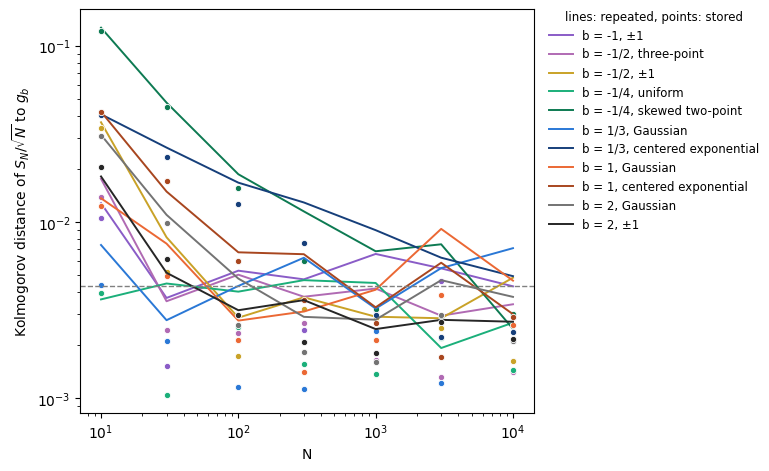

In [72]:
fig, ax = plt.subplots(figsize=(7.6, 4.6), layout="constrained")
nmP = {"rademacher": "±1", "three": "three-point", "uniform": "uniform", "two": "skewed two-point", "gauss": "Gaussian", "exp": "centered exponential"}
cols = [colP, "#b06ab3", "#c9a227", colA, "#0d7a52", colB, "#163f7a", colO, "#a8461f", "0.45", "0.15"]
for (cs_, col) in zip(cases3, cols):
    r = get1(*cs_); lab = f"b = {R(cs_[0]).limit_denominator(10)}, {nmP[cs_[1]]}"
    ax.loglog(CHECKS, sims[cs_]["ks"], "-", color=col, lw=1.4, label=lab); ax.loglog(CHECKS, r["ks"], "o", color=col, ms=4.5, mec="white", mew=0.6)
ax.axhline(0.8687/math.sqrt(MS), color="0.5", ls="--", lw=1)
ax.set_xlabel("N"); ax.set_ylabel(r"Kolmogorov distance of $S_N/\sqrt{N}$ to $g_b$")
fig.legend(loc="outside right upper", frameon=False, fontsize=8.5, title="lines: repeated, points: stored", title_fontsize=8.5)
plt.show()

**Figure (additional): the displaced start is forgotten at the rate $N^{-1/2}$.** $W_1$ between the law of $S_N/\sqrt N$ (start $S_1=4$, $b=\tfrac13$, noise $\pm1$) and $g_b$: repeated run (circles), stored run (squares), and the lower bound $4/\sqrt N$ (line).

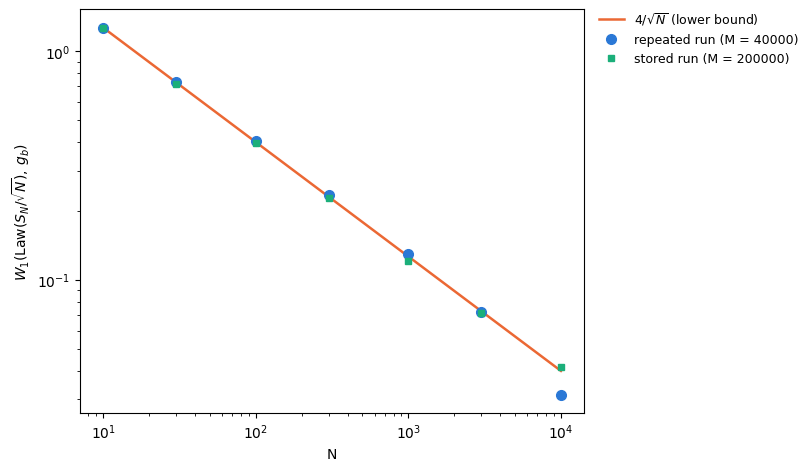

In [73]:
fig, ax = plt.subplots(figsize=(8.0, 4.6), layout="constrained")
gN = np.logspace(1, 4, 50)
ax.loglog(gN, 4/np.sqrt(gN), color=colO, lw=1.8, label=r"$4/\sqrt{N}$ (lower bound)")
ax.loglog(CHECKS, simD["w1"], "o", color=colB, ms=7, label=f"repeated run (M = {MS})")
ax.loglog(rD["N"], rD["w1"], "s", color=colA, ms=4.5, label="stored run (M = 200000)")
ax.set_xlabel("N"); ax.set_ylabel(r"$W_1(\mathrm{Law}(S_N/\sqrt{N}),\,g_b)$")
fig.legend(loc="outside right upper", frameon=False, fontsize=9)
plt.show()

## 12. The tables and figures of the manuscript, redrawn from the stored data
Tables III and IV are printed from `data/`; Figs. 1–3 are redrawn from `data/` with the same layout as in the manuscript and shown below (nothing is saved). The figures of the manuscript itself are in `figs/`.

In [74]:
nmP = {"rademacher": "±1", "three": "three-point", "uniform": "uniform", "two": "skewed two-point", "gauss": "Gaussian", "exp": "centered exponential"}
print("Table III. Kolmogorov distance between the law of S_N/Sqrt[N] and g_b (200,000 paths)\n")
print(f"{'b':>6}  {'noise':22s}" + "".join(f"{'N=' + str(n):>9s}" for n in CHECKS) + f"{'floor':>9s}")
for r in runs1:
    print(f"{str(R(r['b']).limit_denominator(10)):>6}  {nmP[r['noise']]:22s}" + "".join(f"{v:9.4f}" for v in r["ks"]) + f"{r['floor_ks']:9.4f}")
print("\nTable IV. Kolmogorov distance of the law of S_N/Sqrt[N] to g_b and to the Cauchy law (c_b = 1 + b)\n")
print(f"{'b':>4}  {'noise':10s}{'g_b, N=100':>12s}{'1000':>8s}{'10^4':>8s}{'Cauchy, 10^4':>14s}{'exact':>8s}{'floor':>8s}")
for r in sim7:
    print(f"{r['b']:4.0f}  {nmP[r['noise']]:10s}{r['ks_g'][0]:12.4f}{r['ks_g'][1]:8.4f}{r['ks_g'][2]:8.4f}{r['ks_c'][-1]:14.4f}{r['ks_g_vs_cauchy']:8.4f}{r['floor']:8.4f}")

Table III. Kolmogorov distance between the law of S_N/Sqrt[N] and g_b (200,000 paths)

     b  noise                      N=10     N=30    N=100    N=300   N=1000   N=3000  N=10000    floor
    -1  ±1                       0.0106   0.0015   0.0021   0.0024   0.0032   0.0046   0.0029   0.0020
  -1/2  three-point              0.0138   0.0024   0.0023   0.0027   0.0016   0.0013   0.0014   0.0020
  -1/2  ±1                       0.0344   0.0052   0.0017   0.0032   0.0029   0.0025   0.0016   0.0021
  -1/4  uniform                  0.0040   0.0010   0.0025   0.0016   0.0014   0.0022   0.0015   0.0019
  -1/4  skewed two-point         0.1208   0.0452   0.0156   0.0060   0.0032   0.0028   0.0030   0.0018
   1/3  Gaussian                 0.0044   0.0021   0.0012   0.0011   0.0024   0.0012   0.0021   0.0019
   1/3  centered exponential     0.0407   0.0235   0.0127   0.0076   0.0030   0.0022   0.0024   0.0017
     1  Gaussian                 0.0124   0.0049   0.0021   0.0014   0.0021   0.0038   0.

**Fig. 1.** Histogram of $S_N/\sqrt N$ at $N=10^4$ (points) and the limit law $g_b$ (line; the Cauchy law in panel (j)), with $c=1$ ($c=1+b$ in panel (j)): one panel for each interval and each boundary value of $q=(1+4b)/(1+2b)$.

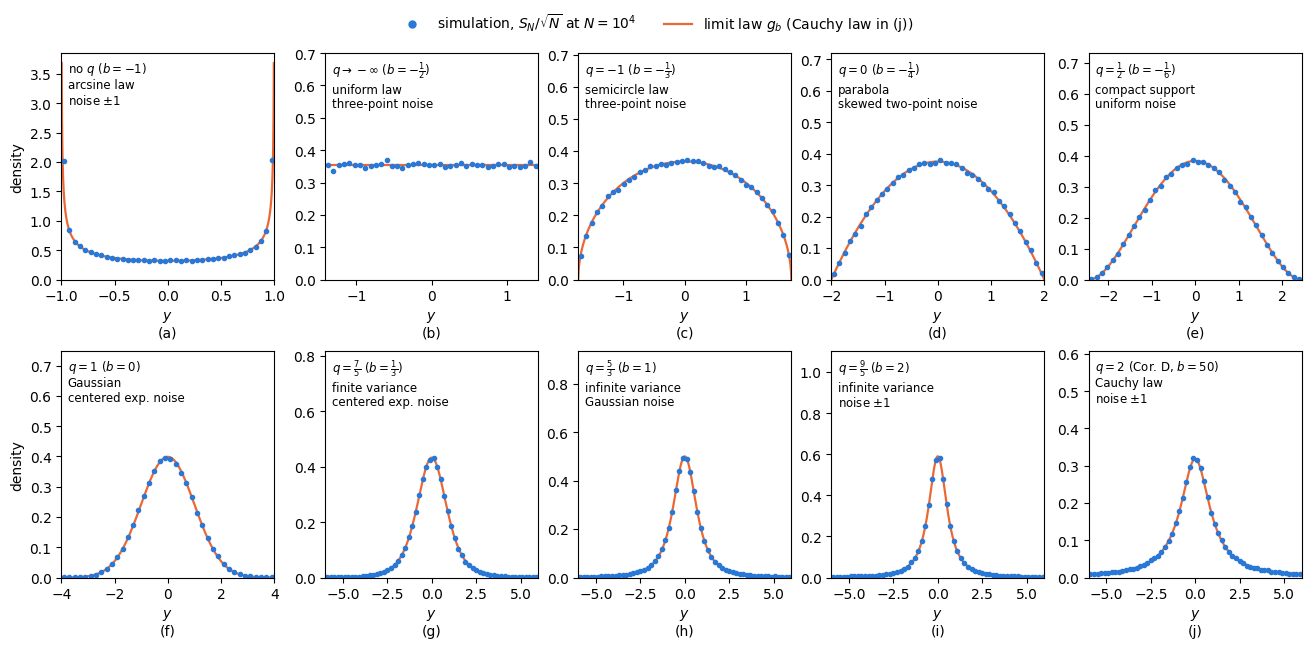

In [75]:
def histOf(b, kind):
    if abs(b + 1/3) < 1e-9: r = sim9["b-1_3"]
    elif abs(b + 1/6) < 1e-9: r = sim9["b-1_6"]
    elif b == 0: r = sim9["b0"]
    else: r = get1(b, kind)
    return np.array(r["hist_x"]), np.array(r["hist_y"])
panelSpec = [(-1.0, "rademacher", "no $q$ ($b=-1$)\narcsine law\nnoise $\\pm1$"),
             (-0.5, "three", "$q\\to-\\infty$ ($b=-\\frac{1}{2}$)\nuniform law\nthree-point noise"),
             (-1/3, "three", "$q=-1$ ($b=-\\frac{1}{3}$)\nsemicircle law\nthree-point noise"),
             (-0.25, "two", "$q=0$ ($b=-\\frac{1}{4}$)\nparabola\nskewed two-point noise"),
             (-1/6, "uniform", "$q=\\frac{1}{2}$ ($b=-\\frac{1}{6}$)\ncompact support\nuniform noise"),
             (0.0, "exp", "$q=1$ ($b=0$)\nGaussian\ncentered exp. noise"),
             (1/3, "exp", "$q=\\frac{7}{5}$ ($b=\\frac{1}{3}$)\nfinite variance\ncentered exp. noise"),
             (1.0, "gauss", "$q=\\frac{5}{3}$ ($b=1$)\ninfinite variance\nGaussian noise"),
             (2.0, "rademacher", "$q=\\frac{9}{5}$ ($b=2$)\ninfinite variance\nnoise $\\pm1$"),
             (None, "rademacher", "$q=2$ (Cor. D, $b=50$)\nCauchy law\nnoise $\\pm1$")]
fig, axs = plt.subplots(2, 5, figsize=(13, 6.4), layout="constrained"); axs = axs.ravel()
for i, (b, kind, lab) in enumerate(panelSpec):
    ax = axs[i]
    if b is None:
        hx, hy = np.array(sim8["hist_x"]), np.array(sim8["hist_y"]); f = lambda y: 1/(np.pi*(1 + y**2)); lim = 6
    else:
        hx, hy = histOf(b, kind); f = lambda y, b=b: pdfG(b, y); lim = 6 if b > 0 else (4 if b == 0 else math.sqrt(-1/b))
    sel = np.abs(hx) < lim; hx, hy = hx[sel], hy[sel]
    gx = lim*np.cos(np.linspace(math.pi, 0, 400)[1:-1]) if (b is not None and b < 0) else np.linspace(-lim, lim, 400)
    gy = f(gx); ymax = 1.9*hy.max()
    ax.plot(gx, np.where(gy <= ymax, gy, np.nan), color=colO, lw=1.6); ax.plot(hx, hy, "o", ms=3, color=colB)
    ax.set_xlim(-lim, lim); ax.set_ylim(0, ymax)
    ax.text(0.03, 0.97, lab, transform=ax.transAxes, va="top", fontsize=8.5, linespacing=1.15)
    ax.set_xlabel("$y$\n(%s)" % "abcdefghij"[i])
    if i % 5 == 0: ax.set_ylabel("density")
h1, = axs[0].plot([], [], "o", ms=5, color=colB); h2, = axs[0].plot([], [], color=colO, lw=1.6)
fig.legend([h1, h2], [r"simulation, $S_N/\sqrt{N}$ at $N=10^4$", r"limit law $g_b$ (Cauchy law in (j))"], loc="outside upper center", ncol=2, frameon=False)
plt.show()

**Fig. 2.** Tail probability $P(|S_N/\sqrt N|>x)$ at $N=10^4$ on logarithmic axes (points), and the exact tails of $g_b$ (lines), which decay like $x^{-(1+1/b)}$: exponents $4$, $2$ and $\tfrac32$. With 200,000 paths the smallest resolvable probability is $5\times10^{-6}$.

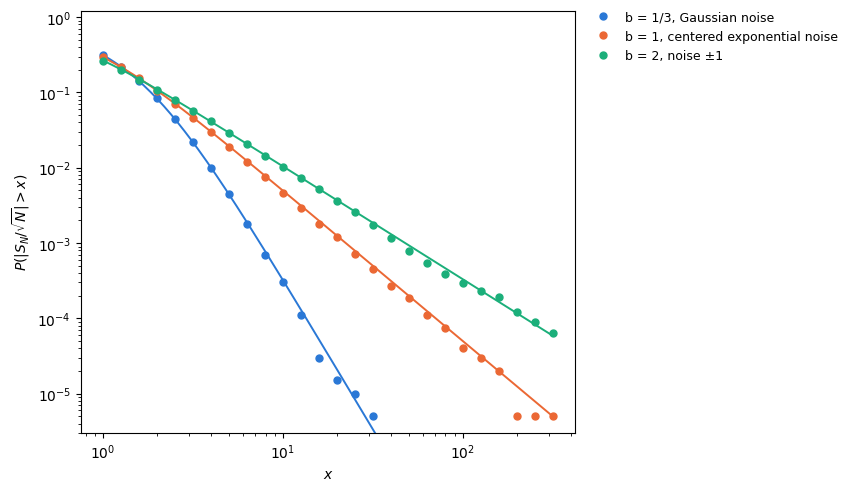

In [76]:
fig, ax = plt.subplots(figsize=(8.4, 4.8), layout="constrained")
gx = np.logspace(0, 2.5, 200)
for r, col, lab in zip(tailRuns, (colB, colO, colA), ("b = 1/3, Gaussian noise", "b = 1, centered exponential noise", "b = 2, noise ±1")):
    ax.loglog(gx, 2*(1 - cdfG(r["b"], gx)), color=col, lw=1.4)
    te = np.array(r["tail_emp"]); ok = te > 0
    ax.loglog(np.array(r["tail_x"])[ok], te[ok], "o", ms=5, color=col, label=lab)
ax.set_ylim(3e-6, 1.2); ax.set_xlabel("$x$"); ax.set_ylabel(r"$P(|S_N/\sqrt{N}|>x)$")
fig.legend(loc="outside right upper", frameon=False, fontsize=9)
plt.show()

**Fig. 3.** Kolmogorov distance between $g_b$ and the Cauchy law as a function of $b$ (line), and the measured distance of the law of $S_N/\sqrt N$ at $N=10^4$ to the Cauchy law (points; the two noise laws drawn slightly apart in $b$). Below about $0.002$ (dashed: $0.8687/\sqrt M$) a sample of 200,000 paths cannot resolve the difference.

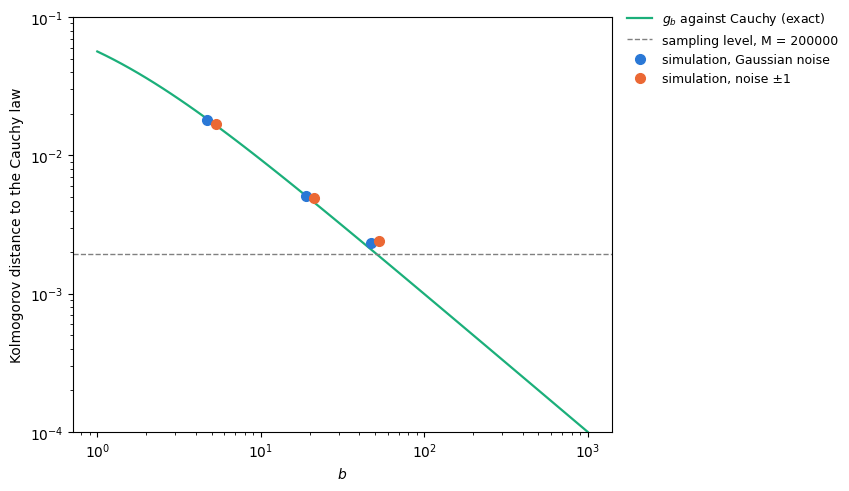

PASS   Fig. 3: the exact distance between g_b and the Cauchy law decreases with b over 1 <= b <= 1000, and b times it approaches 0.1


True

In [77]:
fig, ax = plt.subplots(figsize=(8.4, 4.8), layout="constrained")
bg = np.logspace(0, 3, 61); ax.loglog(bg, [ksExact(b) for b in bg], color=colA, lw=1.6, label="$g_b$ against Cauchy (exact)")
ax.axhline(0.8687/math.sqrt(M0), color="0.5", ls="--", lw=1, label="sampling level, M = 200000")
for kind, col, f, lab in (("gauss", colB, 0.94, "simulation, Gaussian noise"), ("rademacher", colO, 1.06, "simulation, noise ±1")):
    rs = [r for r in sim7 if r["noise"] == kind]; ax.loglog([f*r["b"] for r in rs], [r["ks_c"][-1] for r in rs], "o", ms=7, color=col, label=lab)
ax.set_xlabel("$b$"); ax.set_ylabel("Kolmogorov distance to the Cauchy law"); ax.set_ylim(1e-4, 0.1)
fig.legend(loc="outside right upper", frameon=False, fontsize=9)
plt.show()
check("Fig. 3: the exact distance between g_b and the Cauchy law decreases with b over 1 <= b <= 1000, and b times it approaches 0.1",
      all(np.diff([ksExact(b) for b in bg]) < 0) and abs(1000*ksExact(1000) - 0.1) < 0.002)

## 13. Summary: pass/fail table
All checks of Sections 1 to 12, in the order evaluated.

In [78]:
nPass = sum(results.values()); print(f"{nPass} of {len(results)} checks passed\n")
failed = [k for k, v in results.items() if not v]
if failed: print("FAILED:\n  " + "\n  ".join(failed) + "\n")
for i, (k, v) in enumerate(results.items(), 1):
    print(f"{i:4d}  {'PASS' if v else 'FAIL'}  {k[:160]}")

185 of 185 checks passed

   1  PASS  (II.2): the closed form of Z_b equals the integral of D^(-kappa) (b = 1/3, 1, 2, -1/4, -1/2, -1; c = 1, 23/10)
   2  PASS  Sec. II A: 2 kappa = 2 + 1/b; for b = -beta < 0, -kappa = 1/(2 beta) - 1 > -1 and c + b y^2 = beta (L - y)(L + y)
   3  PASS  (II.3): 1 - q = -2b/(1+2b), (1-q) B = -b/c and 1/(1-q) = -kappa, with q = (1+4b)/(1+2b) and B = (1+2b)/(2c)
   4  PASS  (II.3): the inverse relation b = (q-1)/(2(2-q))
   5  PASS  (II.3): [1-(1-q) B y^2]^(1/(1-q)) = c^kappa D^(-kappa) (symbolic, for c + b y^2 > 0)
   6  PASS  (II.3): g_b / [1-(1-q) B y^2]^(1/(1-q)) does not depend on y (b = 1/3, 1, 2, -1/4, -1/3; c = 1, 23/10)
   7  PASS  Sec. II A: for b > 0, g_b is the law of Sqrt[c/(1+b)] T_nu, nu = 1 + 1/b (b = 1/3, 1, 2; c = 1, 23/10)
   8  PASS  Sec. II A: for b < 0, g_b is the law of L(2V-1), V ~ Beta(1/(2|b|), 1/(2|b|)) (b = -1/4, -1/2, -1, -5/2; c = 1, 23/10)
   9  PASS  Table I: q(-1/4) = 0, q(1/3) = 7/5, q(1) = 5/3, q(2) = 9/5; kappa(-1/2) = 0